# Modelo OLS — preparación y experimentos de selección

Recupera evidencias históricas, prepara las matrices y ejecuta Forward AIC y BIC por características completas. Test permanece reservado.


## Dataset base y particiones persistidas
Una sola lectura de `PropUsadas_OLS.csv`. Las proporciones nominales son 70/10/20; se conservan
los cortes por meses completos y sus tamaños efectivos. Test se conserva como filas reservadas,
sin ajustar transformadores ni evaluar precios con él.


In [1]:
from pathlib import Path
import hashlib
import sys
from importlib.metadata import version

import numpy as np
import pandas as pd
from IPython.display import display

# Configuración única del paquete para ejecutar desde la raíz o el notebook.
carpeta_paquete = next((c for p in (Path.cwd(), *Path.cwd().parents)
    for c in (p, p / "Ventas/Fase1_PropUsadas")
    if (c / "scripts/__init__.py").is_file()), None)
if carpeta_paquete is None:
    raise RuntimeError("Ejecutar el notebook dentro del proyecto Moscow_EDA.")
if str(carpeta_paquete) not in sys.path:
    sys.path.insert(0, str(carpeta_paquete))
from scripts.contrato_datasets import (
    CARPETA_PROYECTO, DATA_DIR as DATOS_PROYECTO, DATASETS, SCRIPTS_DIR, RAIZ as raiz,
)
assert Path(sys.prefix).resolve() == (raiz / ".venv").resolve(), "Seleccionar el kernel de .venv."
archivo_datos = DATASETS["PropUsadas_OLS.csv"]
datos_base = pd.read_csv(archivo_datos, parse_dates=["date_posted_dt"])
datos = datos_base  # Alias de lectura; las variantes usan copias.
assert not datos.empty and datos.columns.is_unique
assert datos["id"].notna().all() and datos["id"].is_unique
assert datos["date_posted_dt"].notna().all() and datos["date_posted_dt"].is_monotonic_increasing
assert datos["price_rub"].notna().all() and datos["price_rub"].gt(0).all()
assert np.isfinite(datos["price_rub"]).all()
orden_splits = ["train", "validation", "test"]
assert datos["dataset_split"].notna().all() and set(datos["dataset_split"]) == set(orden_splits)
assert datos.groupby("date_posted_dt")["dataset_split"].nunique().eq(1).all()
assert datos.groupby("year_month")["dataset_split"].nunique().eq(1).all()
assert datos["year_month"].eq(datos["date_posted_dt"].dt.strftime("%Y-%m")).all()

conjuntos = {nombre: datos.loc[datos["dataset_split"].eq(nombre)].copy() for nombre in orden_splits}
resumen_particiones = datos.groupby("dataset_split").agg(
    observaciones=("id", "size"), desde=("date_posted_dt", "min"), hasta=("date_posted_dt", "max")
).reindex(orden_splits)
resumen_particiones["columnas"] = datos.shape[1]
resumen_particiones["porcentaje"] = resumen_particiones["observaciones"] / len(datos) * 100
for anterior, siguiente in zip(orden_splits, orden_splits[1:]):
    assert resumen_particiones.loc[anterior, "hasta"] < resumen_particiones.loc[siguiente, "desde"]
assert sum(len(d) for d in conjuntos.values()) == len(datos)
display(resumen_particiones)


,observaciones,desde,hasta,columnas,porcentaje
dataset_split,,,,,
train,34853,2020-01-01,2024-05-31,38,70.052057
validation,5258,2024-06-01,2025-01-31,38,10.568207
test,9642,2025-02-01,2026-04-29,38,19.379736


## Diccionario y características originales
El catálogo conserva el baseline original y distingue predictoras, objetivo y auxiliares.
Las características de trabajo se definen por separado; no se altera este baseline.


In [2]:
# nombre, descripción, rol, tratamiento
especificacion = [
    ("id", "Identificador único del anuncio; solo trazabilidad.", "auxiliar", "excluir"),
    ("price_rub", "Precio publicado en rublos, sin logaritmo.", "objetivo", "objetivo"),
    ("lat", "Latitud de la propiedad en grados.", "predictora", "numerica"),
    ("lon", "Longitud de la propiedad en grados.", "predictora", "numerica"),
    ("total_area", "Superficie total en m².", "predictora", "numerica"),
    ("living_area", "Superficie de la sala de estar o cuarto principal de una vivienda, destinado al descanso, el ocio y la reunión familiar o con visitas, en m². No representa la superficie habitable total del inmueble.", "predictora", "numerica"),
    ("kitchen_area", "Superficie de cocina en m².", "predictora", "numerica"),
    ("rooms", "Cantidad de habitaciones.", "predictora", "numerica"),
    ("floor", "Piso de la propiedad.", "predictora", "numerica"),
    ("total_floors", "Cantidad de pisos del edificio.", "predictora", "numerica"),
    ("building_year", "Año de construcción; nulo si era posterior al anuncio.", "predictora", "numerica"),
    ("ceiling_height", "Altura de techo en metros.", "predictora", "numerica"),
    ("metro_distance_min", "Tiempo de acceso al metro en minutos.", "predictora", "numerica"),
    ("to_center_km", "Distancia de la propiedad al centro en km.", "predictora", "numerica"),
    ("mortgage_rate_at_listing", "Tasa hipotecaria al publicar, en porcentaje.", "predictora", "numerica"),
    ("metro_lat", "Latitud de la estación de metro en grados.", "predictora", "numerica"),
    ("metro_lon", "Longitud de la estación de metro en grados.", "predictora", "numerica"),
    ("metro_year_opened", "Año de apertura de la estación.", "predictora", "numerica"),
    ("metro_to_center_km", "Distancia de la estación al centro en km.", "predictora", "numerica"),
    ("has_balcony", "Balcón: 0=no, 1=sí.", "predictora", "numerica"),
    ("metro_distance_type", "Modalidad de acceso: 0=a pie, 1=transporte.", "predictora", "numerica"),
    ("seller_type", "Vendedor: 0=propietario, 1=agencia.", "predictora", "numerica"),
    ("building_year_inconsistent", "1 si el año de construcción informado era posterior al anuncio.", "predictora", "numerica"),
    ("months_since_start", "Tendencia mensual con enero de 2020 igual a cero.", "predictora", "numerica"),
    ("n_listings_secondary_lag1", "Anuncios usados del distrito/okrug en el mes anterior.", "predictora", "numerica"),
    ("n_listings_newbuild_lag1", "Anuncios nuevos del distrito/okrug en el mes anterior.", "predictora", "numerica"),
    ("n_listings_rental_lag1", "Anuncios de alquiler del distrito/okrug en el mes anterior.", "predictora", "numerica"),
    ("cbr_key_rate_pct_lag1", "Tasa de referencia del BCR del mes anterior, en porcentaje.", "predictora", "numerica"),
    ("lag1_unavailable", "1 si falta al menos un indicador del mes anterior.", "predictora", "numerica"),
    ("district", "Distrito de Moscú.", "predictora", "onehot"),
    ("building_type", "Tipo de construcción del edificio.", "predictora", "onehot"),
    ("renovation", "Estado de renovación; sin escala ordinal impuesta.", "predictora", "onehot"),
    ("metro_line", "Línea de metro asociada al anuncio.", "predictora", "onehot"),
    ("month_of_year", "Mes calendario 1–12; se trata como categoría estacional.", "predictora", "onehot"),
    ("okrug", "División administrativa; redundante con district, solo auditoría.", "auxiliar", "excluir"),
    ("date_posted_dt", "Fecha principal para ordenar y construir folds temporales.", "auxiliar", "excluir"),
    ("year_month", "Período YYYY-MM para agrupar meses completos.", "auxiliar", "excluir"),
    ("dataset_split", "Asignación persistida: train, validation o test.", "auxiliar", "excluir"),
]
diccionario = pd.DataFrame(especificacion, columns=["nombre", "descripcion", "rol", "tratamiento"])
assert diccionario["nombre"].is_unique
assert set(diccionario["nombre"]) == set(datos), "El esquema del CSV cambió: revisar el catálogo."
diccionario["tipo"] = diccionario["nombre"].map(datos.dtypes.astype(str))
display(diccionario.groupby("rol").size().rename("variables").to_frame())

objetivo = diccionario.loc[diccionario["rol"].eq("objetivo"), "nombre"].item()
columnas_numericas = diccionario.loc[diccionario["tratamiento"].eq("numerica"), "nombre"].tolist()
columnas_ohe = diccionario.loc[diccionario["tratamiento"].eq("onehot"), "nombre"].tolist()
predictoras = columnas_numericas + columnas_ohe
auxiliares = diccionario.loc[diccionario["rol"].eq("auxiliar"), "nombre"].tolist()
prohibidas = {
    "price_per_sqm", "secondary_price_per_sqm", "newbuild_price_per_sqm",
    "rental_price_per_sqm_monthly", "secondary_mom_change_pct", "newbuild_mom_change_pct",
    "n_listings_secondary", "n_listings_newbuild", "n_listings_rental",
    "cbr_key_rate_pct", "avg_mortgage_rate_pct",
}
assert not set(predictoras).intersection(prohibidas | set(auxiliares) | {objetivo})
assert all(pd.api.types.is_numeric_dtype(datos[c]) for c in columnas_numericas)
predictoras_base = list(predictoras)


,variables
rol,
auxiliar,5
objetivo,1
predictora,32


## MLflow y DagsHub
Consulta de resultados y transformaciones existentes, con credenciales del entorno. Esta preparación no modifica Runs ni artefactos.


In [3]:
import os
import subprocess
from dotenv import load_dotenv

archivo_env = raiz / ".env"
if archivo_env.is_file():
    assert subprocess.run(["git", "check-ignore", "-q", ".env"], cwd=raiz, capture_output=True).returncode == 0
    assert subprocess.run(["git", "ls-files", "--error-unmatch", ".env"], cwd=raiz, capture_output=True).returncode != 0
    load_dotenv(archivo_env, override=False)
assert os.environ.get("DAGSHUB_USER_TOKEN", "").strip(), "Definir DAGSHUB_USER_TOKEN sin incluirlo en el notebook."

DAGSHUB_OWNER = "matiasgastonlonghino"
DAGSHUB_REPO = "MOSCOW_IDA"
NOMBRE_EXPERIMENTO = "Ventas_Propiedades_Usadas"
TRACKING_URI = f"https://dagshub.com/{DAGSHUB_OWNER}/{DAGSHUB_REPO}.mlflow"
os.environ["MLFLOW_TRACKING_USERNAME"] = os.environ.get("DAGSHUB_USERNAME") or DAGSHUB_OWNER
os.environ["MLFLOW_TRACKING_PASSWORD"] = os.environ["DAGSHUB_USER_TOKEN"]
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"
os.environ["MLFLOW_HTTP_REQUEST_TIMEOUT"] = "30"
os.environ["MLFLOW_HTTP_REQUEST_MAX_RETRIES"] = "1"

import mlflow
from mlflow.tracking import MlflowClient

assert mlflow.active_run() is None, "Finalizar el Run activo antes de cambiar la configuración."
mlflow.set_tracking_uri(TRACKING_URI)
cliente_mlflow = MlflowClient(tracking_uri=TRACKING_URI)
_ = cliente_mlflow.search_experiments(max_results=1)
experimento_existente = cliente_mlflow.get_experiment_by_name(NOMBRE_EXPERIMENTO)
if experimento_existente is None or experimento_existente.lifecycle_stage != "active":
    raise RuntimeError("Debe existir Ventas_Propiedades_Usadas; no se crean experimentos nuevos.")
print("Conexión autenticada de lectura verificada:", mlflow.get_tracking_uri())
print("Experimento:", NOMBRE_EXPERIMENTO,
      "(existente)")
print("Versiones:", {p: version(p) for p in ["pandas", "scikit-learn", "mlflow", "python-dotenv"]})


Conexión autenticada de lectura verificada: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow
Experimento: Ventas_Propiedades_Usadas (existente)
Versiones: {'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'mlflow': '3.17.1', 'python-dotenv': '1.2.4'}


## Funciones reutilizables
Preprocesamiento, ocho métricas, OLS, CV temporal, agrupamientos y registro están centralizados.
Imputación, encoding, escalado opcional y Duan se ajustarán solo con el entrenamiento correspondiente.
R² ajustado en RUB es descriptivo; los AIC/BIC históricos usan likelihood lognormal en RUB con
Jacobiano. Los diagnósticos nativos de Train en log(RUB) se conservan en los Runs de los SET.


In [4]:
import json
from tempfile import TemporaryDirectory
from IPython.display import Markdown, HTML

carpeta_notebook = CARPETA_PROYECTO
from scripts.experimentos_ols import (
    crear_preprocesador, evaluar_regresion, tabla_metricas, ajustar_ols,
    validacion_temporal, estimar_efectos_distrito, agrupar_efectos,
    registrar_experimento, recuperar_runs, tabla_markdown,
)
from scripts.transformaciones_experimentales import (
    ARTEFACTO_MAPAS, huella_tabla, huella_json, contexto_entrenamiento,
    recuperar_agrupamiento, leer_json_remoto, preparar_df_seleccionado,
    preparar_fold_seleccionado,
)

ESCALAR = False
N_FOLDS, MESES_VALID_FOLD = 5,6
config_preprocesamiento = {
    "imputacion_numerica":"median", "imputacion_categorica":"most_frequent",
    "keep_empty_features":True, "ohe_drop":"first", "ohe_unknown":"ignore",
    "escalar":ESCALAR, "objetivo":objetivo, "escala_metricas":"RUB",
    "particion":"dataset_split_persistido",
}
huella_datos = hashlib.sha256(archivo_datos.read_bytes()).hexdigest()
huella_base_memoria = huella_tabla(datos_base)
cache_transformaciones = {}
RUNS_REFERENCIA = {'Baseline original': '03bf0a40212846eebf7eb00d68f3c634', 'Baseline log': 'ff680a2eb84d4dcb9d1bb64b2ac55036', 'KMeans K=3': '38d09624693e4e9eac36c14c60ccba12', 'KMeans K=4': '33c1f3a196c543ca8776a92db9523827', 'KMeans K=5': '7acb296b04c24338abd5af4bc12c7fa9', 'KMeans K=6': 'f1429a8e41144005ad0563a74f15d687', 'KMeans K=7': 'ef7ee441b0f941609ed81891eb6a2801', 'KMeans K=8': 'ab4ff01bcb544784bf2e33312e128c29', 'KMeans K=9': '86d6fdec3eb349d1a11ed7a930ccb2f8', 'KMeans K=10': '29934496f8e04aeda1819706460b82dd', 'Ward K=3': 'ebce827914b44a15aead93ed5798234a', 'Ward K=4': '51ef3dcdf4294391bbb0b220f4d2727d', 'Ward K=5': '81e87497a40f491eb537863518009aae', 'Ward K=6': 'e9a6012ae7a2451c93e8ef3a2ce01086', 'Ward K=7': '85c942d52cd745deaa617273cfecb2ae', 'Ward K=8': '3025eb1238a843e3b128a87db8835dfb', 'Ward K=9': '27548a8e778346789a16e9591014c086', 'Ward K=10': '4d66a2acee91452884763c2719d456b6', 'Sin tasa al publicar': 'a35c2d9343e1419a914c85fc41675313', 'Sin CBR LAG1': 'ddd9461f58154230a88e05de1bd9c3a1', 'Sin ambas tasas': 'e17d481dee0a44eda77e594a31e37004', 'Sin anuncios secundarios LAG1': '2aedccfc93c8447288a55518925ef1ba', 'Auditoría contemporáneo ausente': 'fd7997671d3b418686f8adc878c5a696'}

def enlace_run(nombre):
    return f"[{nombre}]({TRACKING_URI}/#/experiments/1/runs/{RUNS_REFERENCIA[nombre]})"


## Evidencias históricas — baselines y exclusiones
Se recuperan los resultados originales sin reajustar ni registrar modelos. Los SET de tasas
y anuncios fueron independientes; sus métricas no describen la combinación seleccionada abajo.
La CV de referencia se conserva en los artefactos de los Runs nuevos y no modificó el baseline.


In [5]:
runs_historicos = recuperar_runs(cliente_mlflow,RUNS_REFERENCIA,huella_datos)
with TemporaryDirectory(prefix="ols_historia_cv_") as temporal:
    ruta = cliente_mlflow.download_artifacts(RUNS_REFERENCIA["Sin anuncios secundarios LAG1"],
        "resultados/cv_temporal_todas_configuraciones.json",temporal)
    cv_historica = pd.read_json(ruta)
cv_resumen = cv_historica.groupby("configuracion").agg(
    mae_media=("validation_mae_rub","mean"),mae_sd=("validation_mae_rub","std"))
cv_claves = {"Baseline log":"A","Sin tasa al publicar":"B","Sin CBR LAG1":"C",
             "Sin ambas tasas":"D","Sin anuncios secundarios LAG1":"Anuncios"}
filas_historia = []
mae_referencia = runs_historicos["Baseline log"].data.metrics["validation_mae_rub"]
for nombre in ["Baseline original",*cv_claves]:
    run = runs_historicos[nombre]
    m,p = run.data.metrics,run.data.params
    cv = cv_resumen.loc[cv_claves[nombre]] if nombre in cv_claves else None
    filas_historia.append({"Modelo / Run":enlace_run(nombre),
        "Características":int(p["n_caracteristicas_originales"]),"Columnas OLS":int(p["n_columnas_predictoras"]),
        "MAE Validation RUB":m["validation_mae_rub"],"RMSE Validation RUB":m["validation_rmse_rub"],
        "R² Validation":m["validation_r2"],"MAPE Validation %":m["validation_mape_pct"],
        "CV MAE media ± SD RUB":f"{cv['mae_media']:,.2f} ± {cv['mae_sd']:,.2f}" if cv is not None else "No evaluada",
        "Δ MAE vs log %":100*(m["validation_mae_rub"]/mae_referencia-1)})
historia_modelos = pd.DataFrame(filas_historia)
display(Markdown(tabla_markdown(historia_modelos,decimales=6)))
display(Markdown("**Conclusiones:** log(price) superó al objetivo original. En tasas, D —sin ambas— "
    "mejoró MAE Validation 4,71 % y tuvo menor SD de CV; C obtuvo la menor media de CV. "
    "Quitar el LAG de anuncios aumentó MAE solo 11,05 RUB (0,000556 %), con diferencias temporales mínimas y mixtas; "
    "se conserva como candidata de simplicidad, sin afirmar equivalencia estadística. "
    "La auditoría de la variable contemporánea ausente no fue una ablación: "
    +enlace_run("Auditoría contemporáneo ausente")+"."))


| Modelo / Run | Características | Columnas OLS | MAE Validation RUB | RMSE Validation RUB | R² Validation | MAPE Validation % | CV MAE media ± SD RUB | Δ MAE vs log % |
|---|---|---|---|---|---|---|---|---|
| [Baseline original](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/03bf0a40212846eebf7eb00d68f3c634) | 32 | 185 | 2,582,236.927843 | 3,804,058.411717 | 0.845735 | 21.839803 | No evaluada | 30.046660 |
| [Baseline log](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/ff680a2eb84d4dcb9d1bb64b2ac55036) | 32 | 185 | 1,985,623.415320 | 2,924,096.550772 | 0.908850 | 14.462791 | 1,460,991.39 ± 108,791.74 | 0.000000 |
| [Sin tasa al publicar](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/a35c2d9343e1419a914c85fc41675313) | 31 | 184 | 1,948,242.219768 | 2,878,620.991659 | 0.911663 | 14.168789 | 1,468,248.64 ± 117,921.54 | -1.882592 |
| [Sin CBR LAG1](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/ddd9461f58154230a88e05de1bd9c3a1) | 31 | 184 | 2,006,684.137961 | 2,953,249.397129 | 0.907023 | 14.624214 | 1,432,333.28 ± 98,710.26 | 1.060660 |
| [Sin ambas tasas](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/e17d481dee0a44eda77e594a31e37004) | 30 | 183 | 1,892,014.760854 | 2,803,150.908084 | 0.916234 | 13.732402 | 1,435,853.61 ± 71,743.57 | -4.714321 |
| [Sin anuncios secundarios LAG1](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/2aedccfc93c8447288a55518925ef1ba) | 31 | 184 | 1,985,634.463161 | 2,923,935.745870 | 0.908860 | 14.462804 | 1,460,961.20 ± 108,792.41 | 0.000556 |

**Conclusiones:** log(price) superó al objetivo original. En tasas, D —sin ambas— mejoró MAE Validation 4,71 % y tuvo menor SD de CV; C obtuvo la menor media de CV. Quitar el LAG de anuncios aumentó MAE solo 11,05 RUB (0,000556 %), con diferencias temporales mínimas y mixtas; se conserva como candidata de simplicidad, sin afirmar equivalencia estadística. La auditoría de la variable contemporánea ausente no fue una ablación: [Auditoría contemporáneo ausente](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/fd7997671d3b418686f8adc878c5a696).

## Evidencias históricas — K-Means y Ward
Ambos métodos agruparon efectos de un OLS preliminar con las características originales.
Los mapas de Train completo y de cada fold están preservados como JSON. Las etiquetas de grupos
son internas a cada algoritmo. Se mantienen todos los Runs, métricas y figuras originales.


In [6]:
filas_grupos = []
for k in range(3,11):
    km = runs_historicos[f"KMeans K={k}"].data
    ward = runs_historicos[f"Ward K={k}"].data
    filas_grupos.append({"K":k,"MAE Validation K-Means RUB":km.metrics["validation_mae_rub"],
        "MAE Validation Ward RUB":ward.metrics["validation_mae_rub"],
        "CV MAE K-Means RUB":km.metrics["cv_mae_mean"],"CV MAE Ward RUB":ward.metrics["cv_mae_mean"],
        "Columnas K-Means":int(km.params["n_columnas_predictoras"]),
        "Columnas Ward":int(ward.params["n_columnas_predictoras"]),
        "Runs":enlace_run(f"KMeans K={k}")+" · "+enlace_run(f"Ward K={k}")})
historia_grupos = pd.DataFrame(filas_grupos)
display(Markdown(tabla_markdown(historia_grupos,decimales=2)))
km8 = runs_historicos["KMeans K=8"].data.metrics
km10 = runs_historicos["KMeans K=10"].data.metrics
delta_k8_k10 = 100*(km10["validation_mae_rub"]/km8["validation_mae_rub"]-1)
display(Markdown(f"**Decisión geográfica:** se adopta provisionalmente K-Means K=8 por preferencia "
    f"de compacidad y estabilidad (ARI {km8['cv_ari_mean']:.3f}). K=10 redujo MAE Validation "
    f"otro {abs(delta_k8_k10):.2f} % con dos columnas adicionales; Ward K=10 fue el finalista de Ward. "
    "Esta elección no implica que K=8 tuviera el menor MAE ni que la combinación posterior esté validada."))


| K | MAE Validation K-Means RUB | MAE Validation Ward RUB | CV MAE K-Means RUB | CV MAE Ward RUB | Columnas K-Means | Columnas Ward | Runs |
|---|---|---|---|---|---|---|---|
| 3 | 2,651,725.92 | 2,406,185.50 | 2,027,211.83 | 1,968,476.75 | 59 | 59 | [KMeans K=3](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/38d09624693e4e9eac36c14c60ccba12) · [Ward K=3](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/ebce827914b44a15aead93ed5798234a) |
| 4 | 2,325,779.28 | 2,363,540.81 | 1,852,168.41 | 1,924,773.22 | 60 | 60 | [KMeans K=4](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/33c1f3a196c543ca8776a92db9523827) · [Ward K=4](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/51ef3dcdf4294391bbb0b220f4d2727d) |
| 5 | 2,223,960.04 | 2,251,630.98 | 1,732,959.81 | 1,736,075.02 | 61 | 61 | [KMeans K=5](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/7acb296b04c24338abd5af4bc12c7fa9) · [Ward K=5](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/81e87497a40f491eb537863518009aae) |
| 6 | 2,185,984.12 | 2,207,745.89 | 1,703,882.74 | 1,672,804.59 | 62 | 62 | [KMeans K=6](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/f1429a8e41144005ad0563a74f15d687) · [Ward K=6](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/e9a6012ae7a2451c93e8ef3a2ce01086) |
| 7 | 2,075,714.69 | 2,093,021.69 | 1,604,354.17 | 1,601,549.82 | 63 | 63 | [KMeans K=7](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/ef7ee441b0f941609ed81891eb6a2801) · [Ward K=7](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/85c942d52cd745deaa617273cfecb2ae) |
| 8 | 2,072,596.00 | 2,051,833.45 | 1,560,823.91 | 1,567,573.95 | 64 | 64 | [KMeans K=8](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/ab4ff01bcb544784bf2e33312e128c29) · [Ward K=8](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/3025eb1238a843e3b128a87db8835dfb) |
| 9 | 2,052,344.61 | 2,045,293.38 | 1,554,593.50 | 1,539,066.89 | 65 | 65 | [KMeans K=9](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/86d6fdec3eb349d1a11ed7a930ccb2f8) · [Ward K=9](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/27548a8e778346789a16e9591014c086) |
| 10 | 2,042,408.62 | 2,017,926.30 | 1,525,196.09 | 1,527,623.25 | 66 | 66 | [KMeans K=10](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/29934496f8e04aeda1819706460b82dd) · [Ward K=10](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/4d66a2acee91452884763c2719d456b6) |

**Decisión geográfica:** se adopta provisionalmente K-Means K=8 por preferencia de compacidad y estabilidad (ARI 0.952). K=10 redujo MAE Validation otro 1.46 % con dos columnas adicionales; Ward K=10 fue el finalista de Ward. Esta elección no implica que K=8 tuviera el menor MAE ni que la combinación posterior esté validada.

## Configuración seleccionada para los próximos experimentos

Se utilizará provisionalmente OLS con `log(price_rub)` y Duan, K-Means K=8 y `district_group`
como predictora geográfica. Se excluyen `mortgage_rate_at_listing`, `cbr_key_rate_pct_lag1`
y `n_listings_secondary_lag1`, conservando los otros LAG y `lag1_unavailable`.

**Esta combinación todavía no se evaluó conjuntamente.** El −4,71 % de MAE del experimento
de tasas y el +0,000556 % del experimento individual del LAG justifican decisiones separadas;
no son métricas del DataFrame consolidado. El mapa K=8 conserva el OLS preliminar original:
la exclusión posterior no cambia retrospectivamente las variables que lo originaron.


In [7]:
EXCLUIR_TRABAJO = ["mortgage_rate_at_listing","cbr_key_rate_pct_lag1","n_listings_secondary_lag1"]
RUN_KMEANS8 = RUNS_REFERENCIA["KMeans K=8"]
configuracion_seleccionada = {
    "version":1,"modelo":"OLS","target_original":"price_rub","target_entrenamiento":"log(price_rub)",
    "retransformacion":"exp(pred_log) * Duan estimado en Train",
    "agrupamiento":{"algoritmo":"KMeans","K":8,"run_id":RUN_KMEANS8,
        "artefacto":ARTEFACTO_MAPAS,"contexto":"train_completo",
        "predictoras_ols_preliminar":list(predictoras_base)},
    "excluir":list(EXCLUIR_TRABAJO),"dataset_sha256":huella_datos,
    "conservar":["n_listings_newbuild_lag1","n_listings_rental_lag1","lag1_unavailable"],
    "evaluada_conjuntamente":False,
    "fundamento_experimentos_independientes":{
        "tasas_run":RUNS_REFERENCIA["Sin ambas tasas"],"anuncios_lag1_run":RUNS_REFERENCIA["Sin anuncios secundarios LAG1"],
        "nota":"No atribuir a esta combinación las métricas de los experimentos individuales."},
}


## DataFrame de trabajo — Configuración seleccionada

Se recupera el mapa K-Means K=8 aprendido solo con Train y se aplica sin clustering.
`df_trabajo` es una copia independiente: pierde físicamente las tres columnas descartadas,
conserva precio y particiones originales y mantiene `district` únicamente como auxiliar.
`district_group` es categórica, con las ocho categorías definidas por el mapa de Train.
La asignación a las filas reservadas de Test es solo preparación estructural: no se ajusta
ningún transformador ni se predicen o evalúan sus precios. No se aplica One-Hot global.


In [8]:
contexto_mapa_completo = contexto_entrenamiento(conjuntos["train"],dataset_sha256=huella_datos,
    caracteristicas=predictoras_base,numericas=columnas_numericas,categoricas=columnas_ohe,
    preprocesamiento=config_preprocesamiento)
agrupamiento_k8 = recuperar_agrupamiento(cliente_mlflow,algoritmo="KMeans",k=8,run_id=RUN_KMEANS8,
    contexto_esperado=contexto_mapa_completo,cache=cache_transformaciones)
df_trabajo,predictoras_trabajo = preparar_df_seleccionado(datos_base,agrupamiento_k8,EXCLUIR_TRABAJO,
    predictoras_base=predictoras_base,uso="preparacion_reservada")
categoricas_trabajo = ["district_group" if c=="district" else c for c in columnas_ohe]
numericas_trabajo = [c for c in columnas_numericas if c not in EXCLUIR_TRABAJO]
auxiliares_trabajo = [c for c in df_trabajo if c not in predictoras_trabajo and c!=objetivo]
df_trabajo_train = df_trabajo.loc[df_trabajo["dataset_split"].eq("train")].copy()
df_trabajo_validation = df_trabajo.loc[df_trabajo["dataset_split"].eq("validation")].copy()
assert len(df_trabajo)==len(datos_base) and df_trabajo.index.equals(datos_base.index)
assert not set(EXCLUIR_TRABAJO).intersection(df_trabajo.columns)
assert set(configuracion_seleccionada["conservar"]) <= set(predictoras_trabajo)
assert "district" not in predictoras_trabajo and "district" in auxiliares_trabajo
assert "district_group" in categoricas_trabajo
assert df_trabajo_train["district_group"].nunique()==8 and not df_trabajo["district_group"].isna().any()
assert not datos_base.loc[datos_base["dataset_split"].eq("train"),"district"].map(agrupamiento_k8["mapa"]).isna().any()
assert set(predictoras_trabajo)==set(numericas_trabajo+categoricas_trabajo)
pd.testing.assert_series_equal(df_trabajo[objetivo],datos_base[objetivo])
assert huella_tabla(datos_base)==huella_base_memoria


## Uso posterior y validación temporal sin leakage

Para el ajuste completo y Validation externa se utilizarán `df_trabajo_train`,
`df_trabajo_validation` y `predictoras_trabajo`. Dentro de CV se parte de `datos_base`
y se llama a `preparar_fold_trabajo(fold)`: recupera el mapa exclusivo de ese entrenamiento
y aplica después las mismas exclusiones. No se reutiliza el mapa de Train completo en CV.

Se conserva expresamente la definición original de los efectos de distrito. Si se cambia
ese OLS preliminar o el preprocesamiento, la recuperación rechaza el contexto incompatible;
recalcular agrupamientos requerirá otro experimento. No se ejecuta ahora Forward, Backward,
Best Subset, Ridge, LASSO ni entrenamiento del modelo combinado.


In [9]:
def preparar_fold_trabajo(fold):
    return preparar_fold_seleccionado(datos_base,fold,cliente=cliente_mlflow,run_id=RUN_KMEANS8,
        excluir=EXCLUIR_TRABAJO,dataset_sha256=huella_datos,predictoras_base=predictoras_base,
        numericas=columnas_numericas,categoricas=columnas_ohe,preprocesamiento=config_preprocesamiento,
        n_folds=N_FOLDS,meses_validacion=MESES_VALID_FOLD,cache=cache_transformaciones)

# La sección final ajusta el preprocesador con Train y expone preparar_matrices_fold(fold).


## Trazabilidad de la configuración provisional
Se verifica en modo lectura el artefacto ya registrado. La combinación continúa sin evaluación predictiva conjunta.


In [10]:
configuracion_seleccionada["predictoras_trabajo"] = list(predictoras_trabajo)
configuracion_seleccionada["contexto_mapa_sha256"] = huella_json(contexto_mapa_completo)
configuracion_seleccionada["id_transformacion"] = agrupamiento_k8["id_transformacion"]
configuracion_seleccionada["ids_folds"] = [f"{RUN_KMEANS8}:fold_{f}" for f in range(1,N_FOLDS+1)]
configuracion_seleccionada["dimensiones_preparadas"] = {
    "filas":len(df_trabajo),"columnas":len(df_trabajo.columns),"predictoras":len(predictoras_trabajo)}
configuracion_md = ("# Configuración provisional para Feature Selection\n\n"
    +f"OLS log(price_rub), Duan, K-Means K=8. Run de origen: {RUN_KMEANS8}.\n\n"
    +"Exclusiones: "+", ".join(EXCLUIR_TRABAJO)+".\n\n"
    +"Decisiones independientes: quitar ambas tasas redujo MAE Validation 4,71 %; quitar el LAG de "
     "anuncios lo incrementó 0,000556 %. K=8 es la representación geográfica provisional elegida.\n\n"
    +"**La combinación no se evaluó conjuntamente y no tiene métricas predictivas propias.**\n\n"
    +"El mapa se aprendió solo con Train, usando las características originales del baseline. "
     "En CV se deben recuperar los mapas de cada fold; las exclusiones se aplican después. "
     "No se exportan propiedades ni se ajustan transformadores sobre Test.")
carpeta_config = "configuraciones_provisionales"
ruta_config = carpeta_config+"/kmeans8_sin_tasas_sin_secondary_lag1_v1.json"
ruta_nota = carpeta_config+"/kmeans8_sin_tasas_sin_secondary_lag1_v1.md"
assert leer_json_remoto(cliente_mlflow,RUN_KMEANS8,ruta_config)==configuracion_seleccionada
assert hashlib.sha256(archivo_datos.read_bytes()).hexdigest()==huella_datos
assert huella_tabla(datos_base)==huella_base_memoria
display(Markdown("Configuración provisional existente verificada en "+enlace_run("KMeans K=8")+". Solo lectura."))


Configuración provisional existente verificada en [KMeans K=8](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/ab4ff01bcb544784bf2e33312e128c29). Solo lectura.

## DataFrame consolidado — antes de One-Hot Encoding


In [11]:
display(Markdown(f"**df_trabajo:** {len(df_trabajo):,} filas, {df_trabajo.shape[1]} columnas y "
    f"{len(predictoras_trabajo)} características conceptuales. Se conserva independiente de las matrices numéricas."))
display(HTML('<div style="overflow-x:auto;max-width:100%">'
    +df_trabajo.head(10).to_html(index=False,float_format=lambda v:f"{v:,.3f}")+'</div>'))
assert huella_tabla(datos_base)==huella_base_memoria


**df_trabajo:** 49,753 filas, 36 columnas y 29 características conceptuales. Se conserva independiente de las matrices numéricas.

id,price_rub,lat,lon,total_area,living_area,kitchen_area,rooms,floor,total_floors,building_year,ceiling_height,metro_distance_min,to_center_km,metro_lat,metro_lon,metro_year_opened,metro_to_center_km,has_balcony,metro_distance_type,seller_type,building_year_inconsistent,months_since_start,n_listings_newbuild_lag1,n_listings_rental_lag1,lag1_unavailable,district,building_type,renovation,metro_line,month_of_year,okrug,date_posted_dt,year_month,dataset_split,district_group
S000598,11678000,55.881,37.616,99.600,67.900,15.500,4,3,17,"1,971.000",2.500,34,14.160,55.854,37.653,1978,11.340,0,1,1,0,0,NaN,NaN,1,Yuzhnoye Medvedkovo,khrushchev,designer,Kaluzhsko-Rizhskaya,1,SVAO,2020-01-01,2020-01,train,G04
S001135,13501000,55.717,37.651,76.100,45.600,13.900,2,5,9,"2,011.000",2.700,15,4.560,55.710,37.623,1983,4.860,0,0,1,0,0,NaN,NaN,1,Danilovsky,modern_panel,cosmetic,Serpukhovsko-Timiryazevskaya,1,YuAO,2020-01-01,2020-01,train,G05
S005517,6733000,55.627,37.628,87.100,54.800,7.100,3,9,17,"2,004.000",2.700,32,14.160,55.655,37.603,1983,11.020,0,1,1,0,0,NaN,NaN,1,Chertanovo Tsentralnoye,modern_panel,no_renovation,Serpukhovsko-Timiryazevskaya,1,YuAO,2020-01-01,2020-01,train,G03
S006770,1927000,55.396,37.510,47.600,31.800,13.300,1,10,17,NaN,2.700,189,40.360,55.759,37.752,1979,8.200,0,1,1,1,0,NaN,NaN,1,Shchapovskoye,monolith,cosmetic,Kalininskaya,1,TAO,2020-01-01,2020-01,train,G01
S011704,7701000,55.797,37.630,52.200,30.700,8.300,1,11,25,"1,971.000",2.800,31,4.770,55.757,37.660,1995,2.450,1,1,0,0,0,NaN,NaN,1,Alekseevsky,brick,cosmetic,Lyublinsko-Dmitrovskaya,1,SVAO,2020-01-01,2020-01,train,G05
S014492,3514000,55.703,37.851,41.800,24.700,10.100,1,21,22,"1,984.000",2.800,40,15.460,55.759,37.752,1979,8.200,1,1,0,0,0,NaN,NaN,1,Kosino-Ukhtomsky,brick,cosmetic,Kalininskaya,1,VAO,2020-01-01,2020-01,train,G03
S015859,11669000,55.820,37.741,59.300,34.800,15.800,2,2,17,"2,017.000",2.700,3,10.490,55.796,37.716,1965,7.560,1,0,1,0,0,NaN,NaN,1,Preobrazhenskoye,monolith,no_renovation,Sokolnicheskaya,1,VAO,2020-01-01,2020-01,train,G05
S019272,5746000,55.936,37.519,79.900,48.400,13.300,3,25,25,"1,963.000",2.700,61,21.170,55.819,37.498,1964,10.560,1,1,0,0,0,NaN,NaN,1,Severny,khrushchev,cosmetic,Zamoskvoretskaya,1,SVAO,2020-01-01,2020-01,train,G03
S019502,8155000,55.629,37.685,53.600,33.800,9.300,1,3,17,"2,001.000",3.000,33,14.410,55.710,37.623,1983,4.860,1,1,1,0,0,NaN,NaN,1,Moskvorechye-Saburovo,monolith,euro,Serpukhovsko-Timiryazevskaya,1,YuAO,2020-01-01,2020-01,train,G04
S021402,12641000,55.773,37.487,60.800,39.800,10.300,2,7,17,"2,002.000",2.700,40,8.650,55.770,37.596,1938,2.360,1,1,1,0,0,NaN,NaN,1,Khoroshyovo-Mnyovniki,brick,euro,Zamoskvoretskaya,1,SZAO,2020-01-01,2020-01,train,G05


## One-Hot Encoding y bloques de características
Codificación ajustada con Train. Selección posterior por características completas; Test permanece reservado.


In [12]:
def preparar_matrices_feature_selection(train, validation):
    # Reutilizar imputación y OHE existentes; no cambiar ninguna regla del DataFrame consolidado.
    assert train.columns.is_unique and validation.columns.is_unique
    assert train["dataset_split"].eq("train").all()
    assert validation["dataset_split"].isin(["train","validation"]).all()
    assert train["date_posted_dt"].max()<validation["date_posted_dt"].min()
    assert train.index.intersection(validation.index).empty
    assert train.attrs["transformacion"]["id"]==validation.attrs["transformacion"]["id"]
    assert not set(EXCLUIR_TRABAJO).intersection(predictoras_trabajo)
    assert "district" not in predictoras_trabajo and objetivo not in predictoras_trabajo
    prepro = crear_preprocesador(numericas=numericas_trabajo,categoricas=categoricas_trabajo,escalar=ESCALAR)
    matrices = {"train":prepro.fit_transform(train[predictoras_trabajo])}
    matrices["validation"] = prepro.transform(validation[predictoras_trabajo])
    assert matrices["train"].columns.equals(matrices["validation"].columns)
    for split,matriz in matrices.items():
        assert matriz.columns.is_unique and all(pd.api.types.is_numeric_dtype(t) for t in matriz.dtypes)
        assert np.isfinite(matriz.to_numpy(dtype=float)).all() and not matriz.isna().any().any()
        assert matriz.index.equals((train if split=="train" else validation).index)
    encoder = prepro.named_transformers_["categoricas"].named_steps["onehot"]
    assert encoder.drop=="first" and encoder.handle_unknown=="ignore"
    # Una categoría desconocida produce ceros; el mapa de distritos aplica antes su fallback de Train.
    nombres = prepro.get_feature_names_out()
    nombres_num = nombres[prepro.output_indices_["numericas"]].tolist()
    nombres_cat = nombres[prepro.output_indices_["categoricas"]].tolist()
    assert len(nombres_num)==len(numericas_trabajo)
    bloques = {c:[nombre] for c,nombre in zip(numericas_trabajo,nombres_num)}
    referencias,categorias_ajuste = {},{}
    posicion = 0
    for i,c in enumerate(categoricas_trabajo):
        categorias = encoder.categories_[i]
        drop = encoder.drop_idx_[i]
        cantidad = len(categorias)-(drop is not None)
        bloques[c] = nombres_cat[posicion:posicion+cantidad]
        referencias[c] = None if drop is None else categorias[drop]
        categorias_ajuste[c] = categorias.tolist()
        posicion += cantidad
    assert posicion==len(nombres_cat)
    assert [col for bloque in bloques.values() for col in bloque]==matrices["train"].columns.tolist()
    assert set(bloques)==set(predictoras_trabajo)
    assert len(bloques["district_group"])==len(categorias_ajuste["district_group"])-1
    # Cada variable numérica, incluidas las binarias independientes, conserva un bloque unitario.
    assert all(len(bloques[c])==1 for c in numericas_trabajo)
    if not ESCALAR:
        for split,tabla in [("train",train),("validation",validation)]:
            for c in numericas_trabajo:
                observadas = tabla[c].notna()
                np.testing.assert_allclose(matrices[split].loc[observadas,bloques[c][0]],tabla.loc[observadas,c])
    return {"preprocesador":prepro,"matrices":matrices,"bloques":bloques,
        "referencias":referencias,"categorias_train":categorias_ajuste,
        "trazabilidad":dict(train.attrs["transformacion"])}

def seleccionar_caracteristicas_ols(matriz, caracteristicas, *, bloques):
    # El argumento obligatorio bloques debe pertenecer al mismo ajuste o fold que la matriz.
    if isinstance(caracteristicas,str) or len(set(caracteristicas))!=len(caracteristicas):
        raise ValueError("Indicar una lista de características conceptuales distintas.")
    if not set(caracteristicas)<=set(bloques):
        raise ValueError("Seleccionar características completas, no dummies individuales.")
    columnas = [col for c in caracteristicas for col in bloques[c]]
    if not set(columnas)<=set(matriz):
        raise ValueError("Los bloques no corresponden a esta matriz/fold.")
    return matriz.loc[:,columnas].copy()

def preparar_matrices_fold(fold):
    preparados = preparar_fold_trabajo(fold)
    # Mapa exclusivo del fold y preprocesador nuevo; no se utiliza el ajuste de Train completo.
    return preparar_matrices_feature_selection(preparados["train"],preparados["validation"])


In [13]:
huella_trabajo_antes_ohe = huella_tabla(df_trabajo)
assert df_trabajo.columns.is_unique and df_trabajo_train["district_group"].nunique()==agrupamiento_k8["K"]
assert not set(EXCLUIR_TRABAJO).intersection(df_trabajo.columns)
preparacion_ols = preparar_matrices_feature_selection(df_trabajo_train,df_trabajo_validation)
preprocesador_trabajo = preparacion_ols["preprocesador"]
matrices_ols = preparacion_ols["matrices"]
X_train_ols,X_validation_ols = matrices_ols["train"],matrices_ols["validation"]
# Vista conjunta; los futuros algoritmos deben ajustarse solo con X_train_ols.
df_numerico_ols = pd.concat([X_train_ols,X_validation_ols]).sort_index()
X_test_ols = None  # Se mantiene sin transformar ni evaluar.
columnas_por_caracteristica = preparacion_ols["bloques"]
caracteristica_por_columna = {col:c for c,cols in columnas_por_caracteristica.items() for col in cols}
dummies_district_group = columnas_por_caracteristica["district_group"]
referencia_district_group = preparacion_ols["referencias"]["district_group"]
assert len(caracteristica_por_columna)==X_train_ols.shape[1]
assert len(dummies_district_group)==df_trabajo_train["district_group"].nunique()-1
assert not any(col.startswith("categoricas__district_") and not col.startswith("categoricas__district_group_") for col in X_train_ols)
pd.testing.assert_frame_equal(seleccionar_caracteristicas_ols(X_train_ols,predictoras_trabajo,
    bloques=columnas_por_caracteristica),X_train_ols)
patrones_grupo = []
for grupo in preparacion_ols["categorias_train"]["district_group"]:
    patron = X_train_ols.loc[df_trabajo_train["district_group"].eq(grupo),dummies_district_group].drop_duplicates()
    assert len(patron)==1
    assert patron.iloc[0].sum()==(0 if grupo==referencia_district_group else 1)
    patrones_grupo.append({"district_group":grupo,"Referencia":grupo==referencia_district_group,
        **patron.iloc[0].to_dict()})
patrones_district_group = pd.DataFrame(patrones_grupo).set_index("district_group")
assert patrones_district_group[dummies_district_group].drop_duplicates().shape[0]==len(patrones_grupo)
# No ajustar OLS: el rango describe solo la matriz de Train, con un intercepto explícito.
diseno_train_ols = X_train_ols.copy()
diseno_train_ols.insert(0,"const",1.0)
rango_disenio_train = int(np.linalg.matrix_rank(diseno_train_ols.to_numpy(dtype=float)))
parametros_efectivos_con_intercepto = rango_disenio_train
predictoras_efectivas_r2_ajustado = rango_disenio_train-1
parametros_likelihood_con_varianza = rango_disenio_train+1
# En cada selección futura se recalcula el rango: AIC/BIC y R² ajustado no usan el número de conceptos.
assert huella_tabla(df_trabajo)==huella_trabajo_antes_ohe
assert huella_tabla(datos_base)==huella_base_memoria


## DataFrame final para Feature Selection


In [14]:
display(Markdown(f"**df_numerico_ols:** {len(df_numerico_ols):,} observaciones de Train y Validation, "
    f"{df_numerico_ols.shape[1]} columnas predictoras. **df_trabajo** conserva sus características conceptuales. "
    "Test permanece sin transformar."))
display(HTML('<div style="overflow-x:auto;max-width:100%">'
    +df_numerico_ols.head(10).to_html(index=False,float_format=lambda v:f"{v:,.3f}")+'</div>'))
n_columnas_numericas = sum(len(columnas_por_caracteristica[c]) for c in numericas_trabajo)
n_columnas_categoricas = sum(len(columnas_por_caracteristica[c]) for c in categoricas_trabajo)
resumen_final_ols = pd.DataFrame({"Indicador":["Observaciones consolidadas","Observaciones numéricas preparadas",
    "Características conceptuales","Características numéricas","Características categóricas",
    "Columnas numéricas","Columnas categóricas codificadas","Total de columnas predictoras",
    "Dummies de district_group","Referencia de district_group","Parámetros efectivos con intercepto (rango Train)",
    "Parámetros likelihood incluyendo varianza (Train)","Variables eliminadas","Modelos nuevos"],
    "Valor":[len(df_trabajo),len(df_numerico_ols),len(predictoras_trabajo),len(numericas_trabajo),len(categoricas_trabajo),
        n_columnas_numericas,n_columnas_categoricas,df_numerico_ols.shape[1],len(dummies_district_group),
        referencia_district_group,parametros_efectivos_con_intercepto,parametros_likelihood_con_varianza,
        ", ".join(c for c in EXCLUIR_TRABAJO if c not in df_trabajo),"Ninguno"]})
display(Markdown(tabla_markdown(resumen_final_ols)))
mapa_columnas_ols = pd.DataFrame([{"Característica":c,"Columnas OLS":len(columnas_por_caracteristica[c]),
    "Referencia":preparacion_ols["referencias"].get(c,"No aplica"),
    "Bloque completo":", ".join(columnas_por_caracteristica[c])} for c in predictoras_trabajo])
display(Markdown(tabla_markdown(mapa_columnas_ols)))
conteos_grupos = pd.crosstab(df_trabajo["district_group"],df_trabajo["dataset_split"],dropna=False).reindex(columns=orden_splits)
display(Markdown(tabla_markdown(conteos_grupos,indice=True)))
display(Markdown(tabla_markdown(patrones_district_group,indice=True)))
estado_particiones_ols = pd.DataFrame([{"Partición":s,"Observaciones":int(df_trabajo["dataset_split"].eq(s).sum()),
    "Estado":"Codificada; ajuste exclusivo en Train" if s in matrices_ols else "Reservada; sin transformar ni evaluar"}
    for s in orden_splits])
display(Markdown(tabla_markdown(estado_particiones_ols)))
assert not df_numerico_ols.isna().any().any() and df_numerico_ols.columns.is_unique
assert n_columnas_numericas+n_columnas_categoricas==df_numerico_ols.shape[1]
assert huella_tabla(df_trabajo)==huella_trabajo_antes_ohe
assert hashlib.sha256(archivo_datos.read_bytes()).hexdigest()==huella_datos


**df_numerico_ols:** 40,111 observaciones de Train y Validation, 61 columnas predictoras. **df_trabajo** conserva sus características conceptuales. Test permanece sin transformar.

numericas__lat,numericas__lon,numericas__total_area,numericas__living_area,numericas__kitchen_area,numericas__rooms,numericas__floor,numericas__total_floors,numericas__building_year,numericas__ceiling_height,numericas__metro_distance_min,numericas__to_center_km,numericas__metro_lat,numericas__metro_lon,numericas__metro_year_opened,numericas__metro_to_center_km,numericas__has_balcony,numericas__metro_distance_type,numericas__seller_type,numericas__building_year_inconsistent,numericas__months_since_start,numericas__n_listings_newbuild_lag1,numericas__n_listings_rental_lag1,numericas__lag1_unavailable,categoricas__district_group_G02,categoricas__district_group_G03,categoricas__district_group_G04,categoricas__district_group_G05,categoricas__district_group_G06,categoricas__district_group_G07,categoricas__district_group_G08,categoricas__building_type_khrushchev,categoricas__building_type_modern_panel,categoricas__building_type_monolith,categoricas__building_type_panel,categoricas__building_type_stalin,categoricas__renovation_designer,categoricas__renovation_euro,categoricas__renovation_no_renovation,categoricas__metro_line_Bolshaya Koltsevaya,categoricas__metro_line_Filyovskaya,categoricas__metro_line_Kalininskaya,categoricas__metro_line_Kaluzhsko-Rizhskaya,categoricas__metro_line_Koltsevaya,categoricas__metro_line_Lyublinsko-Dmitrovskaya,categoricas__metro_line_MCC,categoricas__metro_line_Serpukhovsko-Timiryazevskaya,categoricas__metro_line_Sokolnicheskaya,categoricas__metro_line_Tagansko-Krasnopresnenskaya,categoricas__metro_line_Zamoskvoretskaya,categoricas__month_of_year_2,categoricas__month_of_year_3,categoricas__month_of_year_4,categoricas__month_of_year_5,categoricas__month_of_year_6,categoricas__month_of_year_7,categoricas__month_of_year_8,categoricas__month_of_year_9,categoricas__month_of_year_10,categoricas__month_of_year_11,categoricas__month_of_year_12
55.881,37.616,99.600,67.900,15.500,4.000,3.000,17.000,"1,971.000",2.500,34.000,14.160,55.854,37.653,"1,978.000",11.340,0.000,1.000,1.000,0.000,0.000,43.000,65.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
55.717,37.651,76.100,45.600,13.900,2.000,5.000,9.000,"2,011.000",2.700,15.000,4.560,55.710,37.623,"1,983.000",4.860,0.000,0.000,1.000,0.000,0.000,43.000,65.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
55.627,37.628,87.100,54.800,7.100,3.000,9.000,17.000,"2,004.000",2.700,32.000,14.160,55.655,37.603,"1,983.000",11.020,0.000,1.000,1.000,0.000,0.000,43.000,65.000,1.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
55.396,37.510,47.600,31.800,13.300,1.000,10.000,17.000,"1,988.000",2.700,189.000,40.360,55.759,37.752,"1,979.000",8.200,0.000,1.000,1.000,1.000,0.000,43.000,65.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
55.797,37.630,52.200,30.700,8.300,1.000,11.000,25.000,"1,971.000",2.800,31.000,4.770,55.757,37.660,"1,995.000",2.450,1.000,1.000,0.000,0.000,0.000,43.000,65.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
55.703,37.851,41.800,24.700,10.100,1.000,21.000,22.000,"1,984.000",2.800,40.000,15.460,55.759,37.752,"1,979.000",8.200,1.000,1.000,0.000,0.000,0.000,43.000,65.

| Indicador | Valor |
|---|---|
| Observaciones consolidadas | 49753 |
| Observaciones numéricas preparadas | 40111 |
| Características conceptuales | 29 |
| Características numéricas | 24 |
| Características categóricas | 5 |
| Columnas numéricas | 24 |
| Columnas categóricas codificadas | 37 |
| Total de columnas predictoras | 61 |
| Dummies de district_group | 7 |
| Referencia de district_group | G01 |
| Parámetros efectivos con intercepto (rango Train) | 62 |
| Parámetros likelihood incluyendo varianza (Train) | 63 |
| Variables eliminadas | mortgage_rate_at_listing, cbr_key_rate_pct_lag1, n_listings_secondary_lag1 |
| Modelos nuevos | Ninguno |

| Característica | Columnas OLS | Referencia | Bloque completo |
|---|---|---|---|
| lat | 1 | No aplica | numericas__lat |
| lon | 1 | No aplica | numericas__lon |
| total_area | 1 | No aplica | numericas__total_area |
| living_area | 1 | No aplica | numericas__living_area |
| kitchen_area | 1 | No aplica | numericas__kitchen_area |
| rooms | 1 | No aplica | numericas__rooms |
| floor | 1 | No aplica | numericas__floor |
| total_floors | 1 | No aplica | numericas__total_floors |
| building_year | 1 | No aplica | numericas__building_year |
| ceiling_height | 1 | No aplica | numericas__ceiling_height |
| metro_distance_min | 1 | No aplica | numericas__metro_distance_min |
| to_center_km | 1 | No aplica | numericas__to_center_km |
| metro_lat | 1 | No aplica | numericas__metro_lat |
| metro_lon | 1 | No aplica | numericas__metro_lon |
| metro_year_opened | 1 | No aplica | numericas__metro_year_opened |
| metro_to_center_km | 1 | No aplica | numericas__metro_to_center_km |
| has_balcony | 1 | No aplica | numericas__has_balcony |
| metro_distance_type | 1 | No aplica | numericas__metro_distance_type |
| seller_type | 1 | No aplica | numericas__seller_type |
| building_year_inconsistent | 1 | No aplica | numericas__building_year_inconsistent |
| months_since_start | 1 | No aplica | numericas__months_since_start |
| n_listings_newbuild_lag1 | 1 | No aplica | numericas__n_listings_newbuild_lag1 |
| n_listings_rental_lag1 | 1 | No aplica | numericas__n_listings_rental_lag1 |
| lag1_unavailable | 1 | No aplica | numericas__lag1_unavailable |
| district_group | 7 | G01 | categoricas__district_group_G02, categoricas__district_group_G03, categoricas__district_group_G04, categoricas__district_group_G05, categoricas__district_group_G06, categoricas__district_group_G07, categoricas__district_group_G08 |
| building_type | 5 | brick | categoricas__building_type_khrushchev, categoricas__building_type_modern_panel, categoricas__building_type_monolith, categoricas__building_type_panel, categoricas__building_type_stalin |
| renovation | 3 | cosmetic | categoricas__renovation_designer, categoricas__renovation_euro, categoricas__renovation_no_renovation |
| metro_line | 11 | Arbatsko-Pokrovskaya | categoricas__metro_line_Bolshaya Koltsevaya, categoricas__metro_line_Filyovskaya, categoricas__metro_line_Kalininskaya, categoricas__metro_line_Kaluzhsko-Rizhskaya, categoricas__metro_line_Koltsevaya, categoricas__metro_line_Lyublinsko-Dmitrovskaya, categoricas__metro_line_MCC, categoricas__metro_line_Serpukhovsko-Timiryazevskaya, categoricas__metro_line_Sokolnicheskaya, categoricas__metro_line_Tagansko-Krasnopresnenskaya, categoricas__metro_line_Zamoskvoretskaya |
| month_of_year | 11 | 1 | categoricas__month_of_year_2, categoricas__month_of_year_3, categoricas__month_of_year_4, categoricas__month_of_year_5, categoricas__month_of_year_6, categoricas__month_of_year_7, categoricas__month_of_year_8, categoricas__month_of_year_9, categoricas__month_of_year_10, categoricas__month_of_year_11, categoricas__month_of_year_12 |

| district_group | train | validation | test |
|---|---|---|---|
| G01 | 1403 | 201 | 380 |
| G02 | 3188 | 520 | 933 |
| G03 | 6971 | 1062 | 1875 |
| G04 | 8628 | 1292 | 2450 |
| G05 | 6958 | 1016 | 1881 |
| G06 | 4724 | 716 | 1282 |
| G07 | 1627 | 247 | 448 |
| G08 | 1354 | 204 | 393 |

| district_group | Referencia | categoricas__district_group_G02 | categoricas__district_group_G03 | categoricas__district_group_G04 | categoricas__district_group_G05 | categoricas__district_group_G06 | categoricas__district_group_G07 | categoricas__district_group_G08 |
|---|---|---|---|---|---|---|---|---|
| G01 | True | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| G02 | False | 1.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| G03 | False | 0.0000 | 1.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| G04 | False | 0.0000 | 0.0000 | 1.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| G05 | False | 0.0000 | 0.0000 | 0.0000 | 1.0000 | 0.0000 | 0.0000 | 0.0000 |
| G06 | False | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 1.0000 | 0.0000 | 0.0000 |
| G07 | False | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 1.0000 | 0.0000 |
| G08 | False | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 1.0000 |

| Partición | Observaciones | Estado |
|---|---|---|
| train | 34853 | Codificada; ajuste exclusivo en Train |
| validation | 5258 | Codificada; ajuste exclusivo en Train |
| test | 9642 | Reservada; sin transformar ni evaluar |

# Feature Selection — Selección de características

Aplicamos algoritmos de selección para identificar las características que aportan información a la predicción del precio de compraventa. La selección incorpora características completas, incluidas todas sus dummies.

## Forward Stepwise Selection — AIC y BIC


In [15]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits

def forward_stepwise(X, y_log, *, bloques, criterio, max_caracteristicas=10,
                     min_deseado=3, mejora_minima=None, trayectoria_previa=None):
    criterio = criterio.lower()
    if criterio not in {'aic','bic'}:
        raise ValueError('Criterio admitido: AIC o BIC.')
    mejora_minima = {'aic':2.0,'bic':6.0}[criterio] if mejora_minima is None else float(mejora_minima)
    if not 1<=max_caracteristicas<=10 or not 1<=min_deseado<=max_caracteristicas or mejora_minima<0:
        raise ValueError('Máximo 1–10, mínimo deseado no forzado y mejora mínima no negativa.')
    assert X.index.equals(y_log.index) and X.columns.is_unique
    columnas = [col for cols in bloques.values() for col in cols]
    assert columnas==X.columns.tolist() and len(columnas)==len(set(columnas))
    assert not set(bloques).intersection(set(auxiliares_trabajo)|{objetivo}|set(EXCLUIR_TRABAJO))
    y = y_log.to_numpy(dtype=float)
    diseno = np.column_stack([np.ones(len(X)), X.to_numpy(dtype=float)])
    # QR preserva exactamente mínimos cuadrados y RSS; nunca se usa Validation.
    # Reducir el diseño una vez evita miles de SVD sobre las mismas observaciones.
    Q,R = np.linalg.qr(diseno,mode='reduced')
    qy = Q.T@y
    rss_fuera = float(np.square(y-Q@qy).sum())
    posiciones = {col:i+1 for i,col in enumerate(X.columns)}
    # Reutilizar solo criterios históricos con idéntico contexto, mapa y bloques (verificados por el llamador).
    cache_ajustes = {}
    if trayectoria_previa is not None:
        inicial = trayectoria_previa['historial'][0]
        assert inicial['seleccionadas']==[] and inicial['paso']==0
        cache_ajustes[()] = inicial
        for fila in trayectoria_previa['evaluaciones']:
            cache_ajustes[tuple(fila['seleccionadas_previas']+[fila['candidata']])] = fila
    claves_ajuste = ['aic','bic','rango','k_likelihood','columnas_ols','rss_log']
    def ajustar(candidatas):
        if tuple(candidatas) in cache_ajustes:
            return {k:cache_ajustes[tuple(candidatas)][k] for k in claves_ajuste}
        ids = [0]+[posiciones[col] for c in candidatas for col in bloques[c]]
        coef,_,rango,_ = np.linalg.lstsq(R[:,ids],qy,rcond=len(X)*np.finfo(float).eps)
        rss = rss_fuera+float(np.square(qy-R[:,ids]@coef).sum())
        ll = -len(y)/2*(np.log(2*np.pi)+1+np.log(rss/len(y)))
        # Misma convención de los diagnósticos log existentes: rango + varianza.
        k = int(rango)+1
        return {'aic':float(-2*ll+2*k),'bic':float(-2*ll+np.log(len(y))*k),
            'rango':int(rango),'k_likelihood':k,'columnas_ols':len(ids)-1,'rss_log':rss}
    seleccionadas, historial, evaluaciones = [],[],[]
    actual = ajustar([])
    historial.append({'paso':0,'incorporada':'Intercepto','seleccionadas':[],
        'n_caracteristicas':0,**actual,'mejora':0.0})
    while True:
        if len(seleccionadas)>=max_caracteristicas:
            motivo = 'maximo_caracteristicas'
            break
        if len(seleccionadas)==len(bloques):
            motivo = 'sin_candidatas'
            break
        opciones = []
        for c in bloques:
            if c in seleccionadas:
                continue
            ajuste = ajustar(seleccionadas+[c])
            opciones.append((c,ajuste))
            evaluaciones.append({'paso':len(seleccionadas)+1,'candidata':c,
                'seleccionadas_previas':list(seleccionadas),**ajuste,
                'mejora':actual[criterio]-ajuste[criterio]})
        candidata,mejor = min(opciones,key=lambda par:par[1][criterio])
        mejora = actual[criterio]-mejor[criterio]
        if mejora<=0 or mejora<mejora_minima:
            motivo = 'mejora_insuficiente'
            break
        seleccionadas.append(candidata)
        historial.append({'paso':len(seleccionadas),'incorporada':candidata,
            'seleccionadas':list(seleccionadas),'n_caracteristicas':len(seleccionadas),
            **mejor,'mejora':mejora})
        actual = mejor
    # Ajustes originales reutilizables para evaluar cada tamaño, con Duan propio.
    modelos_trayectoria = {}
    for paso in historial:
        reducido = seleccionar_caracteristicas_ols(X,paso['seleccionadas'],bloques=bloques)
        modelo = sm.OLS(y_log,sm.add_constant(reducido,has_constant='add'),missing='raise').fit()
        rango = int(modelo.model.rank)
        np.testing.assert_allclose([paso['aic'],paso['bic']],
            [-2*modelo.llf+2*(rango+1),-2*modelo.llf+np.log(len(X))*(rango+1)],rtol=1e-8,atol=1e-5)
        assert rango==paso['rango']
        modelos_trayectoria[paso['paso']] = modelo
    return {'criterio':criterio,'seleccionadas':seleccionadas,'historial':pd.DataFrame(historial),
        'evaluaciones':pd.DataFrame(evaluaciones),'modelo':modelo,'modelos_trayectoria':modelos_trayectoria,
        'motivo_parada':motivo,'max_caracteristicas':max_caracteristicas,'min_deseado':min_deseado,
        'mejora_minima':mejora_minima,'bajo_minimo_deseado':len(seleccionadas)<min_deseado,
        'criterios_historicos_reutilizados':trayectoria_previa is not None}

def evaluar_forward(seleccion, preparacion, *, paso=None, duan_train=None, metricas_train=None):
    paso = len(seleccion['seleccionadas']) if paso is None else int(paso)
    caracteristicas = seleccion['historial'].set_index('paso').loc[paso,'seleccionadas']
    modelo = seleccion['modelos_trayectoria'][paso]
    rango = int(modelo.model.rank)
    duan = float(np.exp(modelo.resid).mean()) if duan_train is None else float(duan_train)
    bloques = preparacion['bloques']
    metricas = {}
    for split,X in preparacion['matrices'].items():
        if split=='train' and metricas_train is not None:
            metricas[split] = dict(metricas_train)
            continue
        real = datos_base.loc[X.index,objetivo]
        assert datos_base.loc[X.index,'dataset_split'].isin(['train','validation']).all()
        xs = seleccionar_caracteristicas_ols(X,caracteristicas,bloques=bloques)
        pred = np.exp(modelo.predict(sm.add_constant(xs,has_constant='add')))*duan
        metricas[split] = evaluar_regresion(real,pred,es_train=split=='train',
            n_predictoras_efectivas=rango-1 if split=='train' else None)
    if metricas_train is None:
        metricas['train'].update({'aic_log':float(-2*modelo.llf+2*(rango+1)),
        'bic_log':float(-2*modelo.llf+np.log(modelo.nobs)*(rango+1)),
        'r2_ajustado_log':float(modelo.rsquared_adj),'rss_log':float(modelo.ssr)})
    return {'modelo':modelo,'preprocesador':preparacion['preprocesador'],'metricas':metricas,
        'rango':rango,'duan':duan,'transformacion':'log','caracteristicas':list(caracteristicas),
        'n_columnas':sum(len(bloques[c]) for c in caracteristicas),
        'ejemplo_diseno':sm.add_constant(seleccionar_caracteristicas_ols(
            preparacion['matrices'].get('validation',preparacion['matrices']['train']).iloc[:5],caracteristicas,bloques=bloques),has_constant='add')}


In [16]:
huella_pre_forward = huella_tabla(df_trabajo)
CONFIG_FORWARD = {'max_caracteristicas':10,'min_deseado':3}
MEJORAS_FORWARD = {'aic':2.0,'bic':6.0}  # Umbrales prácticos; no garantizan precisión predictiva.
RUNS_FORWARD_HISTORICOS = {'aic':'ed87433e03dd45768539805c5c70ce8e','bic':'75e583f9813945bc92201d10af847e47'}
selecciones_forward,resultados_forward,resultados_terminales_forward = {},{},{}
detalle_folds_forward = {c:{} for c in MEJORAS_FORWARD}
filas_tamanos_forward = {c:[] for c in MEJORAS_FORWARD}
historia_forward = {}
for criterio,run_id in RUNS_FORWARD_HISTORICOS.items():
    anterior = cliente_mlflow.get_run(run_id)
    assert anterior.info.status=='FINISHED' and anterior.info.experiment_id==experimento_existente.experiment_id
    contexto_anterior = leer_json_remoto(cliente_mlflow,run_id,'preparacion/contexto.json')
    assert contexto_anterior['dataset_sha256']==huella_datos
    assert contexto_anterior['configuracion_dataframe']==configuracion_seleccionada
    assert contexto_anterior['preprocesamiento']==config_preprocesamiento
    assert contexto_anterior['mapa_train']==preparacion_ols['trazabilidad']
    historia_forward[criterio] = {
        'historial':leer_json_remoto(cliente_mlflow,run_id,'resultados/historial.json'),
        'evaluaciones':leer_json_remoto(cliente_mlflow,run_id,'resultados/candidatas_por_paso.json'),
        'folds':leer_json_remoto(cliente_mlflow,run_id,'resultados/folds_seleccion.json')}

with threadpool_limits(limits=1):
    for criterio in MEJORAS_FORWARD:
        seleccion = forward_stepwise(X_train_ols,np.log(df_trabajo_train[objetivo]),
            bloques=columnas_por_caracteristica,criterio=criterio,**CONFIG_FORWARD,
            mejora_minima=MEJORAS_FORWARD[criterio],trayectoria_previa=historia_forward[criterio])
        selecciones_forward[criterio] = seleccion
        print(f"{criterio.upper()}: terminal {len(seleccion['seleccionadas'])}; {seleccion['motivo_parada']}.",flush=True)
    for fold in range(1,N_FOLDS+1):
        prep_fold = preparar_matrices_fold(fold)
        assert prep_fold['trazabilidad']['fold']==fold
        xt,xv = prep_fold['matrices']['train'],prep_fold['matrices']['validation']
        assert datos_base.loc[xt.index,'date_posted_dt'].max()<datos_base.loc[xv.index,'date_posted_dt'].min()
        assert datos_base.loc[xt.index.union(xv.index),'dataset_split'].eq('train').all()
        for criterio in MEJORAS_FORWARD:
            previo = historia_forward[criterio]['folds'][str(fold)]
            assert previo['trazabilidad']==prep_fold['trazabilidad'] and previo['bloques']==prep_fold['bloques']
            seleccion = forward_stepwise(xt,np.log(datos_base.loc[xt.index,objetivo]),
                bloques=prep_fold['bloques'],criterio=criterio,**CONFIG_FORWARD,
                mejora_minima=MEJORAS_FORWARD[criterio],trayectoria_previa=previo)
            detalle = {'terminal':seleccion['seleccionadas'],'motivo_parada':seleccion['motivo_parada'],
                'trazabilidad':prep_fold['trazabilidad'],'historial':seleccion['historial'].to_dict('records'),
                'bloques':prep_fold['bloques'],'modelos_por_tamano':{}}
            for paso in seleccion['historial']['paso']:
                resultado = evaluar_forward(seleccion,prep_fold,paso=paso)
                metricas = resultado['metricas']['validation']
                detalle['modelos_por_tamano'][str(paso)] = {
                    'caracteristicas':resultado['caracteristicas'],'metricas':resultado['metricas'],
                    'duan':resultado['duan'],'rango':resultado['rango'],'columnas':resultado['n_columnas']}
                filas_tamanos_forward[criterio].append({'fold':fold,'tamano':int(paso),
                    'n_train':len(xt),'n_validation':len(xv),
                    'n_columnas':resultado['n_columnas'],'rango':resultado['rango'],'duan':resultado['duan'],
                    **{f'validation_{m}':v for m,v in metricas.items() if v is not None}})
            detalle_folds_forward[criterio][str(fold)] = detalle
        print(f'Fold {fold}/5: trayectoria y MAE por tamaño completos.',flush=True)

cv_por_tamano_forward,curvas_forward,reglas_1se_forward,cv_forward = {},{},{},{}
resumen_cv_forward,frecuencias_forward = {},{}
for criterio,filas in filas_tamanos_forward.items():
    tabla = pd.DataFrame(filas)
    cv_por_tamano_forward[criterio] = tabla
    # Un tamaño requiere los cinco folds y debe existir en la trayectoria de Train completo.
    curva = tabla.groupby('tamano').agg(folds=('fold','nunique'),mae_media=('validation_mae_rub','mean'),
        mae_sd=('validation_mae_rub','std'),rmse_media=('validation_rmse_rub','mean'),
        rmse_sd=('validation_rmse_rub','std'),r2_media=('validation_r2','mean'),mape_media=('validation_mape_pct','mean')).reset_index()
    curva['mae_se'] = curva['mae_sd']/np.sqrt(curva['folds'])
    disponibles = set(selecciones_forward[criterio]['historial']['paso'])
    curva['comparable'] = curva['folds'].eq(N_FOLDS)&curva['tamano'].isin(disponibles)
    comparables = curva.loc[curva['comparable']].copy()
    descartados = curva.loc[~curva['comparable'],'tamano'].astype(int).tolist()
    if comparables.empty:
        regla = {'aplicable':False,'motivo':'Ningún tamaño disponible en los cinco folds y Train completo.',
            'tamano_elegido':len(selecciones_forward[criterio]['seleccionadas']),
            'tamanos_incompletos_excluidos':descartados}
    else:
        mejor = comparables.sort_values(['mae_media','tamano']).iloc[0]
        limite = float(mejor['mae_media']+mejor['mae_se'])
        elegidos = comparables.loc[comparables['mae_media'].le(limite),'tamano']
        regla = {'aplicable':True,'tamano_minimo_mae':int(mejor['tamano']),
            'mae_minimo':float(mejor['mae_media']),'error_estandar':float(mejor['mae_se']),
            'limite_1se':limite,'tamano_elegido':int(elegidos.min()),
            'tamanos_comparables':comparables['tamano'].astype(int).tolist(),
            'tamanos_incompletos_excluidos':descartados,
            'nota':'SE=SD entre folds/sqrt(5); regla práctica, no prueba de equivalencia ni garantía estadística.'}
    reglas_1se_forward[criterio] = regla
    elegido = regla['tamano_elegido']
    curva['elegido_1se'] = curva['tamano'].eq(elegido)&regla['aplicable']
    curvas_forward[criterio] = curva
    if regla['aplicable']:
        cv = tabla.loc[tabla['tamano'].eq(elegido)].copy()
        assert set(cv['fold'])==set(range(1,N_FOLDS+1))
    else:
        terminales = {f:len(d['terminal']) for f,d in detalle_folds_forward[criterio].items()}
        cv = tabla.loc[tabla.apply(lambda r:r['tamano']==terminales[str(int(r['fold']))],axis=1)].copy()
    cv['n_caracteristicas'] = cv['tamano']
    cv_forward[criterio] = cv
    for fold,detalle in detalle_folds_forward[criterio].items():
        tamano = elegido if regla['aplicable'] else len(detalle['terminal'])
        detalle['parsimonioso'] = detalle['modelos_por_tamano'][str(tamano)]['caracteristicas'] if regla['aplicable'] else None
        detalle['elegido'] = detalle['modelos_por_tamano'][str(tamano)]['caracteristicas']
    frecuencias_forward[criterio] = {c:sum(c in d['elegido'] for d in detalle_folds_forward[criterio].values()) for c in predictoras_trabajo}
    resumen_cv_forward[criterio] = {'mae_mean':float(cv['validation_mae_rub'].mean()),
        'mae_std':float(cv['validation_mae_rub'].std(ddof=1)),
        'mae_se':float(cv['validation_mae_rub'].std(ddof=1)/np.sqrt(N_FOLDS)),
        'rmse_mean':float(cv['validation_rmse_rub'].mean()),'rmse_std':float(cv['validation_rmse_rub'].std(ddof=1)),
        'r2_mean':float(cv['validation_r2'].mean()),'mape_mean':float(cv['validation_mape_pct'].mean())}
    # Validation se consulta recién después de cerrar el tamaño mediante Train/CV.
    resultados_terminales_forward[criterio] = evaluar_forward(selecciones_forward[criterio],preparacion_ols)
    resultados_forward[criterio] = evaluar_forward(selecciones_forward[criterio],preparacion_ols,paso=elegido)
    print(f"{criterio.upper()}: propuesta {elegido} características; 1-SE {regla['aplicable']}.",flush=True)
assert huella_tabla(df_trabajo)==huella_pre_forward==huella_trabajo_antes_ohe
assert huella_tabla(datos_base)==huella_base_memoria and X_test_ols is None


AIC: terminal 10; maximo_caracteristicas.
BIC: terminal 10; maximo_caracteristicas.
Fold 1/5: trayectoria y MAE por tamaño completos.
Fold 2/5: trayectoria y MAE por tamaño completos.
Fold 3/5: trayectoria y MAE por tamaño completos.
Fold 4/5: trayectoria y MAE por tamaño completos.
Fold 5/5: trayectoria y MAE por tamaño completos.
AIC: propuesta 8 características; 1-SE True.
BIC: propuesta 8 características; 1-SE True.


### Evolución de Forward AIC

| paso | incorporada | n_caracteristicas | columnas_ols | aic | mejora |
|---|---|---|---|---|---|
| 0 | Intercepto | 0 | 0 | 64,851.146 | 0.000 |
| 1 | district_group | 1 | 7 | 29,528.111 | 35,323.034 |
| 2 | total_area | 2 | 8 | 8,198.800 | 21,329.311 |
| 3 | months_since_start | 3 | 9 | -499.281 | 8,698.081 |
| 4 | renovation | 4 | 12 | -11,481.017 | 10,981.736 |
| 5 | metro_distance_min | 5 | 13 | -23,570.794 | 12,089.778 |
| 6 | building_type | 6 | 18 | -39,090.954 | 15,520.159 |
| 7 | metro_distance_type | 7 | 19 | -41,173.803 | 2,082.850 |
| 8 | to_center_km | 8 | 20 | -43,842.784 | 2,668.981 |
| 9 | has_balcony | 9 | 21 | -44,184.737 | 341.953 |
| 10 | rooms | 10 | 22 | -44,380.427 | 195.690 |

**MAE CV por tamaño — comparabilidad y regla 1-SE**

| tamano | folds | mae_media | mae_sd | rmse_media | rmse_sd | r2_media | mape_media | mae_se | comparable | elegido_1se |
|---|---|---|---|---|---|---|---|---|---|---|
| 0 | 5 | 6,032,989.970 | 430,404.088 | 8,927,457.122 | 650,546.830 | -0.055 | 55.593 | 192,482.559 | True | False |
| 1 | 5 | 3,894,643.188 | 298,699.823 | 5,875,360.903 | 470,551.879 | 0.543 | 28.219 | 133,582.622 | True | False |
| 2 | 5 | 2,943,111.616 | 289,439.117 | 4,391,302.620 | 421,692.372 | 0.745 | 20.556 | 129,441.108 | True | False |
| 3 | 5 | 2,734,063.979 | 288,837.432 | 4,137,690.794 | 421,626.042 | 0.774 | 18.348 | 129,172.027 | True | False |
| 4 | 5 | 2,459,391.709 | 290,469.361 | 3,639,986.864 | 404,222.961 | 0.825 | 16.587 | 129,901.847 | True | False |
| 5 | 5 | 2,017,447.817 | 87,654.022 | 2,955,310.689 | 146,159.020 | 0.884 | 15.033 | 39,200.071 | True | False |
| 6 | 5 | 1,646,843.913 | 83,812.570 | 2,420,426.419 | 138,174.874 | 0.922 | 12.796 | 37,482.121 | True | False |
| 7 | 5 | 1,587,506.441 | 77,609.325 | 2,352,927.579 | 131,912.460 | 0.926 | 12.334 | 34,707.945 | True | False |
| 8 | 5 | 1,537,389.656 | 78,457.497 | 2,344,193.641 | 123,682.670 | 0.927 | 11.693 | 35,087.259 | True | True |
| 9 | 5 | 1,533,021.943 | 78,720.448 | 2,342,792.131 | 121,936.260 | 0.927 | 11.660 | 35,204.855 | True | False |
| 10 | 5 | 1,542,992.120 | 90,311.762 | 2,353,247.434 | 136,188.369 | 0.926 | 11.749 | 40,388.648 | True | False |

<Figure size 900x450 with 1 Axes>

### Evolución de Forward BIC

| paso | incorporada | n_caracteristicas | columnas_ols | bic | mejora |
|---|---|---|---|---|---|
| 0 | Intercepto | 0 | 0 | 64,868.063 | 0.000 |
| 1 | district_group | 1 | 7 | 29,604.241 | 35,263.822 |
| 2 | total_area | 2 | 8 | 8,283.389 | 21,320.852 |
| 3 | months_since_start | 3 | 9 | -406.233 | 8,689.622 |
| 4 | renovation | 4 | 12 | -11,362.592 | 10,956.359 |
| 5 | metro_distance_min | 5 | 13 | -23,443.911 | 12,081.319 |
| 6 | building_type | 6 | 18 | -38,921.776 | 15,477.865 |
| 7 | metro_distance_type | 7 | 19 | -40,996.167 | 2,074.391 |
| 8 | to_center_km | 8 | 20 | -43,656.688 | 2,660.522 |
| 9 | has_balcony | 9 | 21 | -43,990.183 | 333.495 |
| 10 | rooms | 10 | 22 | -44,177.414 | 187.231 |

**MAE CV por tamaño — comparabilidad y regla 1-SE**

| tamano | folds | mae_media | mae_sd | rmse_media | rmse_sd | r2_media | mape_media | mae_se | comparable | elegido_1se |
|---|---|---|---|---|---|---|---|---|---|---|
| 0 | 5 | 6,032,989.970 | 430,404.088 | 8,927,457.122 | 650,546.830 | -0.055 | 55.593 | 192,482.559 | True | False |
| 1 | 5 | 3,894,643.188 | 298,699.823 | 5,875,360.903 | 470,551.879 | 0.543 | 28.219 | 133,582.622 | True | False |
| 2 | 5 | 2,943,111.616 | 289,439.117 | 4,391,302.620 | 421,692.372 | 0.745 | 20.556 | 129,441.108 | True | False |
| 3 | 5 | 2,734,063.979 | 288,837.432 | 4,137,690.794 | 421,626.042 | 0.774 | 18.348 | 129,172.027 | True | False |
| 4 | 5 | 2,459,391.709 | 290,469.361 | 3,639,986.864 | 404,222.961 | 0.825 | 16.587 | 129,901.847 | True | False |
| 5 | 5 | 2,017,447.817 | 87,654.022 | 2,955,310.689 | 146,159.020 | 0.884 | 15.033 | 39,200.071 | True | False |
| 6 | 5 | 1,646,843.913 | 83,812.570 | 2,420,426.419 | 138,174.874 | 0.922 | 12.796 | 37,482.121 | True | False |
| 7 | 5 | 1,587,506.441 | 77,609.325 | 2,352,927.579 | 131,912.460 | 0.926 | 12.334 | 34,707.945 | True | False |
| 8 | 5 | 1,537,389.656 | 78,457.497 | 2,344,193.641 | 123,682.670 | 0.927 | 11.693 | 35,087.259 | True | True |
| 9 | 5 | 1,533,021.943 | 78,720.448 | 2,342,792.131 | 121,936.260 | 0.927 | 11.660 | 35,204.855 | True | False |
| 10 | 5 | 1,530,294.794 | 77,189.183 | 2,336,657.440 | 119,836.527 | 0.927 | 11.636 | 34,520.052 | True | False |

<Figure size 900x450 with 1 Axes>

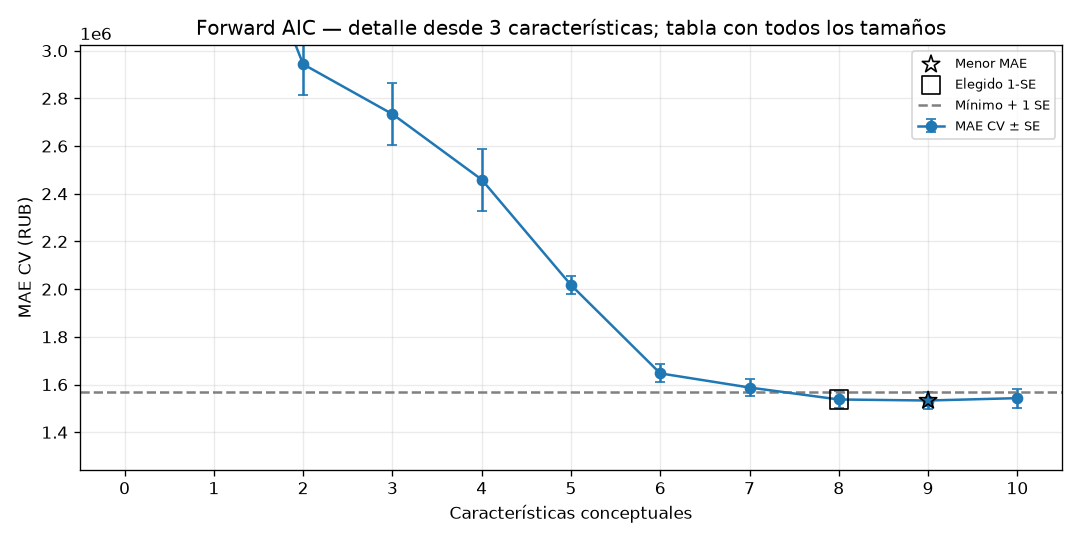

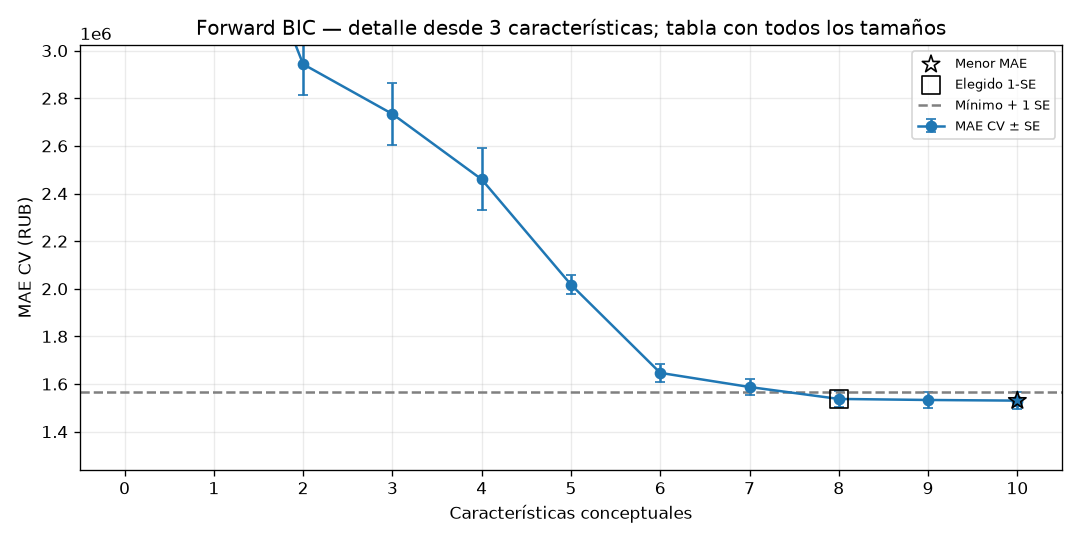

In [17]:
figuras_forward = {}
for criterio,seleccion in selecciones_forward.items():
    recorrido = seleccion['historial'].copy()
    display(Markdown(f"### Evolución de Forward {criterio.upper()}\n\n"+tabla_markdown(
        recorrido[['paso','incorporada','n_caracteristicas','columnas_ols',criterio,'mejora']],decimales=3)))
    curva,regla = curvas_forward[criterio],reglas_1se_forward[criterio]
    display(Markdown('**MAE CV por tamaño — comparabilidad y regla 1-SE**\n\n'+tabla_markdown(curva,decimales=3)))
    fig,ax = plt.subplots(figsize=(9,4.5))
    completa = curva.loc[curva['comparable']]
    ax.errorbar(completa['tamano'],completa['mae_media'],yerr=completa['mae_se'],fmt='o-',capsize=3,label='MAE CV ± SE')
    if regla['aplicable']:
        for tamano,etiqueta,marcador in [(regla['tamano_minimo_mae'],'Menor MAE','*'),(regla['tamano_elegido'],'Elegido 1-SE','s')]:
            fila = completa.loc[completa['tamano'].eq(tamano)].iloc[0]
            ax.scatter(tamano,fila['mae_media'],s=120,marker=marcador,label=etiqueta,zorder=4,facecolors='none',edgecolors='black')
        ax.axhline(regla['limite_1se'],ls='--',color='gray',label='Mínimo + 1 SE')
        # El intercepto puede dominar la escala: mostrar el detalle sin ocultar su evaluación en la tabla.
        positivas = completa.loc[completa['tamano'].ge(CONFIG_FORWARD['min_deseado'])]
        if not positivas.empty and regla['tamano_elegido']>=CONFIG_FORWARD['min_deseado']:
            margen = max(float(positivas['mae_sd'].max()),1.0)
            ax.set_ylim(max(0,float(positivas['mae_media'].min())-margen),float(positivas['mae_media'].max())+margen)
            ax.set_title(f'Forward {criterio.upper()} — detalle desde 3 características; tabla con todos los tamaños')
        else:
            ax.set_title(f'Forward {criterio.upper()} — todos los tamaños comparables')
    ax.set(xlabel='Características conceptuales',ylabel='MAE CV (RUB)')
    ax.set_xticks(completa['tamano'])
    ax.grid(alpha=.25)
    ax.legend(fontsize=8)
    fig.tight_layout()
    figuras_forward[criterio] = fig
    display(fig)
    plt.close(fig)


## Resultados — Forward Stepwise


In [18]:
filas_comparacion = {}
for criterio,resultado in resultados_forward.items():
    tr,va = resultado['metricas']['train'],resultado['metricas']['validation']
    cv,regla,seleccion = resumen_cv_forward[criterio],reglas_1se_forward[criterio],selecciones_forward[criterio]
    filas_comparacion[f'Forward {criterio.upper()}'] = {
        'Características del modelo terminal':len(seleccion['seleccionadas']),
        'Características del modelo parsimonioso':regla['tamano_elegido'] if regla['aplicable'] else '1-SE no aplicable; usar terminal',
        'Columnas OLS del modelo elegido':resultado['n_columnas'],'Motivo de parada':seleccion['motivo_parada'],
        'Mejora mínima del criterio':seleccion['mejora_minima'],
        'Parámetros efectivos (intercepto incluido)':resultado['rango'],'Parámetros likelihood (incluye varianza)':resultado['rango']+1,
        'Tamaño con menor MAE CV':regla.get('tamano_minimo_mae','No aplicable'),
        'Error estándar usado en 1-SE (RUB)':regla.get('error_estandar',np.nan),
        'Límite MAE mínimo + 1 SE (RUB)':regla.get('limite_1se',np.nan),
        'MAE CV media ± SD (RUB)':f"{cv['mae_mean']:,.2f} ± {cv['mae_std']:,.2f}",
        'RMSE CV media ± SD (RUB)':f"{cv['rmse_mean']:,.2f} ± {cv['rmse_std']:,.2f}",
        'R² CV media':cv['r2_mean'],'MAPE CV media %':cv['mape_mean'],
        'MAE Validation (RUB)':va['mae_rub'],'RMSE Validation (RUB)':va['rmse_rub'],
        'R² Validation':va['r2'],'MAPE Validation (%)':va['mape_pct'],'RSS Validation RUB²':va['rss_rub2'],
        'AIC Train log(RUB)':tr['aic_log'],'BIC Train log(RUB)':tr['bic_log'],
        'R² ajustado Train log(RUB)':tr['r2_ajustado_log'],'RSS Train log(RUB)²':tr['rss_log'],
        'R² Train RUB':tr['r2'],'R² ajustado Train RUB (descriptivo)':tr['r2_ajustado'],
        'RSS Train RUB²':tr['rss_rub2'],'MAE Train RUB':tr['mae_rub'],'RMSE Train RUB':tr['rmse_rub'],'MAPE Train %':tr['mape_pct']}
comparacion_forward = pd.DataFrame(filas_comparacion).rename_axis('Métrica').reset_index()
display(Markdown(tabla_markdown(comparacion_forward,decimales=3)))
frecuencia_forward = pd.DataFrame({'Característica':predictoras_trabajo,
    **{f'{c.upper()} modelo elegido / 5 folds':[frecuencias_forward[c][f] for f in predictoras_trabajo] for c in selecciones_forward}})
display(Markdown(tabla_markdown(frecuencia_forward)))
for criterio,tabla in cv_forward.items():
    display(Markdown(f"**CV temporal del tamaño elegido — {criterio.upper()}**\n\n"+tabla_markdown(tabla,decimales=3)))
metricas_modelos_forward = []
for criterio in selecciones_forward:
    for tipo,resultado in [('terminal',resultados_terminales_forward[criterio]),('elegido_1se',resultados_forward[criterio])]:
        metricas_modelos_forward.append({'criterio':criterio,'modelo':tipo,'caracteristicas':resultado['caracteristicas'],
            'columnas_ols':resultado['n_columnas'],'rango':resultado['rango'],'duan':resultado['duan'],
            'metricas':resultado['metricas']})
def nombres_forward(valores):
    return ', '.join(f'`{v}`' for v in valores) if valores else 'ninguna'
parrafos = []
for criterio,resultado in resultados_forward.items():
    regla,seleccion = reglas_1se_forward[criterio],selecciones_forward[criterio]
    texto = (f"**{criterio.upper()}**: terminal de {len(seleccion['seleccionadas'])} características "
        f"por {seleccion['motivo_parada']} (umbral {seleccion['mejora_minima']:g}). ")
    if regla['aplicable']:
        texto += (f"La regla 1-SE propone **{regla['tamano_elegido']} características** y {resultado['n_columnas']} columnas, "
            f"frente al mínimo MAE CV en tamaño {regla['tamano_minimo_mae']}; SE {regla['error_estandar']:,.2f} RUB. ")
    else:
        texto += regla['motivo']+' Se conserva el terminal. '
    if len(resultado['caracteristicas'])<CONFIG_FORWARD['min_deseado']:
        texto += 'Queda por debajo del mínimo deseado de tres; no se agregan características artificialmente. '
    texto += f"Características propuestas: {nombres_forward(resultado['caracteristicas'])}. "
    texto += f"MAE Validation: {resultado['metricas']['validation']['mae_rub']:,.2f} RUB. "
    texto += 'Consistentes en los cinco folds: '+nombres_forward([f for f,n in frecuencias_forward[criterio].items() if n==N_FOLDS])+'. '
    if regla['tamanos_incompletos_excluidos']:
        texto += f"Tamaños excluidos por falta de comparabilidad: {regla['tamanos_incompletos_excluidos']}. "
    parrafos.append(texto)
conclusion_forward = '\n\n'.join(parrafos)+(
    '\n\nLos umbrales y 1-SE son criterios prácticos de simplicidad; los folds temporales se solapan y el SE no es una garantía estadística. '
    'El mínimo deseado de tres no se fuerza. Tamaños y características se deciden solo con Train y su CV; '
    'Validation evalúa propuestas ya fijadas, con Duan aprendido en el entrenamiento correspondiente. '
    'AIC/BIC y diagnósticos log corresponden a Train; las métricas predictivas, a RUB. '
    'No se declara un ganador definitivo. Test sigue reservado y los Runs anteriores se conservan como historial.')
display(Markdown('### Conclusión\n\n'+conclusion_forward))


| Métrica | Forward AIC | Forward BIC |
|---|---|---|
| Características del modelo terminal | 10 | 10 |
| Características del modelo parsimonioso | 8 | 8 |
| Columnas OLS del modelo elegido | 20 | 20 |
| Motivo de parada | maximo_caracteristicas | maximo_caracteristicas |
| Mejora mínima del criterio | 2.000 | 6.000 |
| Parámetros efectivos (intercepto incluido) | 21 | 21 |
| Parámetros likelihood (incluye varianza) | 22 | 22 |
| Tamaño con menor MAE CV | 9 | 10 |
| Error estándar usado en 1-SE (RUB) | 35,204.855 | 34,520.052 |
| Límite MAE mínimo + 1 SE (RUB) | 1,568,226.798 | 1,564,814.846 |
| MAE CV media ± SD (RUB) | 1,537,389.66 ± 78,457.50 | 1,537,389.66 ± 78,457.50 |
| RMSE CV media ± SD (RUB) | 2,344,193.64 ± 123,682.67 | 2,344,193.64 ± 123,682.67 |
| R² CV media | 0.927 | 0.927 |
| MAPE CV media % | 11.693 | 11.693 |
| MAE Validation (RUB) | 1,979,743.611 | 1,979,743.611 |
| RMSE Validation (RUB) | 2,898,546.752 | 2,898,546.752 |
| R² Validation | 0.910 | 0.910 |
| MAPE Validation (%) | 14.560 | 14.560 |
| RSS Validation RUB² | 44,175,472,261,589,104.000 | 44,175,472,261,589,104.000 |
| AIC Train log(RUB) | -43,842.784 | -43,842.784 |
| BIC Train log(RUB) | -43,656.688 | -43,656.688 |
| R² ajustado Train log(RUB) | 0.956 | 0.956 |
| RSS Train log(RUB)² | 579.300 | 579.300 |
| R² Train RUB | 0.938 | 0.938 |
| R² ajustado Train RUB (descriptivo) | 0.938 | 0.938 |
| RSS Train RUB² | 143,939,354,593,896,832.000 | 143,939,354,593,896,832.000 |
| MAE Train RUB | 1,321,851.169 | 1,321,851.169 |
| RMSE Train RUB | 2,032,215.186 | 2,032,215.186 |
| MAPE Train % | 10.430 | 10.430 |

| Característica | AIC modelo elegido / 5 folds | BIC modelo elegido / 5 folds |
|---|---|---|
| lat | 0 | 0 |
| lon | 0 | 0 |
| total_area | 5 | 5 |
| living_area | 0 | 0 |
| kitchen_area | 0 | 0 |
| rooms | 0 | 0 |
| floor | 0 | 0 |
| total_floors | 0 | 0 |
| building_year | 0 | 0 |
| ceiling_height | 0 | 0 |
| metro_distance_min | 5 | 5 |
| to_center_km | 5 | 5 |
| metro_lat | 0 | 0 |
| metro_lon | 0 | 0 |
| metro_year_opened | 0 | 0 |
| metro_to_center_km | 0 | 0 |
| has_balcony | 0 | 0 |
| metro_distance_type | 5 | 5 |
| seller_type | 0 | 0 |
| building_year_inconsistent | 0 | 0 |
| months_since_start | 5 | 5 |
| n_listings_newbuild_lag1 | 0 | 0 |
| n_listings_rental_lag1 | 0 | 0 |
| lag1_unavailable | 0 | 0 |
| district_group | 5 | 5 |
| building_type | 5 | 5 |
| renovation | 5 | 5 |
| metro_line | 0 | 0 |
| month_of_year | 0 | 0 |

**CV temporal del tamaño elegido — AIC**

| fold | tamano | n_train | n_validation | n_columnas | rango | duan | validation_r2 | validation_rss_rub2 | validation_mae_rub | validation_rmse_rub | validation_mape_pct | n_caracteristicas |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 8 | 14964 | 3933 | 20 | 21 | 1.008 | 0.925 | 18,748,059,276,139,224.000 | 1,447,195.869 | 2,183,313.931 | 11.874 | 8 |
| 2 | 8 | 18897 | 3999 | 20 | 21 | 1.008 | 0.915 | 23,011,924,053,824,540.000 | 1,573,818.259 | 2,398,837.139 | 12.715 | 8 |
| 3 | 8 | 22896 | 3981 | 20 | 21 | 1.008 | 0.928 | 22,086,813,761,911,036.000 | 1,497,962.584 | 2,355,431.321 | 11.310 | 8 |
| 4 | 8 | 26877 | 4005 | 20 | 21 | 1.008 | 0.939 | 20,710,951,486,888,796.000 | 1,515,928.968 | 2,274,043.487 | 11.023 | 8 |
| 5 | 8 | 30882 | 3971 | 20 | 21 | 1.008 | 0.926 | 25,004,588,474,580,968.000 | 1,652,042.602 | 2,509,342.326 | 11.544 | 8 |

**CV temporal del tamaño elegido — BIC**

| fold | tamano | n_train | n_validation | n_columnas | rango | duan | validation_r2 | validation_rss_rub2 | validation_mae_rub | validation_rmse_rub | validation_mape_pct | n_caracteristicas |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 8 | 14964 | 3933 | 20 | 21 | 1.008 | 0.925 | 18,748,059,276,139,224.000 | 1,447,195.869 | 2,183,313.931 | 11.874 | 8 |
| 2 | 8 | 18897 | 3999 | 20 | 21 | 1.008 | 0.915 | 23,011,924,053,824,540.000 | 1,573,818.259 | 2,398,837.139 | 12.715 | 8 |
| 3 | 8 | 22896 | 3981 | 20 | 21 | 1.008 | 0.928 | 22,086,813,761,911,036.000 | 1,497,962.584 | 2,355,431.321 | 11.310 | 8 |
| 4 | 8 | 26877 | 4005 | 20 | 21 | 1.008 | 0.939 | 20,710,951,486,888,796.000 | 1,515,928.968 | 2,274,043.487 | 11.023 | 8 |
| 5 | 8 | 30882 | 3971 | 20 | 21 | 1.008 | 0.926 | 25,004,588,474,580,968.000 | 1,652,042.602 | 2,509,342.326 | 11.544 | 8 |

### Conclusión

**AIC**: terminal de 10 características por maximo_caracteristicas (umbral 2). La regla 1-SE propone **8 características** y 20 columnas, frente al mínimo MAE CV en tamaño 9; SE 35,204.85 RUB. Características propuestas: `district_group`, `total_area`, `months_since_start`, `renovation`, `metro_distance_min`, `building_type`, `metro_distance_type`, `to_center_km`. MAE Validation: 1,979,743.61 RUB. Consistentes en los cinco folds: `total_area`, `metro_distance_min`, `to_center_km`, `metro_distance_type`, `months_since_start`, `district_group`, `building_type`, `renovation`. 

**BIC**: terminal de 10 características por maximo_caracteristicas (umbral 6). La regla 1-SE propone **8 características** y 20 columnas, frente al mínimo MAE CV en tamaño 10; SE 34,520.05 RUB. Características propuestas: `district_group`, `total_area`, `months_since_start`, `renovation`, `metro_distance_min`, `building_type`, `metro_distance_type`, `to_center_km`. MAE Validation: 1,979,743.61 RUB. Consistentes en los cinco folds: `total_area`, `metro_distance_min`, `to_center_km`, `metro_distance_type`, `months_since_start`, `district_group`, `building_type`, `renovation`. 

Los umbrales y 1-SE son criterios prácticos de simplicidad; los folds temporales se solapan y el SE no es una garantía estadística. El mínimo deseado de tres no se fuerza. Tamaños y características se deciden solo con Train y su CV; Validation evalúa propuestas ya fijadas, con Duan aprendido en el entrenamiento correspondiente. AIC/BIC y diagnósticos log corresponden a Train; las métricas predictivas, a RUB. No se declara un ganador definitivo. Test sigue reservado y los Runs anteriores se conservan como historial.

## Registro — Forward Stepwise en MLflow


In [19]:
import copy
ids_runs_forward = {}
contexto_forward = {'dataset_sha256':huella_datos,'configuracion_dataframe':configuracion_seleccionada,
    'preprocesamiento':config_preprocesamiento,'mapa_train':preparacion_ols['trazabilidad'],
    'criterios_sobre':'log(price_rub), exclusivamente Train','convencion_aic_bic':'-2 ll_log + penalizacion * (rango_diseno + 1 varianza)',
    'test_utilizado':False,'candidatas':list(predictoras_trabajo),'parada':CONFIG_FORWARD,
    'mejoras_minimas':MEJORAS_FORWARD,'seleccion_tamano':'1-SE MAE, solo tamaños completos en cinco folds de Train',
    'runs_trayectorias_historicas':RUNS_FORWARD_HISTORICOS}
with TemporaryDirectory(prefix='forward_resultados_') as temporal:
    carpeta = Path(temporal)
    for criterio,resultado in resultados_forward.items():
        destino = carpeta/criterio
        destino.mkdir()
        seleccion,regla = selecciones_forward[criterio],reglas_1se_forward[criterio]
        reutilizable = {'criterio':criterio,'candidatas':list(predictoras_trabajo),
            'terminal':seleccion['seleccionadas'],
            'parsimonioso':resultado['caracteristicas'] if regla['aplicable'] else None,
            'seleccionadas':resultado['caracteristicas'],'regla_1se':regla,
            'bloques_seleccionados':{c:columnas_por_caracteristica[c] for c in resultado['caracteristicas']},
            'columnas_modelo':resultado['ejemplo_diseno'].columns.tolist(),
            'rango_diseno':resultado['rango'],'k_likelihood':resultado['rango']+1,
            'run_kmeans8':RUN_KMEANS8,'contexto_sha256':huella_json(contexto_forward),
            'referencias_reutilizadas':{
                'bloques_candidatos':f"runs:/{RUNS_FORWARD_HISTORICOS[criterio]}/resultados/seleccion_y_bloques.json",
                'evaluaciones_candidatas':f"runs:/{RUNS_FORWARD_HISTORICOS[criterio]}/resultados/candidatas_por_paso.json",
                'mapas':f'runs:/{RUN_KMEANS8}/{ARTEFACTO_MAPAS}'},
            'inferencia':'Aplicar mapa K8, exclusiones, preprocesador completo; seleccionar columnas_modelo, añadir const; exp(predict)*Duan.'}
        (destino/'seleccion_y_bloques.json').write_text(json.dumps(reutilizable,ensure_ascii=False,indent=2),encoding='utf8')
        (destino/'folds_seleccion.json').write_text(json.dumps(detalle_folds_forward[criterio],ensure_ascii=False,indent=2,default=str),encoding='utf8')
        (destino/'historial.json').write_text(seleccion['historial'].to_json(orient='records'),encoding='utf8')
        (destino/'cv_por_tamano.json').write_text(cv_por_tamano_forward[criterio].to_json(orient='records'),encoding='utf8')
        (destino/'regla_1se.json').write_text(json.dumps(regla,ensure_ascii=False,indent=2),encoding='utf8')
        (destino/'metricas_terminal_y_elegido.json').write_text(json.dumps(
            [m for m in metricas_modelos_forward if m['criterio']==criterio],ensure_ascii=False,indent=2),encoding='utf8')
        (destino/'frecuencias.json').write_text(json.dumps(frecuencias_forward[criterio],indent=2),encoding='utf8')
        (destino/'comparacion_forward.md').write_text(tabla_markdown(comparacion_forward,decimales=6)+'\n\n'+conclusion_forward,encoding='utf8')
        figuras_forward[criterio].savefig(destino/f'mae_cv_1se_{criterio}.png',dpi=150)
        # El preprocesador acompaña al modelo principal para inferencia autónoma; mapas y criterios previos se referencian.
        if resultado['caracteristicas']!=seleccion['seleccionadas']:
            terminal = copy.deepcopy(resultados_terminales_forward[criterio]['modelo'])
            terminal.save(str(destino/'modelo_terminal.pkl'),remove_data=True)
        resultado_registro = {**resultado,'metricas':{s:dict(m) for s,m in resultado['metricas'].items()}}
        resultado_registro['metricas']['cv'] = resumen_cv_forward[criterio]
        resultado_registro['metricas']['terminal_train'] = resultados_terminales_forward[criterio]['metricas']['train']
        resultado_registro['metricas']['terminal_validation'] = resultados_terminales_forward[criterio]['metricas']['validation']
        ids_runs_forward[criterio] = registrar_experimento(
            f'Forward_Stepwise_{criterio.upper()}_Max10_Delta{MEJORAS_FORWARD[criterio]:g}_1SE',resultado_registro,
            cliente=cliente_mlflow,contexto=contexto_forward,
            parametros={'criterio_seleccion':criterio.upper(),'run_kmeans8':RUN_KMEANS8,
                'run_forward_anterior':RUNS_FORWARD_HISTORICOS[criterio],**CONFIG_FORWARD,
                'mejora_minima':MEJORAS_FORWARD[criterio],'motivo_parada':seleccion['motivo_parada'],
                'n_terminal':len(seleccion['seleccionadas']),'n_parsimonioso':regla['tamano_elegido'] if regla['aplicable'] else 'no_aplica',
                'regla_1se_aplicable':regla['aplicable'],'k_likelihood':resultado['rango']+1,
                'criterio_escala':'log_RUB','cv_folds':N_FOLDS,'cv_meses_validation':MESES_VALID_FOLD,
                'cv_sd_ddof':1,'se_definicion':'SD_folds/sqrt(5)','seleccion_unidad':'caracteristica_completa',
                'inicio':'solo_intercepto','criterios_historicos_reutilizados':True},
            nota=f'Forward {criterio.upper()}, Max10, delta={MEJORAS_FORWARD[criterio]:g}, 1-SE. '+conclusion_forward,
            cv=cv_forward[criterio],artefactos=sorted(destino.iterdir()))
        print(f"Registrado {criterio.upper()}: {ids_runs_forward[criterio]}",flush=True)
        run = cliente_mlflow.get_run(ids_runs_forward[criterio])
        assert run.info.status=='FINISHED' and run.info.experiment_id==experimento_existente.experiment_id
        assert run.data.tags['test_evaluado']=='false'
        for clave,valor in resultado['metricas']['validation'].items():
            if valor is not None:
                np.testing.assert_allclose(run.data.metrics[f'validation_{clave}'],valor)
assert huella_tabla(df_trabajo)==huella_pre_forward and huella_tabla(datos_base)==huella_base_memoria
assert hashlib.sha256(archivo_datos.read_bytes()).hexdigest()==huella_datos and X_test_ols is None
display(Markdown('\n\n'.join(f"[Forward {c.upper()} Max10 + 1-SE]({TRACKING_URI}/#/experiments/{experimento_existente.experiment_id}/runs/{r})"
    for c,r in ids_runs_forward.items())))


🏃 View run Forward_Stepwise_AIC_Max10_Delta2_1SE at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/d8ed91da3bae45eb8d40c5912c8e0ac8
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1
Registrado AIC: d8ed91da3bae45eb8d40c5912c8e0ac8
🏃 View run Forward_Stepwise_BIC_Max10_Delta6_1SE at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/397cd18b88c748108f70b3de8e9b20e0
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1
Registrado BIC: 397cd18b88c748108f70b3de8e9b20e0


[Forward AIC Max10 + 1-SE](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/d8ed91da3bae45eb8d40c5912c8e0ac8)

[Forward BIC Max10 + 1-SE](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/397cd18b88c748108f70b3de8e9b20e0)

## Backward Stepwise Selection — AIC y BIC


In [20]:
def backward_stepwise(X,y_log,*,bloques,criterio,max_caracteristicas=10,min_caracteristicas=3,mejora_minima=None):
    criterio = criterio.lower()
    if criterio not in {'aic','bic'}:
        raise ValueError('Criterio admitido: AIC o BIC.')
    mejora_minima = {'aic':2.0,'bic':6.0}[criterio] if mejora_minima is None else float(mejora_minima)
    if not 3<=min_caracteristicas<=max_caracteristicas<=10 or mejora_minima<0:
        raise ValueError('Respetar 3 ≤ mínimo ≤ máximo ≤ 10 y mejora no negativa.')
    if len(bloques)<min_caracteristicas:
        raise ValueError('No hay suficientes características para cumplir el mínimo.')
    assert X.index.equals(y_log.index) and X.columns.is_unique
    assert [col for cols in bloques.values() for col in cols]==X.columns.tolist()
    assert not set(bloques).intersection(set(auxiliares_trabajo)|{objetivo}|set(EXCLUIR_TRABAJO))
    diseno = np.column_stack([np.ones(len(X)),X.to_numpy(dtype=float)])
    y = y_log.to_numpy(dtype=float)
    # Mínimos cuadrados por QR: igual likelihood log, n original y rango + varianza que Forward.
    Q,R = np.linalg.qr(diseno,mode='reduced')
    qy = Q.T@y
    rss_fuera = float(np.square(y-Q@qy).sum())
    posiciones = {col:i+1 for i,col in enumerate(X.columns)}
    def ajustar(caracteristicas):
        ids = [0]+[posiciones[col] for c in caracteristicas for col in bloques[c]]
        coef,_,rango,_ = np.linalg.lstsq(R[:,ids],qy,rcond=len(X)*np.finfo(float).eps)
        rss = rss_fuera+float(np.square(qy-R[:,ids]@coef).sum())
        ll = -len(y)/2*(np.log(2*np.pi)+1+np.log(rss/len(y)))
        k = int(rango)+1
        return {'aic':float(-2*ll+2*k),'bic':float(-2*ll+np.log(len(y))*k),
            'rango':int(rango),'k_likelihood':k,'columnas_ols':len(ids)-1,'rss_log':rss}
    seleccionadas = list(bloques)
    actual = ajustar(seleccionadas)
    historial = [{'iteracion':0,'paso':len(seleccionadas),'etapa':'inicio','eliminada':'Ninguna',
        'seleccionadas':list(seleccionadas),'n_caracteristicas':len(seleccionadas),'mejora':0.0,
        'deterioro_forzado':False,**actual}]
    ultima_candidata = None
    while len(seleccionadas)>min_caracteristicas:
        etapa = 'A_reduccion_obligatoria' if len(seleccionadas)>max_caracteristicas else 'B_umbral'
        mejor = None
        # Conservar solo la mejor alternativa; no almacenar combinaciones descartadas.
        for c in seleccionadas:
            candidatas = [v for v in seleccionadas if v!=c]
            ajuste = ajustar(candidatas)
            if mejor is None or ajuste[criterio]<mejor[1][criterio]:
                mejor = (c,ajuste,candidatas)
        eliminada,ajuste,candidatas = mejor
        mejora = actual[criterio]-ajuste[criterio]
        if etapa=='B_umbral' and (mejora<=0 or mejora<mejora_minima):
            motivo = 'mejora_insuficiente'
            ultima_candidata = {'caracteristica':eliminada,'mejora':mejora,'criterio_resultante':ajuste[criterio]}
            break
        seleccionadas = candidatas
        historial.append({'iteracion':len(historial),'paso':len(seleccionadas),'etapa':etapa,
            'eliminada':eliminada,'seleccionadas':list(seleccionadas),'n_caracteristicas':len(seleccionadas),
            'mejora':mejora,'deterioro_forzado':etapa=='A_reduccion_obligatoria' and mejora<0,**ajuste})
        actual = ajuste
    else:
        motivo = 'minimo_caracteristicas'
    # Solo ajustar para predicción el inicio (auditoría) y tamaños permitidos efectivamente aceptados.
    modelos_trayectoria = {}
    for paso in historial:
        if paso['paso']>max_caracteristicas and paso['etapa']!='inicio':
            continue
        xs = seleccionar_caracteristicas_ols(X,paso['seleccionadas'],bloques=bloques)
        modelo = sm.OLS(y_log,sm.add_constant(xs,has_constant='add'),missing='raise').fit()
        rango = int(modelo.model.rank)
        np.testing.assert_allclose([paso['aic'],paso['bic']],
            [-2*modelo.llf+2*(rango+1),-2*modelo.llf+np.log(len(X))*(rango+1)],rtol=1e-8,atol=1e-5)
        assert rango==paso['rango']
        modelos_trayectoria[paso['paso']] = modelo
    assert min_caracteristicas<=len(seleccionadas)<=max_caracteristicas
    return {'criterio':criterio,'seleccionadas':seleccionadas,'historial':pd.DataFrame(historial),
        'modelos_trayectoria':modelos_trayectoria,'modelo':modelos_trayectoria[len(seleccionadas)],
        'motivo_parada':motivo,'max_caracteristicas':max_caracteristicas,'min_caracteristicas':min_caracteristicas,
        'mejora_minima':mejora_minima,'ultima_candidata_rechazada':ultima_candidata}

def elegir_tamano_backward(tabla,disponibles,*,n_folds=5,minimo=3,maximo=10):
    # Resumir únicamente tamaños 3–10; jamás reincorporar el inicio de 29 mediante 1-SE.
    curva = tabla.loc[tabla['tamano'].between(minimo,maximo)].groupby('tamano').agg(
        folds=('fold','nunique'),mae_media=('validation_mae_rub','mean'),mae_sd=('validation_mae_rub','std'),
        rmse_media=('validation_rmse_rub','mean'),rmse_sd=('validation_rmse_rub','std'),
        r2_media=('validation_r2','mean'),mape_media=('validation_mape_pct','mean')).reset_index()
    curva['mae_se'] = curva['mae_sd']/np.sqrt(curva['folds'])
    curva['comparable'] = curva['folds'].eq(n_folds)&curva['tamano'].isin(disponibles)
    comparables = curva.loc[curva['comparable']]
    regla = {'aplicable':len(comparables)>=2,'tamanos_comparables':comparables['tamano'].astype(int).tolist(),
        'tamanos_excluidos':curva.loc[~curva['comparable'],'tamano'].astype(int).tolist()}
    if not regla['aplicable']:
        regla['motivo'] = 'Menos de dos tamaños aceptados comparables en los cinco folds y Train; usar terminal.'
    else:
        mejor = comparables.sort_values(['mae_media','tamano']).iloc[0]
        limite = float(mejor['mae_media']+mejor['mae_se'])
        regla.update(tamano_minimo_mae=int(mejor['tamano']),mae_minimo=float(mejor['mae_media']),
            error_estandar=float(mejor['mae_se']),limite_1se=limite,
            tamano_elegido=int(comparables.loc[comparables['mae_media'].le(limite),'tamano'].min()))
    return curva,regla


In [21]:
CONFIG_BACKWARD = {'max_caracteristicas':10,'min_caracteristicas':3}
MEJORAS_BACKWARD = {'aic':2.0,'bic':6.0}
huella_pre_backward = huella_tabla(df_trabajo)
selecciones_backward,detalle_folds_backward,filas_cv_backward = {},{c:{} for c in MEJORAS_BACKWARD},{c:[] for c in MEJORAS_BACKWARD}
with threadpool_limits(limits=1):
    for criterio in MEJORAS_BACKWARD:
        selecciones_backward[criterio] = backward_stepwise(X_train_ols,np.log(df_trabajo_train[objetivo]),
            bloques=columnas_por_caracteristica,criterio=criterio,**CONFIG_BACKWARD,mejora_minima=MEJORAS_BACKWARD[criterio])
        s = selecciones_backward[criterio]
        print(f"Backward {criterio.upper()}: terminal {len(s['seleccionadas'])}, {s['motivo_parada']}.",flush=True)
    for fold in range(1,N_FOLDS+1):
        prep = preparar_matrices_fold(fold)
        assert prep['trazabilidad']['fold']==fold
        xt,xv = prep['matrices']['train'],prep['matrices']['validation']
        assert datos_base.loc[xt.index.union(xv.index),'dataset_split'].eq('train').all()
        assert datos_base.loc[xt.index,'date_posted_dt'].max()<datos_base.loc[xv.index,'date_posted_dt'].min()
        for criterio in MEJORAS_BACKWARD:
            s = backward_stepwise(xt,np.log(datos_base.loc[xt.index,objetivo]),bloques=prep['bloques'],
                criterio=criterio,**CONFIG_BACKWARD,mejora_minima=MEJORAS_BACKWARD[criterio])
            detalle = {'terminal':s['seleccionadas'],'motivo_parada':s['motivo_parada'],
                'trazabilidad':prep['trazabilidad'],'bloques':prep['bloques'],
                'historial_aceptado':s['historial'].to_dict('records'),'modelos_por_tamano':{}}
            for tamano in sorted(s['modelos_trayectoria']):
                # Evaluador OLS/Duan existente; paso identifica aquí el tamaño de cada subconjunto.
                r = evaluar_forward(s,prep,paso=tamano)
                detalle['modelos_por_tamano'][str(tamano)] = {'caracteristicas':r['caracteristicas'],
                    'metricas':r['metricas'],'duan':r['duan'],'columnas':r['n_columnas'],'rango':r['rango']}
                filas_cv_backward[criterio].append({'fold':fold,'tamano':tamano,'n_train':len(xt),'n_validation':len(xv),
                    'n_columnas':r['n_columnas'],'rango':r['rango'],'duan':r['duan'],
                    **{f'validation_{m}':v for m,v in r['metricas']['validation'].items() if v is not None}})
            detalle_folds_backward[criterio][str(fold)] = detalle
        print(f'Backward fold {fold}/5 completado.',flush=True)

cv_por_tamano_backward,curvas_backward,reglas_1se_backward = {},{},{}
cv_backward,resumen_cv_backward,frecuencias_backward = {},{},{}
resultados_backward,resultados_terminales_backward,auditoria_reduccion_backward = {},{},{}
for criterio,filas in filas_cv_backward.items():
    tabla = pd.DataFrame(filas)
    cv_por_tamano_backward[criterio] = tabla
    seleccion = selecciones_backward[criterio]
    curva,regla = elegir_tamano_backward(tabla,set(seleccion['modelos_trayectoria']),n_folds=N_FOLDS,**{
        'minimo':CONFIG_BACKWARD['min_caracteristicas'],'maximo':CONFIG_BACKWARD['max_caracteristicas']})
    elegido = regla['tamano_elegido'] if regla['aplicable'] else len(seleccion['seleccionadas'])
    regla['tamano_propuesto'] = elegido
    reglas_1se_backward[criterio],curvas_backward[criterio] = regla,curva
    filas_elegidas = []
    for fold,detalle in detalle_folds_backward[criterio].items():
        tamano = elegido if regla['aplicable'] else len(detalle['terminal'])
        detalle['elegido'] = detalle['modelos_por_tamano'][str(tamano)]['caracteristicas']
        detalle['parsimonioso'] = detalle['elegido'] if regla['aplicable'] else None
        fila = tabla.loc[tabla['fold'].eq(int(fold))&tabla['tamano'].eq(tamano)].copy()
        fila['n_caracteristicas_terminal'] = len(detalle['terminal'])
        fila['n_caracteristicas_elegidas'] = tamano
        filas_elegidas.append(fila)
    cv = pd.concat(filas_elegidas,ignore_index=True)
    assert len(cv)==N_FOLDS and set(cv['fold'])==set(range(1,N_FOLDS+1))
    assert cv['tamano'].between(3,10).all()
    cv_backward[criterio] = cv
    resumen_cv_backward[criterio] = {'mae_mean':float(cv['validation_mae_rub'].mean()),
        'mae_std':float(cv['validation_mae_rub'].std(ddof=1)),
        'rmse_mean':float(cv['validation_rmse_rub'].mean()),'rmse_std':float(cv['validation_rmse_rub'].std(ddof=1)),
        'r2_mean':float(cv['validation_r2'].mean()),'mape_mean':float(cv['validation_mape_pct'].mean())}
    frecuencias_backward[criterio] = {c:sum(c in d['elegido'] for d in detalle_folds_backward[criterio].values()) for c in predictoras_trabajo}
    # Auditoría interna de la reducción forzada: el inicio no es candidato a 1-SE ni modelo propuesto.
    inicio = tabla.loc[tabla['tamano'].eq(len(predictoras_trabajo))].set_index('fold')['validation_mae_rub']
    diez = tabla.loc[tabla['tamano'].eq(CONFIG_BACKWARD['max_caracteristicas'])].set_index('fold')['validation_mae_rub']
    assert set(inicio.index)==set(diez.index)==set(range(1,N_FOLDS+1))
    auditoria_reduccion_backward[criterio] = {'mae_cv_inicio':float(inicio.mean()),'mae_cv_10':float(diez.mean()),
        'delta_mae_rub':float(diez.mean()-inicio.mean()),'delta_mae_pct':float((diez.mean()/inicio.mean()-1)*100),
        'delta_por_fold_rub':{str(k):float(v) for k,v in (diez-inicio).items()},
        'uso':'Auditoría de pérdida por reducción obligatoria dentro de Backward; excluida de 1-SE.'}
    # Solo ahora se consulta Validation, con características y tamaño ya fijados.
    resultados_terminales_backward[criterio] = evaluar_forward(seleccion,preparacion_ols)
    resultados_backward[criterio] = evaluar_forward(seleccion,preparacion_ols,paso=elegido)
    print(f"Backward {criterio.upper()}: propuesta {elegido}, 1-SE aplicable={regla['aplicable']}.",flush=True)
assert huella_tabla(df_trabajo)==huella_pre_backward==huella_trabajo_antes_ohe
assert huella_tabla(datos_base)==huella_base_memoria and X_test_ols is None


Backward AIC: terminal 10, mejora_insuficiente.
Backward BIC: terminal 10, mejora_insuficiente.
Backward fold 1/5 completado.
Backward fold 2/5 completado.
Backward fold 3/5 completado.
Backward fold 4/5 completado.
Backward fold 5/5 completado.
Backward AIC: propuesta 10, 1-SE aplicable=False.
Backward BIC: propuesta 10, 1-SE aplicable=False.


## Resultados — Backward Stepwise


### Backward AIC

Reducción inicial: 29 → 10 características; 19 retiros, 15 con deterioro del criterio.

| iteracion | etapa | eliminada | n_caracteristicas | columnas_ols | aic | mejora |
|---|---|---|---|---|---|---|
| 19 | A_reduccion_obligatoria | metro_line | 10 | 22 | -44,380.427 | -168.545 |

**MAE CV por tamaño permitido**

| tamano | folds | mae_media | mae_sd | rmse_media | rmse_sd | r2_media | mape_media | mae_se | comparable |
|---|---|---|---|---|---|---|---|---|---|
| 10 | 5 | 1,542,992.120 | 90,311.762 | 2,353,247.434 | 136,188.369 | 0.926 | 11.749 | 40,388.648 | True |

<Figure size 800x400 with 1 Axes>

### Backward BIC

Reducción inicial: 29 → 10 características; 19 retiros, 10 con deterioro del criterio.

| iteracion | etapa | eliminada | n_caracteristicas | columnas_ols | bic | mejora |
|---|---|---|---|---|---|---|
| 19 | A_reduccion_obligatoria | lag1_unavailable | 10 | 22 | -44,177.414 | -121.038 |

**MAE CV por tamaño permitido**

| tamano | folds | mae_media | mae_sd | rmse_media | rmse_sd | r2_media | mape_media | mae_se | comparable |
|---|---|---|---|---|---|---|---|---|---|
| 10 | 5 | 1,530,294.794 | 77,189.183 | 2,336,657.440 | 119,836.527 | 0.927 | 11.636 | 34,520.052 | True |

...

| Métrica | Backward AIC | Backward BIC |
|---|---|---|
| Características iniciales | 29 | 29 |
| Características terminales | 10 | 10 |
| Características seleccionadas | 10 | 10 |
| Columnas OLS | 22 | 22 |
| Parámetros efectivos con intercepto | 23 | 23 |
| Parámetros likelihood con varianza | 24 | 24 |
| Motivo de parada | mejora_insuficiente | mejora_insuficiente |
| 1-SE aplicable | False | False |
| Error estándar usado en 1-SE RUB | — | — |
| MAE CV media ± SD (RUB) | 1,542,992.12 ± 90,311.76 | 1,530,294.79 ± 77,189.18 |
| RMSE CV media ± SD (RUB) | 2,353,247.43 ± 136,188.37 | 2,336,657.44 ± 119,836.53 |
| R² CV media | 0.926 | 0.927 |
| MAPE CV media % | 11.749 | 11.636 |
| MAE Validation (RUB) | 1,965,052.160 | 1,965,052.160 |
| RMSE Validation (RUB) | 2,867,925.755 | 2,867,925.755 |
| R² Validation | 0.912 | 0.912 |
| MAPE Validation (%) | 14.454 | 14.454 |
| RSS Validation RUB² | 43,247,040,198,378,048.000 | 43,247,040,198,378,048.000 |
| AIC Train log(RUB) | -44,380.427 | -44,380.427 |
| BIC Train log(RUB) | -44,177.414 | -44,177.414 |
| R² ajustado Train log(RUB) | 0.956 | 0.956 |
| RSS Train log(RUB)² | 570.367 | 570.367 |
| R² Train RUB | 0.939 | 0.939 |
| R² ajustado Train RUB (descriptivo) | 0.939 | 0.939 |
| RSS Train RUB² | 142,362,323,953,434,704.000 | 142,362,323,953,434,704.000 |
| MAE Train RUB | 1,313,455.285 | 1,313,455.285 |
| RMSE Train RUB | 2,021,051.831 | 2,021,051.831 |
| MAPE Train % | 10.347 | 10.347 |
| Δ MAE CV por reducción inicial a 10 % | 0.533 | -0.295 |

| Característica | AIC folds / 5 | BIC folds / 5 |
|---|---|---|
| lat | 0 | 0 |
| lon | 0 | 0 |
| total_area | 5 | 5 |
| living_area | 0 | 0 |
| kitchen_area | 0 | 0 |
| rooms | 4 | 4 |
| floor | 0 | 0 |
| total_floors | 0 | 0 |
| building_year | 0 | 0 |
| ceiling_height | 0 | 1 |
| metro_distance_min | 5 | 5 |
| to_center_km | 5 | 5 |
| metro_lat | 0 | 0 |
| metro_lon | 0 | 0 |
| metro_year_opened | 0 | 0 |
| metro_to_center_km | 0 | 0 |
| has_balcony | 5 | 5 |
| metro_distance_type | 5 | 5 |
| seller_type | 0 | 0 |
| building_year_inconsistent | 0 | 0 |
| months_since_start | 5 | 5 |
| n_listings_newbuild_lag1 | 0 | 0 |
| n_listings_rental_lag1 | 0 | 0 |
| lag1_unavailable | 0 | 0 |
| district_group | 5 | 5 |
| building_type | 5 | 5 |
| renovation | 5 | 5 |
| metro_line | 0 | 0 |
| month_of_year | 1 | 0 |

**CV temporal — Backward AIC**

| fold | tamano | n_train | n_validation | n_columnas | rango | duan | validation_r2 | validation_rss_rub2 | validation_mae_rub | validation_rmse_rub | validation_mape_pct | n_caracteristicas_terminal | n_caracteristicas_elegidas |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 10 | 14964 | 3933 | 22 | 23 | 1.008 | 0.925 | 18,782,151,030,692,944.000 | 1,443,327.278 | 2,185,298.114 | 11.824 | 10 | 10 |
| 2 | 10 | 18897 | 3999 | 32 | 33 | 1.008 | 0.909 | 24,741,796,734,234,900.000 | 1,637,631.094 | 2,487,367.269 | 13.290 | 10 | 10 |
| 3 | 10 | 22896 | 3981 | 22 | 23 | 1.008 | 0.928 | 22,010,699,027,442,216.000 | 1,491,724.742 | 2,351,369.220 | 11.274 | 10 | 10 |
| 4 | 10 | 26877 | 4005 | 22 | 23 | 1.008 | 0.940 | 20,350,262,468,826,916.000 | 1,502,137.176 | 2,254,154.853 | 10.908 | 10 | 10 |
| 5 | 10 | 30882 | 3971 | 22 | 23 | 1.008 | 0.927 | 24,582,004,668,719,964.000 | 1,640,140.311 | 2,488,047.715 | 11.452 | 10 | 10 |

**CV temporal — Backward BIC**

| fold | tamano | n_train | n_validation | n_columnas | rango | duan | validation_r2 | validation_rss_rub2 | validation_mae_rub | validation_rmse_rub | validation_mape_pct | n_caracteristicas_terminal | n_caracteristicas_elegidas |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 10 | 14964 | 3933 | 22 | 23 | 1.008 | 0.925 | 18,782,151,030,692,944.000 | 1,443,327.278 | 2,185,298.114 | 11.824 | 10 | 10 |
| 2 | 10 | 18897 | 3999 | 22 | 23 | 1.008 | 0.915 | 23,119,108,984,882,968.000 | 1,574,144.462 | 2,404,417.300 | 12.721 | 10 | 10 |
| 3 | 10 | 22896 | 3981 | 22 | 23 | 1.008 | 0.928 | 22,010,699,027,442,216.000 | 1,491,724.742 | 2,351,369.220 | 11.274 | 10 | 10 |
| 4 | 10 | 26877 | 4005 | 22 | 23 | 1.008 | 0.940 | 20,350,262,468,826,916.000 | 1,502,137.176 | 2,254,154.853 | 10.908 | 10 | 10 |
| 5 | 10 | 30882 | 3971 | 22 | 23 | 1.008 | 0.927 | 24,582,004,668,719,964.000 | 1,640,140.311 | 2,488,047.715 | 11.452 | 10 | 10 |

### Conclusión

**AIC** conserva **10 características** y 22 columnas (19 características menos); se detuvo por mejora_insuficiente. Menos de dos tamaños aceptados comparables en los cinco folds y Train; usar terminal. Características: `total_area`, `rooms`, `metro_distance_min`, `to_center_km`, `has_balcony`, `metro_distance_type`, `months_since_start`, `district_group`, `building_type`, `renovation`. MAE CV 1,542,992.12 ± 90,311.76 RUB; MAE Validation 1,965,052.16 RUB. La reducción obligatoria hasta diez cambió el MAE CV +0.533 % (+8,174.47 RUB) frente al inicio del mismo procedimiento. Existe deterioro predictivo observado: cumplir el límite de complejidad no demuestra que la pérdida de precisión sea aceptable. 

**BIC** conserva **10 características** y 22 columnas (19 características menos); se detuvo por mejora_insuficiente. Menos de dos tamaños aceptados comparables en los cinco folds y Train; usar terminal. Características: `total_area`, `rooms`, `metro_distance_min`, `to_center_km`, `has_balcony`, `metro_distance_type`, `months_since_start`, `district_group`, `building_type`, `renovation`. MAE CV 1,530,294.79 ± 77,189.18 RUB; MAE Validation 1,965,052.16 RUB. La reducción obligatoria hasta diez cambió el MAE CV -0.295 % (-4,522.85 RUB) frente al inicio del mismo procedimiento. La reducción es compatible con el MAE observado en CV, sin deterioro medio en esa auditoría. 

Se cumple el intervalo 3–10; la aceptabilidad del error absoluto no queda garantizada por AIC/BIC ni por 1-SE. Los umbrales son prácticos; el SE usa SD entre folds/sqrt(5), con períodos de entrenamiento solapados. AIC/BIC y diagnósticos log se calculan en Train; las métricas predictivas se expresan en RUB con Duan de cada entrenamiento. La configuración inicial solo audita la reducción forzada y nunca participa en 1-SE. Test permanece reservado.

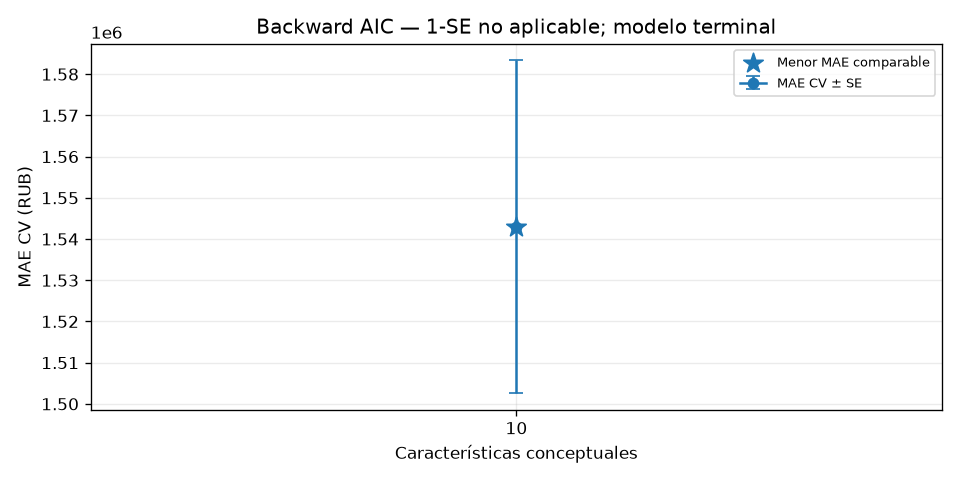

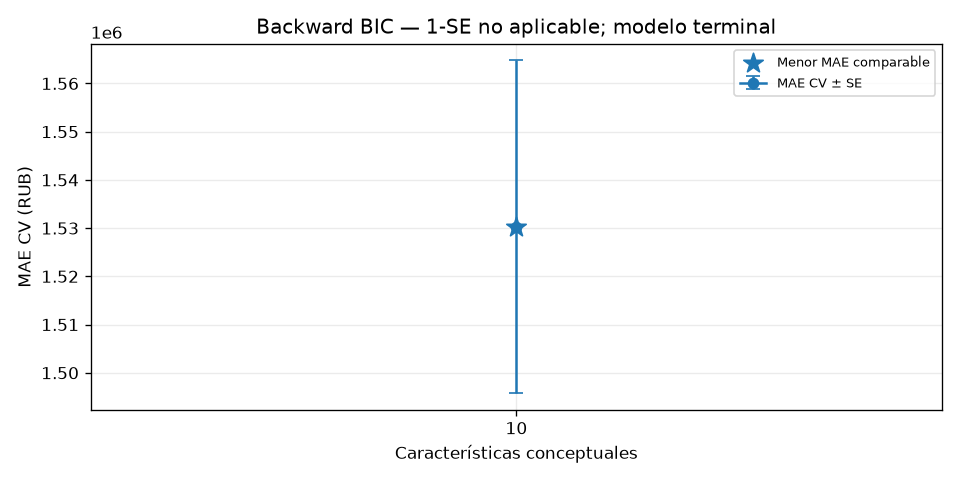

In [22]:
figuras_backward,filas_resumen_backward,conclusiones_backward = {},{},[]
for criterio,r in resultados_backward.items():
    seleccion,regla = selecciones_backward[criterio],reglas_1se_backward[criterio]
    historial = seleccion['historial']
    fase_a = historial.loc[historial['etapa'].eq('A_reduccion_obligatoria')]
    fase_b = historial.loc[historial['n_caracteristicas'].between(3,10)]
    display(Markdown(f"### Backward {criterio.upper()}\n\n"
        +f"Reducción inicial: {len(predictoras_trabajo)} → 10 características; {len(fase_a)} retiros, "
        +f"{int(fase_a['deterioro_forzado'].sum())} con deterioro del criterio.\n\n"
        +tabla_markdown(fase_b[['iteracion','etapa','eliminada','n_caracteristicas','columnas_ols',criterio,'mejora']],decimales=3)))
    curva = curvas_backward[criterio]
    display(Markdown('**MAE CV por tamaño permitido**\n\n'+tabla_markdown(curva,decimales=3)))
    fig,ax = plt.subplots(figsize=(8,4))
    completa = curva.loc[curva['comparable']]
    if not completa.empty:
        ax.errorbar(completa['tamano'],completa['mae_media'],yerr=completa['mae_se'],fmt='o-',capsize=4,label='MAE CV ± SE')
        mejor = completa.sort_values(['mae_media','tamano']).iloc[0]
        ax.scatter(mejor['tamano'],mejor['mae_media'],marker='*',s=150,label='Menor MAE comparable',zorder=4)
        if regla['aplicable']:
            punto = completa.loc[completa['tamano'].eq(regla['tamano_elegido'])].iloc[0]
            ax.scatter(punto['tamano'],punto['mae_media'],marker='s',s=120,facecolors='none',edgecolors='black',label='Elegido 1-SE',zorder=5)
            ax.axhline(regla['limite_1se'],ls='--',color='gray',label='Mínimo + 1 SE')
    else:
        cv = resumen_cv_backward[criterio]
        ax.errorbar([len(seleccion['seleccionadas'])],[cv['mae_mean']],yerr=[cv['mae_std']/np.sqrt(N_FOLDS)],fmt='o',label='Terminales por fold')
    ax.set(xlabel='Características conceptuales',ylabel='MAE CV (RUB)',
        title=f"Backward {criterio.upper()} — "+('regla 1-SE' if regla['aplicable'] else '1-SE no aplicable; modelo terminal'))
    ax.set_xticks(sorted(curva['tamano'].unique()))
    ax.grid(alpha=.25)
    ax.legend(fontsize=8)
    fig.tight_layout()
    figuras_backward[criterio] = fig
    display(fig)
    plt.close(fig)
    tr,va,cv = r['metricas']['train'],r['metricas']['validation'],resumen_cv_backward[criterio]
    auditoria = auditoria_reduccion_backward[criterio]
    filas_resumen_backward[f'Backward {criterio.upper()}'] = {
        'Características iniciales':len(predictoras_trabajo),'Características terminales':len(seleccion['seleccionadas']),
        'Características seleccionadas':len(r['caracteristicas']),'Columnas OLS':r['n_columnas'],
        'Parámetros efectivos con intercepto':r['rango'],'Parámetros likelihood con varianza':r['rango']+1,
        'Motivo de parada':seleccion['motivo_parada'],'1-SE aplicable':regla['aplicable'],
        'Error estándar usado en 1-SE RUB':regla.get('error_estandar',np.nan),
        'MAE CV media ± SD (RUB)':f"{cv['mae_mean']:,.2f} ± {cv['mae_std']:,.2f}",
        'RMSE CV media ± SD (RUB)':f"{cv['rmse_mean']:,.2f} ± {cv['rmse_std']:,.2f}",
        'R² CV media':cv['r2_mean'],'MAPE CV media %':cv['mape_mean'],
        'MAE Validation (RUB)':va['mae_rub'],'RMSE Validation (RUB)':va['rmse_rub'],
        'R² Validation':va['r2'],'MAPE Validation (%)':va['mape_pct'],'RSS Validation RUB²':va['rss_rub2'],
        'AIC Train log(RUB)':tr['aic_log'],'BIC Train log(RUB)':tr['bic_log'],
        'R² ajustado Train log(RUB)':tr['r2_ajustado_log'],'RSS Train log(RUB)²':tr['rss_log'],
        'R² Train RUB':tr['r2'],'R² ajustado Train RUB (descriptivo)':tr['r2_ajustado'],
        'RSS Train RUB²':tr['rss_rub2'],'MAE Train RUB':tr['mae_rub'],'RMSE Train RUB':tr['rmse_rub'],'MAPE Train %':tr['mape_pct'],
        'Δ MAE CV por reducción inicial a 10 %':auditoria['delta_mae_pct']}
    texto = (f"**{criterio.upper()}** conserva **{len(r['caracteristicas'])} características** y {r['n_columnas']} columnas "
        f"({len(predictoras_trabajo)-len(r['caracteristicas'])} características menos); se detuvo por {seleccion['motivo_parada']}. ")
    texto += (f"1-SE eligió tamaño {regla['tamano_elegido']}. " if regla['aplicable'] else regla['motivo']+' ')
    texto += f"Características: {', '.join('`'+c+'`' for c in r['caracteristicas'])}. "
    texto += (f"MAE CV {cv['mae_mean']:,.2f} ± {cv['mae_std']:,.2f} RUB; MAE Validation {va['mae_rub']:,.2f} RUB. "
        f"La reducción obligatoria hasta diez cambió el MAE CV {auditoria['delta_mae_pct']:+.3f} % "
        f"({auditoria['delta_mae_rub']:+,.2f} RUB) frente al inicio del mismo procedimiento. ")
    if auditoria['delta_mae_rub']>0:
        texto += 'Existe deterioro predictivo observado: cumplir el límite de complejidad no demuestra que la pérdida de precisión sea aceptable. '
    else:
        texto += 'La reducción es compatible con el MAE observado en CV, sin deterioro medio en esa auditoría. '
    conclusiones_backward.append(texto)
comparacion_backward = pd.DataFrame(filas_resumen_backward).rename_axis('Métrica').reset_index()
display(Markdown(tabla_markdown(comparacion_backward,decimales=3)))
frecuencia_backward = pd.DataFrame({'Característica':predictoras_trabajo,
    **{f'{c.upper()} folds / 5':[frecuencias_backward[c][f] for f in predictoras_trabajo] for c in MEJORAS_BACKWARD}})
display(Markdown(tabla_markdown(frecuencia_backward)))
for criterio,tabla in cv_backward.items():
    display(Markdown(f'**CV temporal — Backward {criterio.upper()}**\n\n'+tabla_markdown(tabla,decimales=3)))
conclusion_backward = '\n\n'.join(conclusiones_backward)+(
    '\n\nSe cumple el intervalo 3–10; la aceptabilidad del error absoluto no queda garantizada por AIC/BIC ni por 1-SE. '
    'Los umbrales son prácticos; el SE usa SD entre folds/sqrt(5), con períodos de entrenamiento solapados. '
    'AIC/BIC y diagnósticos log se calculan en Train; las métricas predictivas se expresan en RUB con Duan de cada entrenamiento. '
    'La configuración inicial solo audita la reducción forzada y nunca participa en 1-SE. Test permanece reservado.')
display(Markdown('### Conclusión\n\n'+conclusion_backward))


## Registro — Backward Stepwise en MLflow


In [23]:
import copy
ids_runs_backward = {}
contexto_backward = {'dataset_sha256':huella_datos,'configuracion_dataframe':configuracion_seleccionada,
    'preprocesamiento':config_preprocesamiento,'mapa_train':preparacion_ols['trazabilidad'],
    'parada':CONFIG_BACKWARD,'mejoras_minimas':MEJORAS_BACKWARD,'seleccion':'caracteristicas completas',
    'etapa_A':'reducir hasta 10 incluso con deterioro del criterio','etapa_B':'mejora mínima y piso de 3',
    'criterio_escala':'log(price_rub), Train','k_likelihood':'rango con intercepto + varianza',
    'regla_1se':'Solo tamaños 3–10 aceptados, al menos dos, comparables en los mismos cinco folds',
    'test_utilizado':False}
with TemporaryDirectory(prefix='backward_resultados_') as temporal:
    carpeta = Path(temporal)
    for criterio,r in resultados_backward.items():
        destino = carpeta/criterio
        destino.mkdir()
        s,regla = selecciones_backward[criterio],reglas_1se_backward[criterio]
        seleccion_json = {'criterio':criterio,'candidatas':list(predictoras_trabajo),
            'terminal':s['seleccionadas'],'parsimonioso':r['caracteristicas'] if regla['aplicable'] else None,
            'seleccionadas':r['caracteristicas'],'bloques_candidatos':columnas_por_caracteristica,
            'bloques_seleccionados':{c:columnas_por_caracteristica[c] for c in r['caracteristicas']},
            'columnas_modelo':r['ejemplo_diseno'].columns.tolist(),'rango':r['rango'],'k_likelihood':r['rango']+1,
            'motivo_parada':s['motivo_parada'],'ultima_candidata_rechazada':s['ultima_candidata_rechazada'],
            'run_kmeans8':RUN_KMEANS8,'mapas_uri':f'runs:/{RUN_KMEANS8}/{ARTEFACTO_MAPAS}',
            'inferencia':'Aplicar mapa K8, exclusiones, preprocesador completo, seleccionar columnas_modelo con const; exp(predict)*Duan.'}
        (destino/'seleccion_y_bloques.json').write_text(json.dumps(seleccion_json,ensure_ascii=False,indent=2),encoding='utf8')
        (destino/'historial_aceptado.json').write_text(s['historial'].to_json(orient='records'),encoding='utf8')
        (destino/'folds_seleccion.json').write_text(json.dumps(detalle_folds_backward[criterio],ensure_ascii=False,indent=2),encoding='utf8')
        (destino/'cv_por_tamano.json').write_text(cv_por_tamano_backward[criterio].to_json(orient='records'),encoding='utf8')
        (destino/'regla_1se.json').write_text(json.dumps(regla,ensure_ascii=False,indent=2),encoding='utf8')
        (destino/'auditoria_reduccion.json').write_text(json.dumps(auditoria_reduccion_backward[criterio],ensure_ascii=False,indent=2),encoding='utf8')
        (destino/'frecuencias.json').write_text(json.dumps(frecuencias_backward[criterio],indent=2),encoding='utf8')
        (destino/'metricas_terminal.json').write_text(json.dumps(resultados_terminales_backward[criterio]['metricas'],indent=2),encoding='utf8')
        (destino/'resultados.md').write_text(tabla_markdown(comparacion_backward,decimales=6)+'\n\n'+conclusion_backward,encoding='utf8')
        figuras_backward[criterio].savefig(destino/f'mae_cv_{criterio}.png',dpi=150)
        if r['caracteristicas']!=s['seleccionadas']:
            terminal = copy.deepcopy(resultados_terminales_backward[criterio]['modelo'])
            terminal.save(str(destino/'modelo_terminal.pkl'),remove_data=True)
        registro = {**r,'metricas':{p:dict(m) for p,m in r['metricas'].items()}}
        registro['metricas']['cv'] = resumen_cv_backward[criterio]
        registro['metricas']['terminal_train'] = resultados_terminales_backward[criterio]['metricas']['train']
        registro['metricas']['terminal_validation'] = resultados_terminales_backward[criterio]['metricas']['validation']
        ids_runs_backward[criterio] = registrar_experimento(f'Backward_Stepwise_{criterio.upper()}',registro,
            cliente=cliente_mlflow,contexto=contexto_backward,
            parametros={'criterio_seleccion':criterio.upper(),**CONFIG_BACKWARD,'mejora_minima':MEJORAS_BACKWARD[criterio],
                'n_iniciales':len(predictoras_trabajo),'n_terminal':len(s['seleccionadas']),
                'n_parsimonioso':len(r['caracteristicas']) if regla['aplicable'] else 'no_aplica',
                'motivo_parada':s['motivo_parada'],'regla_1se_aplicable':regla['aplicable'],
                'run_kmeans8':RUN_KMEANS8,'k_likelihood':r['rango']+1,'cv_folds':N_FOLDS,
                'cv_meses_validation':MESES_VALID_FOLD,'cv_sd_ddof':1,'se_definicion':'SD_folds/sqrt(5)',
                'seleccion_unidad':'caracteristica_completa','inicio':'todas_las_caracteristicas'},
            nota=f'Backward {criterio.upper()}: reducción inicial obligatoria y parada por umbral. '+conclusion_backward,
            cv=cv_backward[criterio],artefactos=sorted(destino.iterdir()))
        print(f"Registrado Backward {criterio.upper()}: {ids_runs_backward[criterio]}",flush=True)
        run = cliente_mlflow.get_run(ids_runs_backward[criterio])
        assert run.info.status=='FINISHED' and run.info.experiment_id==experimento_existente.experiment_id
        assert run.data.tags['test_evaluado']=='false'
        for clave,valor in r['metricas']['validation'].items():
            if valor is not None:np.testing.assert_allclose(run.data.metrics[f'validation_{clave}'],valor)
assert huella_tabla(df_trabajo)==huella_pre_backward and huella_tabla(datos_base)==huella_base_memoria
assert hashlib.sha256(archivo_datos.read_bytes()).hexdigest()==huella_datos and X_test_ols is None
display(Markdown('\n\n'.join(f"[Backward {c.upper()}]({TRACKING_URI}/#/experiments/{experimento_existente.experiment_id}/runs/{r})"
    for c,r in ids_runs_backward.items())))


🏃 View run Backward_Stepwise_AIC at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/381cb923f2784fb4a211874280d69935
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1
Registrado Backward AIC: 381cb923f2784fb4a211874280d69935
🏃 View run Backward_Stepwise_BIC at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/3615d9dc89c14fc9b7d54fcdb5f95cf2
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1
Registrado Backward BIC: 3615d9dc89c14fc9b7d54fcdb5f95cf2


[Backward AIC](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/381cb923f2784fb4a211874280d69935)

[Backward BIC](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/3615d9dc89c14fc9b7d54fcdb5f95cf2)

## Best Subset Selection — AIC y BIC


In [24]:
from itertools import combinations
from math import comb
from time import monotonic

def best_subset_selection(X,y_log,*,bloques,criterio=('aic','bic'),min_caracteristicas=3,
                          max_caracteristicas=10,max_candidatas=12,max_combinaciones=5000,
                          max_segundos=120,progreso=None):
    criterios = (criterio.lower(),) if isinstance(criterio,str) else tuple(c.lower() for c in criterio)
    if not criterios or not set(criterios)<={'aic','bic'} or len(set(criterios))!=len(criterios):
        raise ValueError('Indicar AIC, BIC o ambos, sin duplicaciones.')
    if not 3<=min_caracteristicas<=max_caracteristicas<=10 or max_candidatas<max_caracteristicas:
        raise ValueError('Respetar tamaños 3–10 y suficientes candidatas.')
    if max_segundos<=0 or max_combinaciones<1 or len(bloques)<max_caracteristicas:
        raise ValueError('Presupuesto y conjunto de características insuficientes.')
    assert X.index.equals(y_log.index) and X.columns.is_unique
    assert [col for cols in bloques.values() for col in cols]==X.columns.tolist()
    assert not set(bloques).intersection(set(auxiliares_trabajo)|{objetivo}|set(EXCLUIR_TRABAJO))
    inicio = monotonic()
    progreso = {} if progreso is None else progreso
    progreso.clear()
    y = y_log.to_numpy(dtype=float)
    diseno = np.column_stack([np.ones(len(X)),X.to_numpy(dtype=float)])
    Q,R = np.linalg.qr(diseno,mode='reduced')
    qy = Q.T@y
    rss_fuera = float(np.square(y-Q@qy).sum())
    posiciones = {col:i+1 for i,col in enumerate(X.columns)}
    def ajustar(caracteristicas):
        ids = [0]+[posiciones[col] for c in caracteristicas for col in bloques[c]]
        coef,_,rango,_ = np.linalg.lstsq(R[:,ids],qy,rcond=len(X)*np.finfo(float).eps)
        rss = rss_fuera+float(np.square(qy-R[:,ids]@coef).sum())
        ll = -len(y)/2*(np.log(2*np.pi)+1+np.log(rss/len(y)))
        k = int(rango)+1
        return {'aic':float(-2*ll+2*k),'bic':float(-2*ll+np.log(len(y))*k),
            'rango':int(rango),'k_likelihood':k,'columnas_ols':len(ids)-1,'rss_log':rss}
    originales = list(bloques)
    globales = sum(comb(len(originales),k) for k in range(min_caracteristicas,max_caracteristicas+1))
    # F parcial por bloque: aporte condicional al RSS log por grado de libertad.
    # Son ajustes auxiliares de preselección, no modelos candidatos ni algoritmos stepwise.
    ranking = []
    preseleccion = len(originales)>max_candidatas
    if preseleccion:
        completo = ajustar(originales)
        for orden,c in enumerate(originales):
            sin_bloque = ajustar([v for v in originales if v!=c])
            df_bloque = completo['rango']-sin_bloque['rango']
            delta = max(0.0,sin_bloque['rss_log']-completo['rss_log'])
            score = (delta/df_bloque)/(completo['rss_log']/(len(y)-completo['rango'])) if df_bloque>0 else 0.0
            ranking.append({'caracteristica':c,'f_parcial_bloque':float(score),'delta_rss_log':delta,
                'df_bloque':df_bloque,'orden_original':orden})
        ranking = sorted(ranking,key=lambda r:(-r['f_parcial_bloque'],r['orden_original']))
        candidatas = [r['caracteristica'] for r in ranking[:max_candidatas]]
    else:
        candidatas = originales
    esperadas = sum(comb(len(candidatas),k) for k in range(min_caracteristicas,max_caracteristicas+1))
    if esperadas>max_combinaciones:
        raise ValueError(f'{esperadas:,} combinaciones exceden el presupuesto {max_combinaciones:,}. Ajustar explícitamente la configuración.')
    for fila in ranking:
        fila['incluida'] = fila['caracteristica'] in candidatas
        fila['motivo'] = 'Entre los mayores aportes F parciales de Train' if fila['incluida'] else 'Fuera del límite de candidatas por ranking F parcial de Train'
    mejores = {c:{} for c in criterios}
    progreso.update(combinaciones_evaluadas=0,combinaciones_esperadas=esperadas,
        tamanos_completos=[],mejores=mejores,completa=False,motivo_parada='en_proceso')
    try:
        for tamano in range(min_caracteristicas,max_caracteristicas+1):
            esperadas_tamano = comb(len(candidatas),tamano)
            for numero,subconjunto in enumerate(combinations(candidatas,tamano),1):
                if monotonic()-inicio>=max_segundos:
                    progreso['motivo_parada'] = 'limite_tiempo'
                    break
                ajuste = ajustar(subconjunto)  # Un solo ajuste para calcular AIC y BIC.
                progreso['combinaciones_evaluadas'] += 1
                for c in criterios:
                    previo = mejores[c].get(tamano)
                    if previo is None or ajuste[c]<previo[c]:
                        mejores[c][tamano] = {'paso':tamano,'seleccionadas':list(subconjunto),**ajuste}
            else:
                progreso['tamanos_completos'].append(tamano)
                continue
            break
        else:
            progreso['completa'] = True
            progreso['motivo_parada'] = 'espacio_definido_agotado'
    except KeyboardInterrupt:
        progreso['motivo_parada'] = 'interrupcion_usuario'
    progreso['segundos'] = monotonic()-inicio
    # Conservar el mejor provisional de tamaños interrumpidos solo como progreso, nunca como óptimo certificado.
    resultado = {'criterios':{c:pd.DataFrame([fila for k,fila in valores.items() if k in progreso['tamanos_completos']])
        for c,valores in mejores.items()},'progreso':progreso,'ranking':pd.DataFrame(ranking),
        'candidatas':candidatas,'excluidas_preseleccion':[c for c in originales if c not in candidatas],
        'preseleccion':preseleccion,'combinaciones_globales':globales,'combinaciones_espacio':esperadas,
        'metodo':('BSS exhaustivo sobre conjunto reducido por F parcial de bloques' if preseleccion else 'BSS exhaustivo global') if progreso['completa'] else 'BSS parcial; ver progreso y tamaños incompletos',
        'huella_train':huella_tabla(X),'huella_objetivo':huella_tabla(y_log.to_frame()),
        'bloques':bloques,'limites':[min_caracteristicas,max_caracteristicas]}
    return resultado

def evaluar_mejor_bss(busqueda,criterio,tamano,preparacion,*,cache):
    fila = busqueda['criterios'][criterio].set_index('paso').loc[tamano]
    caracteristicas = fila['seleccionadas']
    clave = tuple(caracteristicas)
    if clave not in cache:
        X = preparacion['matrices']['train']
        xs = seleccionar_caracteristicas_ols(X,caracteristicas,bloques=preparacion['bloques'])
        modelo = sm.OLS(np.log(datos_base.loc[X.index,objetivo]),sm.add_constant(xs,has_constant='add'),missing='raise').fit()
        rango = int(modelo.model.rank)
        np.testing.assert_allclose([fila['aic'],fila['bic']],
            [-2*modelo.llf+2*(rango+1),-2*modelo.llf+np.log(len(X))*(rango+1)],rtol=1e-8,atol=1e-5)
        assert rango==fila['rango']
        adaptador = {'historial':pd.DataFrame([{'paso':tamano,'seleccionadas':caracteristicas}]),
            'seleccionadas':caracteristicas,'modelos_trayectoria':{tamano:modelo}}
        cache[clave] = evaluar_forward(adaptador,preparacion,paso=tamano)
    return cache[clave]


In [25]:
CONFIG_BSS = {'min_caracteristicas':3,'max_caracteristicas':10,'max_candidatas':12,
    'max_combinaciones':5000,'max_segundos':120}
REFERENCIAS_DELTA_BSS = {'aic':2.0,'bic':6.0}  # Orientativas; nunca interrumpen la exploración de tamaños.
huella_pre_bss = huella_tabla(df_trabajo)
combinaciones_globales_bss = sum(comb(len(predictoras_trabajo),k) for k in range(3,11))
combinaciones_reducidas_bss = sum(comb(CONFIG_BSS['max_candidatas'],k) for k in range(3,11))
print(f'Plan: {combinaciones_globales_bss:,} combinaciones globales; {combinaciones_reducidas_bss:,} por contexto tras preselección Train.',flush=True)
progreso_bss,detalle_folds_bss,filas_cv_bss = {},{c:{} for c in REFERENCIAS_DELTA_BSS},{c:[] for c in REFERENCIAS_DELTA_BSS}
with threadpool_limits(limits=1):
    for fold in range(1,N_FOLDS+1):
        prep = preparar_matrices_fold(fold)
        xt,xv = prep['matrices']['train'],prep['matrices']['validation']
        assert prep['trazabilidad']['fold']==fold
        assert datos_base.loc[xt.index.union(xv.index),'dataset_split'].eq('train').all()
        assert datos_base.loc[xt.index,'date_posted_dt'].max()<datos_base.loc[xv.index,'date_posted_dt'].min()
        progreso_bss[str(fold)] = {}
        busqueda = best_subset_selection(xt,np.log(datos_base.loc[xt.index,objetivo]),bloques=prep['bloques'],
            criterio=('aic','bic'),**CONFIG_BSS,progreso=progreso_bss[str(fold)])
        for criterio in REFERENCIAS_DELTA_BSS:
            detalle_folds_bss[criterio][str(fold)] = {'trazabilidad':prep['trazabilidad'],
                'candidatas':busqueda['candidatas'],'excluidas_preseleccion':busqueda['excluidas_preseleccion'],
                'ranking':busqueda['ranking'].to_dict('records'),'progreso':busqueda['progreso'],
                'mejores_por_tamano':busqueda['criterios'][criterio].to_dict('records'),'bloques':prep['bloques'],
                'metricas_por_tamano':{}}
        # Cache por tamaño: compartir ajustes idénticos AIC/BIC sin retener todos los modelos.
        for tamano in busqueda['progreso']['tamanos_completos']:
            cache = {}
            for criterio in REFERENCIAS_DELTA_BSS:
                r = evaluar_mejor_bss(busqueda,criterio,tamano,prep,cache=cache)
                detalle_folds_bss[criterio][str(fold)]['metricas_por_tamano'][str(tamano)] = {
                    'caracteristicas':r['caracteristicas'],'metricas':r['metricas'],'rango':r['rango'],'duan':r['duan']}
                filas_cv_bss[criterio].append({'fold':fold,'tamano':tamano,'n_train':len(xt),'n_validation':len(xv),
                    'n_columnas':r['n_columnas'],'rango':r['rango'],
                    **{f'validation_{m}':v for m,v in r['metricas']['validation'].items() if v is not None}})
        print(f"BSS fold {fold}/5: {busqueda['progreso']['combinaciones_evaluadas']:,} combinaciones; completa={busqueda['progreso']['completa']}.",flush=True)
    # La búsqueda de Train completo se realiza después de reconstruir independientemente la CV.
    progreso_bss['train_completo'] = {}
    busqueda_bss = best_subset_selection(X_train_ols,np.log(df_trabajo_train[objetivo]),bloques=columnas_por_caracteristica,
        criterio=('aic','bic'),**CONFIG_BSS,progreso=progreso_bss['train_completo'])

cv_por_tamano_bss,curvas_bss,reglas_1se_bss,cv_bss,resumen_cv_bss,frecuencias_bss = {},{},{},{},{},{}
resultados_bss,modelos_referencia_bss = {},{}
cache_final_bss = {}
for criterio in REFERENCIAS_DELTA_BSS:
    tabla = pd.DataFrame(filas_cv_bss[criterio])
    if tabla.empty or busqueda_bss['criterios'][criterio].empty:
        raise RuntimeError('BSS incompleto sin tamaños utilizables. Se conserva progreso_bss; no registrar una búsqueda exhaustiva.')
    cv_por_tamano_bss[criterio] = tabla
    disponibles = set(busqueda_bss['criterios'][criterio]['paso'])
    curva,regla = elegir_tamano_backward(tabla,disponibles,n_folds=N_FOLDS,minimo=3,maximo=10)
    if not regla['aplicable']:
        raise RuntimeError('No hay varios tamaños completos comparables para 1-SE. Revisar progreso_bss antes de registrar.')
    reglas_1se_bss[criterio],curvas_bss[criterio] = regla,curva
    elegido = regla['tamano_elegido']
    cv = tabla.loc[tabla['tamano'].eq(elegido)].copy()
    assert len(cv)==N_FOLDS and set(cv['fold'])==set(range(1,N_FOLDS+1))
    cv_bss[criterio] = cv
    resumen_cv_bss[criterio] = {'mae_mean':float(cv['validation_mae_rub'].mean()),
        'mae_std':float(cv['validation_mae_rub'].std(ddof=1)),
        'rmse_mean':float(cv['validation_rmse_rub'].mean()),'rmse_std':float(cv['validation_rmse_rub'].std(ddof=1)),
        'r2_mean':float(cv['validation_r2'].mean()),'mape_mean':float(cv['validation_mape_pct'].mean())}
    frecuencias_bss[criterio] = {str(tamano):{c:sum(c in d['metricas_por_tamano'].get(str(tamano),{}).get('caracteristicas',[])
        for d in detalle_folds_bss[criterio].values()) for c in predictoras_trabajo} for tamano in range(3,11)}
    mejores = busqueda_bss['criterios'][criterio]
    tamano_min_criterio = int(mejores.sort_values([criterio,'paso']).iloc[0]['paso'])
    modelos_referencia_bss[criterio] = {'minimo_criterio':tamano_min_criterio,'minimo_mae_cv':regla['tamano_minimo_mae'],
        'parsimonioso':elegido}
    # Validation se consulta únicamente para modelos/tamaños ya fijados mediante Train y CV.
    resultados_bss[criterio] = {tipo:evaluar_mejor_bss(busqueda_bss,criterio,tamano,preparacion_ols,cache=cache_final_bss)
        for tipo,tamano in modelos_referencia_bss[criterio].items()}
    print(f"BSS {criterio.upper()}: mínimo criterio {tamano_min_criterio}, mínimo MAE CV {regla['tamano_minimo_mae']}, propuesta 1-SE {elegido}.",flush=True)
assert huella_tabla(df_trabajo)==huella_pre_bss==huella_trabajo_antes_ohe
assert huella_tabla(datos_base)==huella_base_memoria and X_test_ols is None


Plan: 36,519,120 combinaciones globales; 4,004 por contexto tras preselección Train.
BSS fold 1/5: 4,004 combinaciones; completa=True.
BSS fold 2/5: 4,004 combinaciones; completa=True.
BSS fold 3/5: 4,004 combinaciones; completa=True.
BSS fold 4/5: 4,004 combinaciones; completa=True.
BSS fold 5/5: 4,004 combinaciones; completa=True.
BSS AIC: mínimo criterio 10, mínimo MAE CV 10, propuesta 1-SE 8.
BSS BIC: mínimo criterio 10, mínimo MAE CV 10, propuesta 1-SE 8.


## Resultados — Best Subset Selection


### Mejores subconjuntos por tamaño

| Características | Mejor AIC Train log(RUB) | MAE CV AIC RUB | Mejor BIC Train log(RUB) | MAE CV BIC RUB |
|---|---|---|---|---|
| 3 | -499.281 | 2,734,063.979 | -406.233 | 2,734,063.979 |
| 4 | -11,481.017 | 2,459,391.709 | -11,362.592 | 2,459,391.709 |
| 5 | -23,570.794 | 2,017,447.817 | -23,443.911 | 2,017,447.817 |
| 6 | -39,090.954 | 1,646,843.913 | -38,921.776 | 1,646,843.913 |
| 7 | -41,173.803 | 1,615,976.322 | -40,996.167 | 1,615,976.322 |
| 8 | -43,842.784 | 1,537,389.656 | -43,656.688 | 1,537,389.656 |
| 9 | -44,184.737 | 1,533,021.943 | -43,990.183 | 1,533,021.943 |
| 10 | -44,380.427 | 1,530,294.794 | -44,177.414 | 1,530,294.794 |

**Preselección independiente — Train completo**

| caracteristica | f_parcial_bloque | delta_rss_log | df_bloque | incluida | motivo |
|---|---|---|---|---|---|
| months_since_start | 31,079.440 | 495.477 | 1 | True | Entre los mayores aportes F parciales de Train |
| renovation | 11,325.887 | 541.681 | 3 | True | Entre los mayores aportes F parciales de Train |
| district_group | 10,636.816 | 1,187.026 | 7 | True | Entre los mayores aportes F parciales de Train |
| total_area | 9,075.431 | 144.683 | 1 | True | Entre los mayores aportes F parciales de Train |
| building_type | 3,603.859 | 287.269 | 5 | True | Entre los mayores aportes F parciales de Train |
| metro_distance_type | 3,383.897 | 53.947 | 1 | True | Entre los mayores aportes F parciales de Train |
| metro_distance_min | 2,299.525 | 36.660 | 1 | True | Entre los mayores aportes F parciales de Train |
| to_center_km | 2,186.441 | 34.857 | 1 | True | Entre los mayores aportes F parciales de Train |
| has_balcony | 361.972 | 5.771 | 1 | True | Entre los mayores aportes F parciales de Train |
| rooms | 204.966 | 3.268 | 1 | True | Entre los mayores aportes F parciales de Train |
| lat | 189.183 | 3.016 | 1 | True | Entre los mayores aportes F parciales de Train |
| lag1_unavailable | 163.378 | 2.605 | 1 | True | Entre los mayores aportes F parciales de Train |
| ceiling_height | 136.584 | 2.177 | 1 | False | Fuera del límite de candidatas por ranking F parcial de Train |
| lon | 93.356 | 1.488 | 1 | False | Fuera del límite de candidatas por ranking F parcial de Train |
| metro_lat | 93.139 | 1.485 | 1 | False | Fuera del límite de candidatas por ranking F parcial de Train |
| metro_lon | 56.182 | 0.896 | 1 | False | Fuera del límite de candidatas por ranking F parcial de Train |
| floor | 23.906 | 0.381 | 1 | False | Fuera del límite de candidatas por ranking F parcial de Train |
| metro_to_center_km | 17.982 | 0.287 | 1 | False | Fuera del límite de candidatas por ranking F parcial de Train |
| metro_line | 14.449 | 2.534 | 11 | False | Fuera del límite de candidatas por ranking F parcial de Train |
| month_of_year | 13.232 | 2.321 | 11 | False | Fuera del límite de candidatas por ranking F parcial de Train |
| total_floors | 9.133 | 0.146 | 1 | False | Fuera del límite de candidatas por ranking F parcial de Train |
| n_listings_rental_lag1 | 6.580 | 0.105 | 1 | False | Fuera del límite de candidatas por ranking F parcial de Train |
| metro_year_opened | 5.251 | 0.084 | 1 | False | Fuera del límite de candidatas por ranking F parcial de Train |
| kitchen_area | 5.011 | 0.080 | 1 | False | Fuera del límite de candidatas por ranking F parcial de Train |
| n_listings_newbuild_lag1 | 2.812 | 0.045 | 1 | False | Fuera del límite de candidatas por ranking F parcial de Train |
| seller_type | 1.769 | 0.028 | 1 | False | Fuera del límite de candidatas por ranking F parcial de Train |
| building_year | 0.161 | 0.003 | 1 | False | Fuera del límite de candidatas por ranking F parcial de Train |
| building_year_inconsistent | 0.111 | 0.002 | 1 | False | Fuera del límite de candidatas por ranking F parcial de Train |
| living_area | 0.069 | 0.001 | 1 | False | Fuera del límite de candidatas por ranking F parcial de Train |

**Mejores subconjuntos — AIC**

| paso | seleccionadas | columnas_ols | rango | aic | mejora_vs_tamano_anterior | referencia_delta |
|---|---|---|---|---|---|---|
| 3 | months_since_start, district_group, total_area | 9 | 10 | -499.281 | — | 2.000 |
| 4 | months_since_start, renovation, district_group, total_area | 12 | 13 | -11,481.017 | 10,981.736 | 2.000 |
| 5 | months_since_start, renovation, district_group, total_area, metro_distance_min | 13 | 14 | -23,570.794 | 12,089.778 | 2.000 |
| 6 | months_since_start, renovation, district_group, total_area, building_type, metro_distance_min | 18 | 19 | -39,090.954 | 15,520.159 | 2.000 |
| 7 | months_since_start, renovation, district_group, total_area, building_type, metro_distance_type, metro_distance_min | 19 | 20 | -41,173.803 | 2,082.850 | 2.000 |
| 8 | months_since_start, renovation, district_group, total_area, building_type, metro_distance_type, metro_distance_min, to_center_km | 20 | 21 | -43,842.784 | 2,668.981 | 2.000 |
| 9 | months_since_start, renovation, district_group, total_area, building_type, metro_distance_type, metro_distance_min, to_center_km, has_balcony | 21 | 22 | -44,184.737 | 341.953 | 2.000 |
| 10 | months_since_start, renovation, district_group, total_area, building_type, metro_distance_type, metro_distance_min, to_center_km, has_balcony, rooms | 22 | 23 | -44,380.427 | 195.690 | 2.000 |

**CV temporal por tamaño — AIC**

| tamano | folds | mae_media | mae_sd | rmse_media | rmse_sd | r2_media | mape_media | mae_se | comparable |
|---|---|---|---|---|---|---|---|---|---|
| 3 | 5 | 2,734,063.979 | 288,837.432 | 4,137,690.794 | 421,626.042 | 0.774 | 18.348 | 129,172.027 | True |
| 4 | 5 | 2,459,391.709 | 290,469.361 | 3,639,986.864 | 404,222.961 | 0.825 | 16.587 | 129,901.847 | True |
| 5 | 5 | 2,017,447.817 | 87,654.022 | 2,955,310.689 | 146,159.020 | 0.884 | 15.033 | 39,200.071 | True |
| 6 | 5 | 1,646,843.913 | 83,812.570 | 2,420,426.419 | 138,174.874 | 0.922 | 12.796 | 37,482.121 | True |
| 7 | 5 | 1,615,976.322 | 82,081.549 | 2,497,753.255 | 129,829.620 | 0.917 | 12.124 | 36,707.985 | True |
| 8 | 5 | 1,537,389.656 | 78,457.497 | 2,344,193.641 | 123,682.670 | 0.927 | 11.693 | 35,087.259 | True |
| 9 | 5 | 1,533,021.943 | 78,720.448 | 2,342,792.131 | 121,936.260 | 0.927 | 11.660 | 35,204.855 | True |
| 10 | 5 | 1,530,294.794 | 77,189.183 | 2,336,657.440 | 119,836.527 | 0.927 | 11.636 | 34,520.052 | True |

<Figure size 1200x400 with 2 Axes>

...

**CV temporal por tamaño — BIC**

| tamano | folds | mae_media | mae_sd | rmse_media | rmse_sd | r2_media | mape_media | mae_se | comparable |
|---|---|---|---|---|---|---|---|---|---|
| 3 | 5 | 2,734,063.979 | 288,837.432 | 4,137,690.794 | 421,626.042 | 0.774 | 18.348 | 129,172.027 | True |
| 4 | 5 | 2,459,391.709 | 290,469.361 | 3,639,986.864 | 404,222.961 | 0.825 | 16.587 | 129,901.847 | True |
| 5 | 5 | 2,017,447.817 | 87,654.022 | 2,955,310.689 | 146,159.020 | 0.884 | 15.033 | 39,200.071 | True |
| 6 | 5 | 1,646,843.913 | 83,812.570 | 2,420,426.419 | 138,174.874 | 0.922 | 12.796 | 37,482.121 | True |
| 7 | 5 | 1,615,976.322 | 82,081.549 | 2,497,753.255 | 129,829.620 | 0.917 | 12.124 | 36,707.985 | True |
| 8 | 5 | 1,537,389.656 | 78,457.497 | 2,344,193.641 | 123,682.670 | 0.927 | 11.693 | 35,087.259 | True |
| 9 | 5 | 1,533,021.943 | 78,720.448 | 2,342,792.131 | 121,936.260 | 0.927 | 11.660 | 35,204.855 | True |
| 10 | 5 | 1,530,294.794 | 77,189.183 | 2,336,657.440 | 119,836.527 | 0.927 | 11.636 | 34,520.052 | True |

<Figure size 1200x400 with 2 Axes>

### Comparación entre BSS AIC y BSS BIC

| Métrica | BSS AIC | BSS BIC |
|---|---|---|
| Características seleccionadas | 8 | 8 |
| Columnas OLS | 20 | 20 |
| Parámetros efectivos con intercepto | 21 | 21 |
| Parámetros likelihood con varianza | 22 | 22 |
| Tamaño de mínimo criterio | 10 | 10 |
| Tamaño de mínimo MAE CV | 10 | 10 |
| Error estándar 1-SE RUB | 34,520.052 | 34,520.052 |
| MAE CV media ± SD (RUB) | 1,537,389.66 ± 78,457.50 | 1,537,389.66 ± 78,457.50 |
| RMSE CV media ± SD (RUB) | 2,344,193.64 ± 123,682.67 | 2,344,193.64 ± 123,682.67 |
| R² CV media | 0.927 | 0.927 |
| MAPE CV media % | 11.693 | 11.693 |
| MAE Validation (RUB) | 1,979,743.611 | 1,979,743.611 |
| RMSE Validation (RUB) | 2,898,546.752 | 2,898,546.752 |
| R² Validation | 0.910 | 0.910 |
| MAPE Validation (%) | 14.560 | 14.560 |
| RSS Validation RUB² | 44,175,472,261,596,968.000 | 44,175,472,261,596,968.000 |
| AIC Train log(RUB) | -43,842.784 | -43,842.784 |
| BIC Train log(RUB) | -43,656.688 | -43,656.688 |
| R² ajustado Train log(RUB) | 0.956 | 0.956 |
| RSS Train log(RUB)² | 579.300 | 579.300 |
| R² Train RUB | 0.938 | 0.938 |
| R² ajustado Train RUB (descriptivo) | 0.938 | 0.938 |
| RSS Train RUB² | 143,939,354,593,898,560.000 | 143,939,354,593,898,560.000 |
| MAE Train RUB | 1,321,851.169 | 1,321,851.169 |
| RMSE Train RUB | 2,032,215.186 | 2,032,215.186 |
| MAPE Train % | 10.430 | 10.430 |
| Candidatas originales | 29 | 29 |
| Candidatas preseleccionadas | 12 | 12 |
| Combinaciones evaluadas Train | 4004 | 4004 |
| Búsqueda completa en espacio reducido | True | True |

| Característica | AIC folds / 5 | BIC folds / 5 |
|---|---|---|
| lat | 0 | 0 |
| lon | 0 | 0 |
| total_area | 5 | 5 |
| living_area | 0 | 0 |
| kitchen_area | 0 | 0 |
| rooms | 0 | 0 |
| floor | 0 | 0 |
| total_floors | 0 | 0 |
| building_year | 0 | 0 |
| ceiling_height | 0 | 0 |
| metro_distance_min | 5 | 5 |
| to_center_km | 5 | 5 |
| metro_lat | 0 | 0 |
| metro_lon | 0 | 0 |
| metro_year_opened | 0 | 0 |
| metro_to_center_km | 0 | 0 |
| has_balcony | 0 | 0 |
| metro_distance_type | 5 | 5 |
| seller_type | 0 | 0 |
| building_year_inconsistent | 0 | 0 |
| months_since_start | 5 | 5 |
| n_listings_newbuild_lag1 | 0 | 0 |
| n_listings_rental_lag1 | 0 | 0 |
| lag1_unavailable | 0 | 0 |
| district_group | 5 | 5 |
| building_type | 5 | 5 |
| renovation | 5 | 5 |
| metro_line | 0 | 0 |
| month_of_year | 0 | 0 |

### Conclusión

**AIC** propone **8 características** y 20 columnas: `months_since_start`, `renovation`, `district_group`, `total_area`, `building_type`, `metro_distance_type`, `metro_distance_min`, `to_center_km`. MAE CV 1,537,389.66 ± 78,457.50 RUB; MAE Validation 1,979,743.61 RUB. El mínimo MAE CV se dio con 10 características; 1-SE admite reducir hasta 8. Presentes en los cinco folds al tamaño elegido: `total_area`, `metro_distance_min`, `to_center_km`, `metro_distance_type`, `months_since_start`, `district_group`, `building_type`, `renovation`.

**BIC** propone **8 características** y 20 columnas: `months_since_start`, `renovation`, `district_group`, `total_area`, `building_type`, `metro_distance_type`, `metro_distance_min`, `to_center_km`. MAE CV 1,537,389.66 ± 78,457.50 RUB; MAE Validation 1,979,743.61 RUB. El mínimo MAE CV se dio con 10 características; 1-SE admite reducir hasta 8. Presentes en los cinco folds al tamaño elegido: `total_area`, `metro_distance_min`, `to_center_km`, `metro_distance_type`, `months_since_start`, `district_group`, `building_type`, `renovation`.

Comunes: `building_type`, `district_group`, `metro_distance_min`, `metro_distance_type`, `months_since_start`, `renovation`, `to_center_km`, `total_area`. Diferencia BIC − AIC: +0 características y +0.00 RUB de MAE Validation. La propuesta es competitiva según 1-SE dentro del espacio estudiado; esa regla no demuestra equivalencia ni garantiza aceptabilidad del error absoluto. La búsqueda fue exhaustiva solo entre las candidatas preseleccionadas por F parcial en cada entrenamiento, sin reutilizar selecciones de otros algoritmos y sin afirmar optimalidad global sobre las 29 características. Las referencias de 2 AIC y 6 BIC son orientativas y no detienen la búsqueda. Se completaron todos los tamaños 3–10 en los seis contextos. AIC/BIC y diagnósticos log son de Train; las métricas predictivas utilizan RUB con Duan del entrenamiento correspondiente. Test permanece reservado.

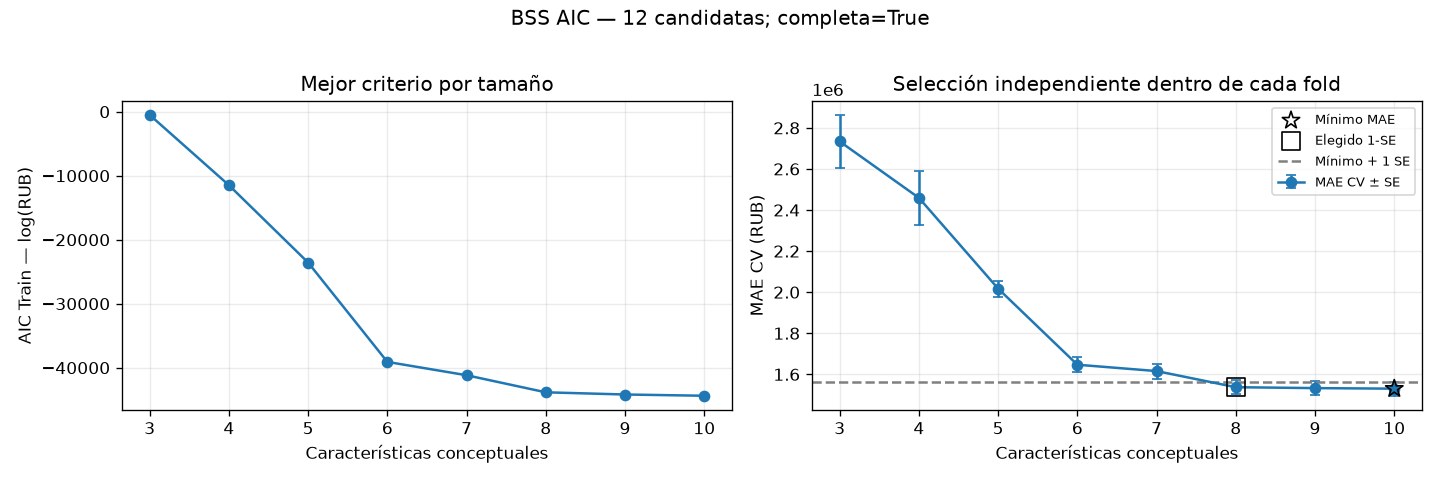

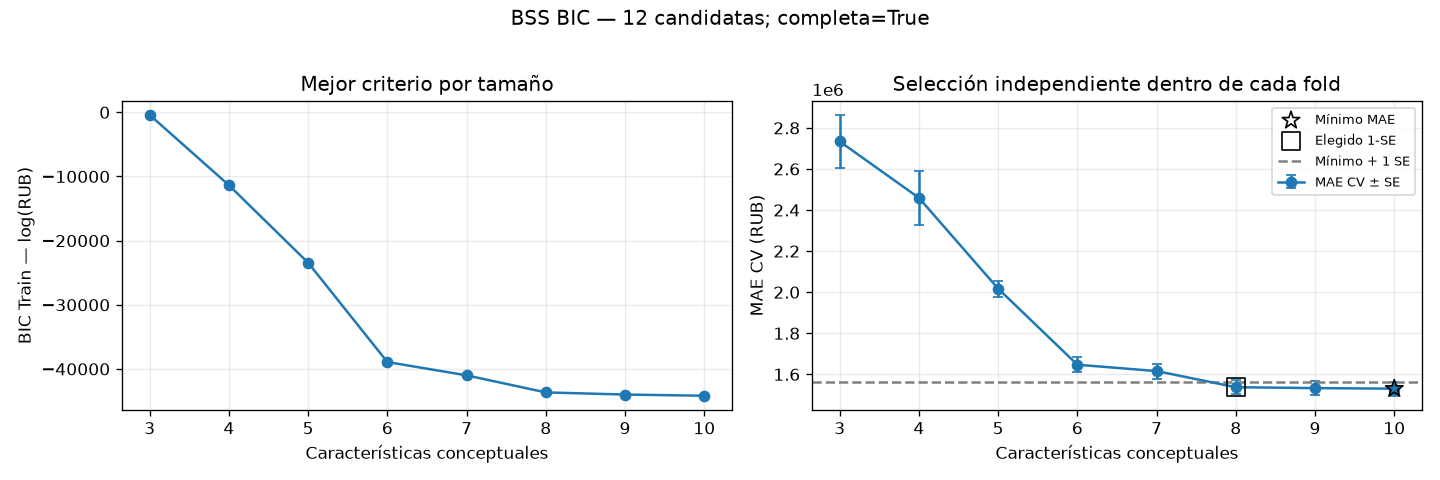

In [26]:
tabla_tamanos_bss = pd.DataFrame({'Características':range(3,11)})
for criterio in REFERENCIAS_DELTA_BSS:
    mejores = busqueda_bss['criterios'][criterio].set_index('paso')
    curva = curvas_bss[criterio].set_index('tamano')
    tabla_tamanos_bss[f'Mejor {criterio.upper()} Train log(RUB)'] = tabla_tamanos_bss['Características'].map(mejores[criterio])
    tabla_tamanos_bss[f'MAE CV {criterio.upper()} RUB'] = tabla_tamanos_bss['Características'].map(curva['mae_media'])
display(Markdown('### Mejores subconjuntos por tamaño\n\n'+tabla_markdown(tabla_tamanos_bss,decimales=3)))
display(Markdown('**Preselección independiente — Train completo**\n\n'+tabla_markdown(busqueda_bss['ranking'].drop(columns='orden_original'),decimales=3)))
figuras_bss,filas_resumen_bss,parrafos_bss = {},{},[]
for criterio in REFERENCIAS_DELTA_BSS:
    mejores = busqueda_bss['criterios'][criterio].sort_values('paso').copy()
    mejores['mejora_vs_tamano_anterior'] = -mejores[criterio].diff()
    mejores['referencia_delta'] = REFERENCIAS_DELTA_BSS[criterio]
    display(Markdown(f"**Mejores subconjuntos — {criterio.upper()}**\n\n"+tabla_markdown(mejores.assign(
        seleccionadas=mejores['seleccionadas'].map(', '.join))[
            ['paso','seleccionadas','columnas_ols','rango',criterio,'mejora_vs_tamano_anterior','referencia_delta']],decimales=3)))
    curva,regla = curvas_bss[criterio],reglas_1se_bss[criterio]
    display(Markdown(f'**CV temporal por tamaño — {criterio.upper()}**\n\n'+tabla_markdown(curva,decimales=3)))
    fig,axes = plt.subplots(1,2,figsize=(12,4))
    axes[0].plot(mejores['paso'],mejores[criterio],'o-')
    axes[0].set(xlabel='Características conceptuales',ylabel=f'{criterio.upper()} Train — log(RUB)',title='Mejor criterio por tamaño')
    completa = curva.loc[curva['comparable']]
    axes[1].errorbar(completa['tamano'],completa['mae_media'],yerr=completa['mae_se'],fmt='o-',capsize=3,label='MAE CV ± SE')
    for tamano,nombre,marcador in [(regla['tamano_minimo_mae'],'Mínimo MAE','*'),(regla['tamano_elegido'],'Elegido 1-SE','s')]:
        fila = completa.loc[completa['tamano'].eq(tamano)].iloc[0]
        axes[1].scatter(tamano,fila['mae_media'],marker=marcador,s=120,facecolors='none',edgecolors='black',label=nombre,zorder=4)
    axes[1].axhline(regla['limite_1se'],ls='--',color='gray',label='Mínimo + 1 SE')
    axes[1].set(xlabel='Características conceptuales',ylabel='MAE CV (RUB)',title='Selección independiente dentro de cada fold')
    for ax in axes:ax.set_xticks(range(3,11));ax.grid(alpha=.25)
    axes[1].legend(fontsize=8)
    fig.suptitle(f"BSS {criterio.upper()} — {len(busqueda_bss['candidatas'])} candidatas; completa={busqueda_bss['progreso']['completa']}")
    fig.tight_layout()
    figuras_bss[criterio] = fig
    display(fig)
    plt.close(fig)
    r = resultados_bss[criterio]['parsimonioso']
    tr,va,cv = r['metricas']['train'],r['metricas']['validation'],resumen_cv_bss[criterio]
    filas_resumen_bss[f'BSS {criterio.upper()}'] = {'Características seleccionadas':len(r['caracteristicas']),
        'Columnas OLS':r['n_columnas'],'Parámetros efectivos con intercepto':r['rango'],'Parámetros likelihood con varianza':r['rango']+1,
        'Tamaño de mínimo criterio':modelos_referencia_bss[criterio]['minimo_criterio'],
        'Tamaño de mínimo MAE CV':regla['tamano_minimo_mae'],'Error estándar 1-SE RUB':regla['error_estandar'],
        'MAE CV media ± SD (RUB)':f"{cv['mae_mean']:,.2f} ± {cv['mae_std']:,.2f}",
        'RMSE CV media ± SD (RUB)':f"{cv['rmse_mean']:,.2f} ± {cv['rmse_std']:,.2f}",
        'R² CV media':cv['r2_mean'],'MAPE CV media %':cv['mape_mean'],
        'MAE Validation (RUB)':va['mae_rub'],'RMSE Validation (RUB)':va['rmse_rub'],'R² Validation':va['r2'],
        'MAPE Validation (%)':va['mape_pct'],'RSS Validation RUB²':va['rss_rub2'],
        'AIC Train log(RUB)':tr['aic_log'],'BIC Train log(RUB)':tr['bic_log'],'R² ajustado Train log(RUB)':tr['r2_ajustado_log'],
        'RSS Train log(RUB)²':tr['rss_log'],'R² Train RUB':tr['r2'],'R² ajustado Train RUB (descriptivo)':tr['r2_ajustado'],
        'RSS Train RUB²':tr['rss_rub2'],'MAE Train RUB':tr['mae_rub'],'RMSE Train RUB':tr['rmse_rub'],'MAPE Train %':tr['mape_pct'],
        'Candidatas originales':len(predictoras_trabajo),'Candidatas preseleccionadas':len(busqueda_bss['candidatas']),
        'Combinaciones evaluadas Train':busqueda_bss['progreso']['combinaciones_evaluadas'],
        'Búsqueda completa en espacio reducido':busqueda_bss['progreso']['completa']}
    frecuentes = [c for c,n in frecuencias_bss[criterio][str(regla['tamano_elegido'])].items() if n==N_FOLDS]
    parrafos_bss.append(f"**{criterio.upper()}** propone **{len(r['caracteristicas'])} características** y {r['n_columnas']} columnas: "
        +', '.join('`'+c+'`' for c in r['caracteristicas'])+'. '
        +f"MAE CV {cv['mae_mean']:,.2f} ± {cv['mae_std']:,.2f} RUB; MAE Validation {va['mae_rub']:,.2f} RUB. "
        +f"El mínimo MAE CV se dio con {regla['tamano_minimo_mae']} características; 1-SE admite reducir hasta {regla['tamano_elegido']}. "
        +'Presentes en los cinco folds al tamaño elegido: '+(', '.join('`'+c+'`' for c in frecuentes) or 'ninguna')+'.')
comparacion_bss = pd.DataFrame(filas_resumen_bss).rename_axis('Métrica').reset_index()
display(Markdown('### Comparación entre BSS AIC y BSS BIC\n\n'+tabla_markdown(comparacion_bss,decimales=3)))
frecuencia_elegida_bss = pd.DataFrame({'Característica':predictoras_trabajo,
    **{f'{c.upper()} folds / 5':[frecuencias_bss[c][str(reglas_1se_bss[c]['tamano_elegido'])][f] for f in predictoras_trabajo] for c in REFERENCIAS_DELTA_BSS}})
display(Markdown(tabla_markdown(frecuencia_elegida_bss)))
a,b = (set(resultados_bss[c]['parsimonioso']['caracteristicas']) for c in ['aic','bic'])
comunes_bss = sorted(a&b)
conclusion_bss = '\n\n'.join(parrafos_bss)+'\n\nComunes: '+(', '.join('`'+c+'`' for c in comunes_bss) or 'ninguna')+'. '+(
    f"Diferencia BIC − AIC: {len(b)-len(a):+d} características y "
    f"{resultados_bss['bic']['parsimonioso']['metricas']['validation']['mae_rub']-resultados_bss['aic']['parsimonioso']['metricas']['validation']['mae_rub']:+,.2f} RUB de MAE Validation. "
    'La propuesta es competitiva según 1-SE dentro del espacio estudiado; esa regla no demuestra equivalencia ni garantiza aceptabilidad del error absoluto. '
    'La búsqueda fue exhaustiva solo entre las candidatas preseleccionadas por F parcial en cada entrenamiento, '
    'sin reutilizar selecciones de otros algoritmos y sin afirmar optimalidad global sobre las 29 características. '
    'Las referencias de 2 AIC y 6 BIC son orientativas y no detienen la búsqueda. '
    +('Se completaron todos los tamaños 3–10 en los seis contextos. ' if all(p['completa'] for p in progreso_bss.values()) else 'Hay búsquedas incompletas: ver progreso y tamaños excluidos; 1-SE usa solo tamaños completos comparables. ')
    +
    'AIC/BIC y diagnósticos log son de Train; las métricas predictivas utilizan RUB con Duan del entrenamiento correspondiente. '
    'Test permanece reservado.')
display(Markdown('### Conclusión\n\n'+conclusion_bss))


## Registro — Best Subset Selection en MLflow


In [27]:
import copy
ids_runs_bss = {}
contexto_bss = {'dataset_sha256':huella_datos,'configuracion_dataframe':configuracion_seleccionada,
    'preprocesamiento':config_preprocesamiento,'mapa_train':preparacion_ols['trazabilidad'],
    'configuracion_busqueda':CONFIG_BSS,'preseleccion':'F parcial condicional por bloque; ranking descendente; empate por orden original',
    'exhaustivo_global':not busqueda_bss['preseleccion'],'metodo':busqueda_bss['metodo'],
    'referencias_delta_no_parada':REFERENCIAS_DELTA_BSS,'regla_1se':'MAE CV, cinco folds completos; SD/sqrt(5)',
    'k_likelihood':'rango con intercepto + varianza','test_utilizado':False}
with TemporaryDirectory(prefix='bss_resultados_') as temporal:
    carpeta = Path(temporal)
    for criterio in REFERENCIAS_DELTA_BSS:
        destino = carpeta/criterio
        destino.mkdir()
        r,regla = resultados_bss[criterio]['parsimonioso'],reglas_1se_bss[criterio]
        seleccion = {'criterio':criterio,'metodo':busqueda_bss['metodo'],'preseleccion':busqueda_bss['preseleccion'],
            'candidatas_originales':list(predictoras_trabajo),'espacio_busqueda':busqueda_bss['candidatas'],
            'excluidas_y_motivos':busqueda_bss['ranking'].loc[~busqueda_bss['ranking']['incluida']].to_dict('records'),
            'seleccionadas':r['caracteristicas'],'bloques_candidatos':columnas_por_caracteristica,
            'bloques_seleccionados':{c:columnas_por_caracteristica[c] for c in r['caracteristicas']},
            'columnas_modelo':r['ejemplo_diseno'].columns.tolist(),'rango':r['rango'],'k_likelihood':r['rango']+1,
            'modelos_referencia':modelos_referencia_bss[criterio],
            'run_kmeans8':RUN_KMEANS8,'mapas_uri':f'runs:/{RUN_KMEANS8}/{ARTEFACTO_MAPAS}',
            'huella_train':busqueda_bss['huella_train'],'huella_objetivo':busqueda_bss['huella_objetivo'],
            'inferencia':'Mapa K8, exclusiones, preprocesador completo; seleccionar columnas_modelo con const; exp(predict)*Duan.'}
        (destino/'seleccion_y_bloques.json').write_text(json.dumps(seleccion,ensure_ascii=False,indent=2),encoding='utf8')
        (destino/'ranking_preseleccion.json').write_text(busqueda_bss['ranking'].to_json(orient='records'),encoding='utf8')
        (destino/'mejores_por_tamano.json').write_text(busqueda_bss['criterios'][criterio].to_json(orient='records'),encoding='utf8')
        (destino/'folds_seleccion.json').write_text(json.dumps(detalle_folds_bss[criterio],ensure_ascii=False,indent=2),encoding='utf8')
        (destino/'cv_por_tamano.json').write_text(cv_por_tamano_bss[criterio].to_json(orient='records'),encoding='utf8')
        (destino/'regla_1se.json').write_text(json.dumps(regla,ensure_ascii=False,indent=2),encoding='utf8')
        (destino/'progreso_busquedas.json').write_text(json.dumps(progreso_bss,ensure_ascii=False,indent=2),encoding='utf8')
        (destino/'frecuencias_por_tamano.json').write_text(json.dumps(frecuencias_bss[criterio],ensure_ascii=False,indent=2),encoding='utf8')
        metricas_referencias = {}
        guardados = {tuple(r['caracteristicas']):'modelo/'}
        for tipo,referencia in resultados_bss[criterio].items():
            clave = tuple(referencia['caracteristicas'])
            if clave not in guardados:
                modelo = copy.deepcopy(referencia['modelo'])
                nombre = f'modelo_{tipo}.pkl'
                modelo.save(str(destino/nombre),remove_data=True)
                guardados[clave] = f'resultados/{nombre}'
            metricas_referencias[tipo] = {'caracteristicas':referencia['caracteristicas'],
                'columnas_modelo':referencia['ejemplo_diseno'].columns.tolist(),'duan':referencia['duan'],
                'metricas':referencia['metricas'],'artefacto_modelo':guardados[clave]}
        (destino/'modelos_y_metricas_referencia.json').write_text(json.dumps(metricas_referencias,ensure_ascii=False,indent=2),encoding='utf8')
        (destino/'resultados.md').write_text(tabla_markdown(tabla_tamanos_bss,decimales=6)+'\n\n'
            +tabla_markdown(comparacion_bss,decimales=6)+'\n\n'+conclusion_bss,encoding='utf8')
        figuras_bss[criterio].savefig(destino/f'criterio_y_mae_cv_{criterio}.png',dpi=150)
        registro = {**r,'metricas':{s:dict(m) for s,m in r['metricas'].items()}}
        registro['metricas']['cv'] = resumen_cv_bss[criterio]
        ids_runs_bss[criterio] = registrar_experimento(f'BestSubset_{criterio.upper()}',registro,
            cliente=cliente_mlflow,contexto=contexto_bss,
            parametros={'criterio_seleccion':criterio.upper(),**CONFIG_BSS,'n_candidatas_originales':len(predictoras_trabajo),
                'n_candidatas_busqueda':len(busqueda_bss['candidatas']),'preseleccion':busqueda_bss['preseleccion'],
                'metodo_busqueda':busqueda_bss['metodo'],'combinaciones_globales_no_exploradas':combinaciones_globales_bss,
                'combinaciones_evaluadas_train':busqueda_bss['progreso']['combinaciones_evaluadas'],
                'busqueda_completa_espacio_reducido':busqueda_bss['progreso']['completa'],
                'motivo_parada':busqueda_bss['progreso']['motivo_parada'],'referencia_delta':REFERENCIAS_DELTA_BSS[criterio],
                'delta_detiene_busqueda':False,'tamano_minimo_criterio':modelos_referencia_bss[criterio]['minimo_criterio'],
                'tamano_minimo_mae_cv':regla['tamano_minimo_mae'],'tamano_1se':regla['tamano_elegido'],
                'run_kmeans8':RUN_KMEANS8,'k_likelihood':r['rango']+1,'cv_folds':N_FOLDS,
                'cv_meses_validation':MESES_VALID_FOLD,'cv_sd_ddof':1,'seleccion_unidad':'caracteristica_completa'},
            nota=f'BSS {criterio.upper()}: exhaustivo en candidatas preseleccionadas de Train. '+conclusion_bss,
            cv=cv_bss[criterio],artefactos=sorted(destino.iterdir()))
        print(f"Registrado BSS {criterio.upper()}: {ids_runs_bss[criterio]}",flush=True)
        run = cliente_mlflow.get_run(ids_runs_bss[criterio])
        assert run.info.status=='FINISHED' and run.info.experiment_id==experimento_existente.experiment_id
        assert run.data.tags['test_evaluado']=='false'
        for clave,valor in r['metricas']['validation'].items():
            if valor is not None:np.testing.assert_allclose(run.data.metrics[f'validation_{clave}'],valor)
assert huella_tabla(df_trabajo)==huella_pre_bss and huella_tabla(datos_base)==huella_base_memoria
assert hashlib.sha256(archivo_datos.read_bytes()).hexdigest()==huella_datos and X_test_ols is None
display(Markdown('\n\n'.join(f"[BSS {c.upper()}]({TRACKING_URI}/#/experiments/{experimento_existente.experiment_id}/runs/{r})"
    for c,r in ids_runs_bss.items())))


🏃 View run BestSubset_AIC at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/d9449c60b5214d1f81452b9f6a51e2df
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1
Registrado BSS AIC: d9449c60b5214d1f81452b9f6a51e2df
🏃 View run BestSubset_BIC at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/a20bbcc07c7c4d978145f33658a1f0ba
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1
Registrado BSS BIC: a20bbcc07c7c4d978145f33658a1f0ba


[BSS AIC](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/d9449c60b5214d1f81452b9f6a51e2df)

[BSS BIC](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/a20bbcc07c7c4d978145f33658a1f0ba)

## Importancia de características — Leave-One-Feature-Out

LOFO compara la referencia de ocho características con ocho versiones que excluyen una característica completa por vez. Mide importancia predictiva condicional a las otras siete, sin establecer causalidad.


In [28]:
CARACTERISTICAS_LOFO = ('total_area','metro_distance_min','to_center_km','metro_distance_type',
    'months_since_start','district_group','building_type','renovation')
CONFIGURACIONES_LOFO = {'Referencia':None,**{c:c for c in CARACTERISTICAS_LOFO}}
REFERENCIAS_FS_LOFO = {'Forward_AIC_1SE':'d8ed91da3bae45eb8d40c5912c8e0ac8',
    'Forward_BIC_1SE':'397cd18b88c748108f70b3de8e9b20e0',
    'BestSubset_AIC':'d9449c60b5214d1f81452b9f6a51e2df','BestSubset_BIC':'a20bbcc07c7c4d978145f33658a1f0ba'}

def evaluar_lofo(preparacion,*,excluir=None):
    if excluir is not None and excluir not in CARACTERISTICAS_LOFO:
        raise ValueError('Excluir exactamente una de las ocho características LOFO, o ninguna para referencia.')
    caracteristicas = [c for c in CARACTERISTICAS_LOFO if c!=excluir]
    assert len(caracteristicas)==(8 if excluir is None else 7)
    X = preparacion['matrices']['train']
    assert datos_base.loc[X.index,'dataset_split'].eq('train').all()
    xs = seleccionar_caracteristicas_ols(X,caracteristicas,bloques=preparacion['bloques'])
    esperadas = [col for c in caracteristicas for col in preparacion['bloques'][c]]
    assert xs.columns.tolist()==esperadas
    if excluir is not None:
        assert not set(preparacion['bloques'][excluir]).intersection(xs.columns)
    if excluir=='district_group':
        assert not any(col.startswith('categoricas__district_group_') for col in xs.columns)
    modelo = sm.OLS(np.log(datos_base.loc[X.index,objetivo]),sm.add_constant(xs,has_constant='add'),missing='raise').fit()
    # Adaptar el subconjunto fijo al evaluador OLS/Duan existente; no ejecutar selección automática.
    adaptador = {'seleccionadas':caracteristicas,'historial':pd.DataFrame([
        {'paso':len(caracteristicas),'seleccionadas':caracteristicas}]),
        'modelos_trayectoria':{len(caracteristicas):modelo}}
    resultado = evaluar_forward(adaptador,preparacion)
    resultado['excluida'] = excluir
    assert resultado['n_columnas']==len(esperadas)
    assert list(modelo.model.exog_names)==['const']+esperadas
    return resultado


In [29]:
huella_pre_lofo = huella_tabla(df_trabajo)
filas_lofo,trazabilidad_lofo = [],{}
with threadpool_limits(limits=1):
    for fold in range(1,N_FOLDS+1):
        prep = preparar_matrices_fold(fold)
        xt,xv = prep['matrices']['train'],prep['matrices']['validation']
        assert prep['trazabilidad']['fold']==fold
        assert datos_base.loc[xt.index.union(xv.index),'dataset_split'].eq('train').all()
        assert datos_base.loc[xt.index,'date_posted_dt'].max()<datos_base.loc[xv.index,'date_posted_dt'].min()
        huellas = {s:huella_tabla(m) for s,m in prep['matrices'].items()}
        trazabilidad_lofo[str(fold)] = {'mapa':prep['trazabilidad'],'bloques':prep['bloques'],
            'train_desde':str(datos_base.loc[xt.index,'date_posted_dt'].min()),
            'train_hasta':str(datos_base.loc[xt.index,'date_posted_dt'].max()),
            'validation_desde':str(datos_base.loc[xv.index,'date_posted_dt'].min()),
            'validation_hasta':str(datos_base.loc[xv.index,'date_posted_dt'].max()),
            'ids_train_sha256':huella_tabla(datos_base.loc[xt.index,['id']]),
            'ids_validation_sha256':huella_tabla(datos_base.loc[xv.index,['id']]),'huellas_matrices':huellas}
        for configuracion,excluir in CONFIGURACIONES_LOFO.items():
            r = evaluar_lofo(prep,excluir=excluir)
            va = r['metricas']['validation']
            filas_lofo.append({'configuracion':configuracion,'excluida':excluir or 'ninguna','fold':fold,
                'n_train':len(xt),'n_validation':len(xv),'n_caracteristicas':len(r['caracteristicas']),
                'n_columnas':r['n_columnas'],'rango':r['rango'],'duan':r['duan'],
                **{f'validation_{m}':v for m,v in va.items() if v is not None},
                **{f'train_{m}':v for m,v in r['metricas']['train'].items() if v is not None}})
            assert {s:huella_tabla(m) for s,m in prep['matrices'].items()}==huellas
        print(f'LOFO fold {fold}/5: referencia y ocho exclusiones, mismas observaciones y mapa.',flush=True)

resultados_folds_lofo = pd.DataFrame(filas_lofo)
assert len(resultados_folds_lofo)==45
assert not resultados_folds_lofo.duplicated(['configuracion','fold']).any()
referencia_folds_lofo = resultados_folds_lofo.loc[resultados_folds_lofo['configuracion'].eq('Referencia')].set_index('fold')
assert set(referencia_folds_lofo.index)==set(range(1,N_FOLDS+1))
for metrica in ['mae_rub','rmse_rub']:
    columna = f'validation_{metrica}'
    referencia = resultados_folds_lofo['fold'].map(referencia_folds_lofo[columna])
    resultados_folds_lofo[f'delta_{metrica}'] = resultados_folds_lofo[columna]-referencia
    resultados_folds_lofo[f'delta_{metrica}_pct_fold'] = 100*resultados_folds_lofo[f'delta_{metrica}']/referencia
resumen_lofo = resultados_folds_lofo.groupby('configuracion',sort=False).agg(
    mae_media=('validation_mae_rub','mean'),mae_sd=('validation_mae_rub','std'),
    rmse_media=('validation_rmse_rub','mean'),rmse_sd=('validation_rmse_rub','std'),
    r2_media=('validation_r2','mean'),mape_media=('validation_mape_pct','mean'),
    delta_mae_media=('delta_mae_rub','mean'),delta_mae_sd=('delta_mae_rub','std'),
    delta_rmse_media=('delta_rmse_rub','mean'),delta_rmse_sd=('delta_rmse_rub','std'),
    folds_empeora=('delta_mae_rub',lambda v:int(v.gt(0).sum())),
    folds_mejora=('delta_mae_rub',lambda v:int(v.lt(0).sum())),folds_empata=('delta_mae_rub',lambda v:int(v.eq(0).sum())))
for metrica in ['mae','rmse']:
    # Porcentaje global: diferencia entre medias dividida por la media de referencia, no media de porcentajes.
    resumen_lofo[f'delta_{metrica}_pct'] = 100*(resumen_lofo[f'{metrica}_media']/resumen_lofo.loc['Referencia',f'{metrica}_media']-1)
    np.testing.assert_allclose(resumen_lofo[f'delta_{metrica}_media'],
        resumen_lofo[f'{metrica}_media']-resumen_lofo.loc['Referencia',f'{metrica}_media'],atol=1e-7)
orden_lofo = resumen_lofo.drop(index='Referencia').sort_values('delta_mae_pct',ascending=False).index.tolist()

# Modelos asociados para reproducción: Train completo solamente; ninguna evaluación de Validation externo.
preparacion_train_lofo = {**preparacion_ols,'matrices':{'train':X_train_ols}}
modelos_lofo = {}
with threadpool_limits(limits=1):
    for configuracion,excluir in CONFIGURACIONES_LOFO.items():
        modelos_lofo[configuracion] = evaluar_lofo(preparacion_train_lofo,excluir=excluir)
        assert set(modelos_lofo[configuracion]['metricas'])=={'train'}
assert huella_tabla(df_trabajo)==huella_pre_lofo==huella_trabajo_antes_ohe
assert huella_tabla(datos_base)==huella_base_memoria and X_test_ols is None


LOFO fold 1/5: referencia y ocho exclusiones, mismas observaciones y mapa.
LOFO fold 2/5: referencia y ocho exclusiones, mismas observaciones y mapa.
LOFO fold 3/5: referencia y ocho exclusiones, mismas observaciones y mapa.
LOFO fold 4/5: referencia y ocho exclusiones, mismas observaciones y mapa.
LOFO fold 5/5: referencia y ocho exclusiones, mismas observaciones y mapa.


## Resultados — Importancia predictiva LOFO


### Modelo de referencia

`total_area`, `metro_distance_min`, `to_center_km`, `metro_distance_type`, `months_since_start`, `district_group`, `building_type`, `renovation`. **20 columnas OLS**. MAE CV **1,537,389.66 ± 78,457.50 RUB**; RMSE CV **2,344,193.64 ± 123,682.67 RUB**.

### Comparación LOFO

| Característica eliminada | MAE CV media ± SD (RUB) | RMSE CV media ± SD (RUB) | ΔMAE (RUB) | ΔMAE (%) | ΔRMSE (RUB) | ΔRMSE (%) |
|---|---|---|---|---|---|---|
| district_group | 3,206,340.65 ± 198,700.09 | 4,706,256.70 ± 320,499.81 | 1,668,950.9957 | 108.5574 | 2,362,063.0601 | 100.7623 |
| total_area | 3,184,760.82 ± 204,725.03 | 4,538,278.96 ± 305,765.78 | 1,647,371.1639 | 107.1538 | 2,194,085.3161 | 93.5966 |
| months_since_start | 2,215,665.35 ± 315,406.39 | 3,148,677.84 ± 411,584.35 | 678,275.6894 | 44.1187 | 804,484.2030 | 34.3182 |
| renovation | 2,121,337.42 ± 118,081.59 | 3,098,478.61 ± 180,694.92 | 583,947.7648 | 37.9831 | 754,284.9689 | 32.1767 |
| building_type | 1,937,276.28 ± 102,953.06 | 2,890,645.74 ± 179,871.13 | 399,886.6192 | 26.0108 | 546,452.0968 | 23.3109 |
| metro_distance_type | 1,645,627.90 ± 87,203.40 | 2,441,399.24 ± 144,539.82 | 108,238.2442 | 7.0404 | 97,205.5986 | 4.1467 |
| metro_distance_min | 1,615,976.32 ± 82,081.55 | 2,497,753.25 ± 129,829.62 | 78,586.6656 | 5.1117 | 153,559.6140 | 6.5506 |
| to_center_km | 1,576,833.64 ± 75,845.86 | 2,338,519.78 ± 124,013.39 | 39,443.9804 | 2.5656 | -5,673.8587 | -0.2420 |

**Variabilidad de las diferencias emparejadas**

| Característica | ΔMAE emparejado media ± SD RUB | Folds empeora | Folds mejora | Folds empata |
|---|---|---|---|---|
| district_group | 1,668,951.00 ± 155,019.88 | 5 | 0 | 0 |
| total_area | 1,647,371.16 ± 146,942.30 | 5 | 0 | 0 |
| months_since_start | 678,275.69 ± 287,593.29 | 5 | 0 | 0 |
| renovation | 583,947.76 ± 59,880.36 | 5 | 0 | 0 |
| building_type | 399,886.62 ± 45,791.57 | 5 | 0 | 0 |
| metro_distance_type | 108,238.24 ± 21,078.67 | 5 | 0 | 0 |
| metro_distance_min | 78,586.67 ± 4,595.88 | 5 | 0 | 0 |
| to_center_km | 39,443.98 ± 16,406.18 | 5 | 0 | 0 |

**Diferencias por período**

| configuracion | ΔMAE fold 1 RUB | ΔMAE fold 2 RUB | ΔMAE fold 3 RUB | ΔMAE fold 4 RUB | ΔMAE fold 5 RUB |
|---|---|---|---|---|---|
| district_group | 1,567,333.76 | 1,486,063.12 | 1,633,746.75 | 1,830,261.41 | 1,827,349.95 |
| total_area | 1,465,525.98 | 1,535,088.68 | 1,661,770.98 | 1,761,139.71 | 1,813,330.47 |
| months_since_start | 500,334.60 | 287,798.10 | 710,662.42 | 977,833.70 | 914,749.63 |
| renovation | 541,061.83 | 524,506.43 | 557,678.26 | 650,644.66 | 645,847.63 |
| building_type | 348,054.22 | 351,547.53 | 436,245.87 | 430,030.46 | 433,555.02 |
| metro_distance_type | 81,493.39 | 90,151.87 | 121,031.61 | 129,640.21 | 118,874.14 |
| metro_distance_min | 72,708.77 | 81,061.80 | 74,560.10 | 82,329.91 | 82,272.75 |
| to_center_km | 31,178.23 | 25,709.93 | 67,667.59 | 37,703.89 | 34,960.27 |

<Figure size 1000x500 with 1 Axes>

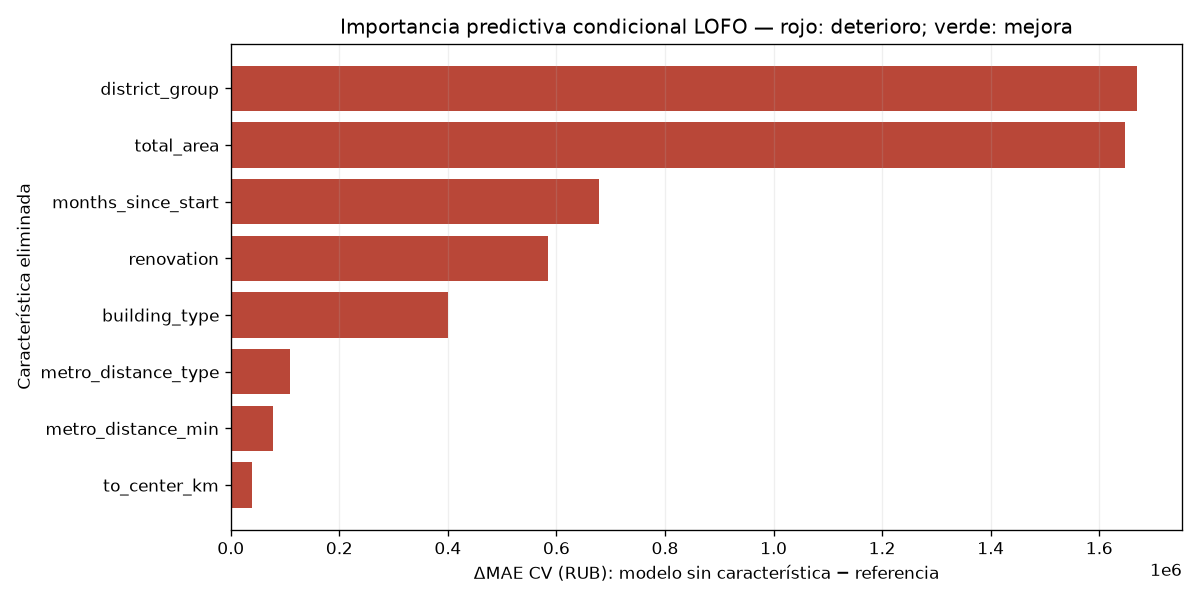

In [30]:
ref = resumen_lofo.loc['Referencia']
display(Markdown('### Modelo de referencia\n\n'+', '.join('`'+c+'`' for c in CARACTERISTICAS_LOFO)
    +f". **{modelos_lofo['Referencia']['n_columnas']} columnas OLS**. "
    +f"MAE CV **{ref['mae_media']:,.2f} ± {ref['mae_sd']:,.2f} RUB**; "
    +f"RMSE CV **{ref['rmse_media']:,.2f} ± {ref['rmse_sd']:,.2f} RUB**."))
tabla_lofo = pd.DataFrame([{'Característica eliminada':c,
    'MAE CV media ± SD (RUB)':f"{resumen_lofo.loc[c,'mae_media']:,.2f} ± {resumen_lofo.loc[c,'mae_sd']:,.2f}",
    'RMSE CV media ± SD (RUB)':f"{resumen_lofo.loc[c,'rmse_media']:,.2f} ± {resumen_lofo.loc[c,'rmse_sd']:,.2f}",
    'ΔMAE (RUB)':resumen_lofo.loc[c,'delta_mae_media'],'ΔMAE (%)':resumen_lofo.loc[c,'delta_mae_pct'],
    'ΔRMSE (RUB)':resumen_lofo.loc[c,'delta_rmse_media'],'ΔRMSE (%)':resumen_lofo.loc[c,'delta_rmse_pct']} for c in orden_lofo])
display(Markdown('### Comparación LOFO\n\n'+tabla_markdown(tabla_lofo,decimales=4)))
tabla_estabilidad_lofo = pd.DataFrame([{'Característica':c,
    'ΔMAE emparejado media ± SD RUB':f"{resumen_lofo.loc[c,'delta_mae_media']:,.2f} ± {resumen_lofo.loc[c,'delta_mae_sd']:,.2f}",
    'Folds empeora':int(resumen_lofo.loc[c,'folds_empeora']),'Folds mejora':int(resumen_lofo.loc[c,'folds_mejora']),
    'Folds empata':int(resumen_lofo.loc[c,'folds_empata'])} for c in orden_lofo])
display(Markdown('**Variabilidad de las diferencias emparejadas**\n\n'+tabla_markdown(tabla_estabilidad_lofo)))
deltas_fold_lofo = resultados_folds_lofo.loc[~resultados_folds_lofo['configuracion'].eq('Referencia')].pivot(
    index='configuracion',columns='fold',values='delta_mae_rub').reindex(orden_lofo)
deltas_fold_lofo.columns = [f'ΔMAE fold {c} RUB' for c in deltas_fold_lofo.columns]
display(Markdown('**Diferencias por período**\n\n'+tabla_markdown(deltas_fold_lofo,indice=True,decimales=2)))
fig_lofo,ax = plt.subplots(figsize=(10,5))
valores = resumen_lofo.loc[orden_lofo,'delta_mae_media']
colores = ['#b94738' if v>0 else '#27826c' for v in valores]
ax.barh(orden_lofo,valores,color=colores)
ax.invert_yaxis()
ax.axvline(0,color='black',linewidth=1)
ax.set(xlabel='ΔMAE CV (RUB): modelo sin característica − referencia',ylabel='Característica eliminada',
    title='Importancia predictiva condicional LOFO — rojo: deterioro; verde: mejora')
ax.grid(axis='x',alpha=.2)
fig_lofo.tight_layout()
display(fig_lofo)
plt.close(fig_lofo)


## Conclusiones — Importancia LOFO


In [31]:
mayores = [c for c in orden_lofo if resumen_lofo.loc[c,'delta_mae_media']>0][:3]
menores = sorted(CARACTERISTICAS_LOFO,key=lambda c:abs(resumen_lofo.loc[c,'delta_mae_pct']))[:2]
mejoras = [c for c in orden_lofo if resumen_lofo.loc[c,'delta_mae_media']<0]
mixtas = [c for c in orden_lofo if resumen_lofo.loc[c,'folds_mejora']>0 and resumen_lofo.loc[c,'folds_empeora']>0]
frases = []
for c in mayores:
    m = resumen_lofo.loc[c]
    frases.append(f"Eliminar `{c}` incrementó el MAE **{m['delta_mae_pct']:.3f} %** "
        f"({m['delta_mae_media']:,.2f} RUB), con deterioro en {int(m['folds_empeora'])}/5 folds.")
frases.append('Los menores cambios absolutos de MAE fueron '+', '.join(
    f"`{c}` ({resumen_lofo.loc[c,'delta_mae_pct']:+.4f} %)" for c in menores)+
    '; son menores en esta comparación, sin imponer umbrales de relevancia.')
intermedias = [c for c in orden_lofo if c not in mayores and c not in menores and c not in mejoras]
if intermedias:
    frases.append('Aportes intermedios en este ranking: '+', '.join(f"`{c}` ({resumen_lofo.loc[c,'delta_mae_pct']:+.3f} %)" for c in intermedias)+'.')
if mixtas:
    frases.append('Diferencias con signos mixtos entre períodos: '+', '.join('`'+c+'`' for c in mixtas)+'.')
if mejoras:
    frases.append('Eliminar mejoró el MAE promedio para '+', '.join('`'+c+'`' for c in mejoras)+
        '; son candidatas a una eliminación experimental posterior, atendiendo a su variabilidad temporal.')
else:
    frases.append('Ninguna eliminación mejoró el MAE promedio; no se propone retirar una característica por una mejora observada inexistente. '
        'Las de menor aporte incremental merecen revisión posterior si se prioriza simplicidad.')
if not mejoras and resumen_lofo.drop(index='Referencia')['folds_empeora'].eq(5).all():
    frases.append('Con MAE como criterio principal, estos resultados respaldan conservar las ocho características: todas las exclusiones empeoraron el MAE en los cinco folds.')
for c in CARACTERISTICAS_LOFO:
    if resumen_lofo.loc[c,'delta_mae_media']>0 and resumen_lofo.loc[c,'delta_rmse_media']<0:
        frases.append(f"Sin `{c}`, el MAE aumentó {resumen_lofo.loc[c,'delta_mae_pct']:.4f} %, mientras el RMSE disminuyó {abs(resumen_lofo.loc[c,'delta_rmse_pct']):.4f} %. Este compromiso entre métricas no justifica retirarla cuando se prioriza MAE.")
frases.append('Conviene conservar las de mayor deterioro y consistencia temporal; el aporte del resto debe leerse con las diferencias emparejadas, no solo con el ranking. '
    'La importancia es condicional a las otras siete características: la redundancia puede amortiguar una eliminación. '
    'Un ΔMAE pequeño no demuestra irrelevancia estadística ni ausencia de influencia en el precio; LOFO no establece causalidad. '
    'No se cambió el DataFrame ni se combinaron exclusiones. Validation externo y Test no se usaron.')
conclusion_lofo = '\n\n'.join(frases)
display(Markdown(conclusion_lofo))


Eliminar `district_group` incrementó el MAE **108.557 %** (1,668,951.00 RUB), con deterioro en 5/5 folds.

Eliminar `total_area` incrementó el MAE **107.154 %** (1,647,371.16 RUB), con deterioro en 5/5 folds.

Eliminar `months_since_start` incrementó el MAE **44.119 %** (678,275.69 RUB), con deterioro en 5/5 folds.

Los menores cambios absolutos de MAE fueron `to_center_km` (+2.5656 %), `metro_distance_min` (+5.1117 %); son menores en esta comparación, sin imponer umbrales de relevancia.

Aportes intermedios en este ranking: `renovation` (+37.983 %), `building_type` (+26.011 %), `metro_distance_type` (+7.040 %).

Ninguna eliminación mejoró el MAE promedio; no se propone retirar una característica por una mejora observada inexistente. Las de menor aporte incremental merecen revisión posterior si se prioriza simplicidad.

Con MAE como criterio principal, estos resultados respaldan conservar las ocho características: todas las exclusiones empeoraron el MAE en los cinco folds.

Sin `to_center_km`, el MAE aumentó 2.5656 %, mientras el RMSE disminuyó 0.2420 %. Este compromiso entre métricas no justifica retirarla cuando se prioriza MAE.

Conviene conservar las de mayor deterioro y consistencia temporal; el aporte del resto debe leerse con las diferencias emparejadas, no solo con el ranking. La importancia es condicional a las otras siete características: la redundancia puede amortiguar una eliminación. Un ΔMAE pequeño no demuestra irrelevancia estadística ni ausencia de influencia en el precio; LOFO no establece causalidad. No se cambió el DataFrame ni se combinaron exclusiones. Validation externo y Test no se usaron.

## Registro — Importancia LOFO en MLflow


In [32]:
from uuid import uuid4
from mlflow.entities import RunTag

grupo_lofo = uuid4().hex
ids_runs_lofo = {}
contexto_lofo = {'dataset_sha256':huella_datos,'configuracion_dataframe':configuracion_seleccionada,
    'caracteristicas_referencia':list(CARACTERISTICAS_LOFO),'preprocesamiento':config_preprocesamiento,
    'mapa_train':preparacion_ols['trazabilidad'],'folds':trazabilidad_lofo,'grupo_lofo':grupo_lofo,
    'referencias_feature_selection':REFERENCIAS_FS_LOFO,'target':'log(price_rub)','retransformacion':'Duan por entrenamiento/modelo',
    'porcentajes_globales':'100*(media_CV_reducido/media_CV_referencia - 1)',
    'sd_diferencias':'SD entre los cinco deltas emparejados; ddof=1','validation_externo_utilizado':False,'test_utilizado':False}
with TemporaryDirectory(prefix='lofo_resultados_') as temporal:
    carpeta = Path(temporal)
    for configuracion,excluir in CONFIGURACIONES_LOFO.items():
        r = modelos_lofo[configuracion]
        cv = resultados_folds_lofo.loc[resultados_folds_lofo['configuracion'].eq(configuracion)].copy()
        m = resumen_lofo.loc[configuracion]
        destino = carpeta/configuracion
        destino.mkdir()
        seleccion = {'caracteristicas_referencia':list(CARACTERISTICAS_LOFO),'utilizadas':r['caracteristicas'],
            'excluida':excluir,'bloques_utilizados':{c:columnas_por_caracteristica[c] for c in r['caracteristicas']},
            'columnas_modelo':r['ejemplo_diseno'].columns.tolist(),'rango':r['rango'],
            'run_kmeans8':RUN_KMEANS8,'folds':[1,2,3,4,5],
            'modelo_ajustado':'Train completo; sin métricas de Validation externo',
            'inferencia':'Mapa K8, exclusiones previas, preprocesador existente; columnas_modelo con const; exp(predict)*Duan.'}
        (destino/'configuracion_lofo.json').write_text(json.dumps(seleccion,ensure_ascii=False,indent=2),encoding='utf8')
        (destino/'resultados_por_fold.json').write_text(cv.to_json(orient='records'),encoding='utf8')
        if excluir is None:
            (destino/'tabla_lofo.md').write_text(tabla_markdown(tabla_lofo,decimales=6)+'\n\n'
                +tabla_markdown(tabla_estabilidad_lofo)+'\n\n'+conclusion_lofo,encoding='utf8')
            (destino/'resultados_todos_los_folds.json').write_text(resultados_folds_lofo.to_json(orient='records'),encoding='utf8')
            (destino/'resumen_lofo.json').write_text(resumen_lofo.reset_index().to_json(orient='records'),encoding='utf8')
            fig_lofo.savefig(destino/'importancia_lofo.png',dpi=150)
        else:
            (destino/'referencia_artefactos.json').write_text(json.dumps({'run_referencia':ids_runs_lofo['Referencia'],
                'tabla':f"runs:/{ids_runs_lofo['Referencia']}/resultados/tabla_lofo.md",
                'grafico':f"runs:/{ids_runs_lofo['Referencia']}/resultados/importancia_lofo.png"},indent=2),encoding='utf8')
        registro = {**r,'metricas':{s:dict(v) for s,v in r['metricas'].items()}}
        registro['metricas']['cv'] = {'mae_mean':float(m['mae_media']),'mae_std':float(m['mae_sd']),
            'rmse_mean':float(m['rmse_media']),'rmse_std':float(m['rmse_sd']),
            'r2_mean':float(m['r2_media']),'mape_mean':float(m['mape_media'])}
        registro['metricas']['lofo'] = {k:float(m[k]) for k in ['delta_mae_media','delta_mae_sd','delta_mae_pct',
            'delta_rmse_media','delta_rmse_sd','delta_rmse_pct','folds_empeora','folds_mejora','folds_empata']}
        for fila in cv.to_dict('records'):
            registro['metricas'][f"fold_{fila['fold']}"] = {k:float(fila[k]) for k in
                ['validation_mae_rub','validation_rmse_rub','delta_mae_rub','delta_rmse_rub','duan']}
        nota = ('Referencia LOFO de ocho características; importancia predictiva condicional, sin causalidad. '+conclusion_lofo
            if excluir is None else f"LOFO sin {excluir}: ΔMAE {m['delta_mae_media']:+,.2f} RUB ({m['delta_mae_pct']:+.4f} %); "
                f"SD de deltas {m['delta_mae_sd']:,.2f} RUB; {int(m['folds_empeora'])}/5 folds empeoran y {int(m['folds_mejora'])}/5 mejoran. "
                'Interpretación condicional a las otras siete; no se elimina definitivamente ninguna característica.')
        nombre = 'LOFO_8Features_Reference' if excluir is None else f'LOFO_Sin_{excluir}'
        ids_runs_lofo[configuracion] = registrar_experimento(nombre,registro,cliente=cliente_mlflow,contexto=contexto_lofo,
            parametros={'grupo_lofo':grupo_lofo,'caracteristica_excluida':excluir or 'ninguna',
                'run_referencia_lofo':ids_runs_lofo.get('Referencia','este_run'),
                'n_features_referencia':8,'n_features_modelo':len(r['caracteristicas']),
                'run_kmeans8':RUN_KMEANS8,'cv_folds':5,'cv_meses_validation':MESES_VALID_FOLD,'sd_ddof':1,
                'duan_por_modelo_y_fold':True,'seleccion_automatica':False,'validation_externo_evaluado':False},
            nota=nota,cv=cv,artefactos=sorted(destino.iterdir()))
        cliente_mlflow.log_batch(ids_runs_lofo[configuracion],tags=[RunTag('lofo_group_id',grupo_lofo),
            RunTag('lofo_reference_run_id',ids_runs_lofo['Referencia']),
            RunTag('lofo_role','reference' if excluir is None else 'leave_one_feature_out')])
        run = cliente_mlflow.get_run(ids_runs_lofo[configuracion])
        assert run.info.status=='FINISHED' and run.info.experiment_id==experimento_existente.experiment_id
        assert run.data.tags['lofo_group_id']==grupo_lofo and run.data.tags['test_evaluado']=='false'
        assert not any(k.startswith('validation_') for k in run.data.metrics)
        print(f"Registrado {nombre}: {ids_runs_lofo[configuracion]}",flush=True)
assert len(ids_runs_lofo)==9
assert huella_tabla(df_trabajo)==huella_pre_lofo and huella_tabla(datos_base)==huella_base_memoria
assert hashlib.sha256(archivo_datos.read_bytes()).hexdigest()==huella_datos and X_test_ols is None
display(Markdown('\n\n'.join(f"[{c}]({TRACKING_URI}/#/experiments/{experimento_existente.experiment_id}/runs/{r})"
    for c,r in ids_runs_lofo.items())))


🏃 View run LOFO_8Features_Reference at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/232089040f3348cdac62648a04d6f757
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1
Registrado LOFO_8Features_Reference: 232089040f3348cdac62648a04d6f757
🏃 View run LOFO_Sin_total_area at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/5abcb8796b4a4c9f9056bf5720f7eccb
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1
Registrado LOFO_Sin_total_area: 5abcb8796b4a4c9f9056bf5720f7eccb
🏃 View run LOFO_Sin_metro_distance_min at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/50234e0bd53b4594bfec7c63a4c9ea44
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1
Registrado LOFO_Sin_metro_distance_min: 50234e0bd53b4594bfec7c63a4c9ea44
🏃 View run LOFO_Sin_to_center_km at: https:/

[Referencia](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/232089040f3348cdac62648a04d6f757)

[total_area](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/5abcb8796b4a4c9f9056bf5720f7eccb)

[metro_distance_min](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/50234e0bd53b4594bfec7c63a4c9ea44)

[to_center_km](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/44e528f903434d26b2ee17d2ecaa54ce)

[metro_distance_type](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/88ab6ca43f6541348f8014136988ede8)

[months_since_start](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/a4e1f8d0648f40ab8d4979ab7185c03f)

[district_group](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/404ca4d5c9674e68aa3a8407d8737bc1)

[building_type](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/2e4a6688906645c58f74e231a843b41e)

[renovation](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/26981ed6ac454f2fb467ec1d8687acfd)

## Experimento 2 — Best Subset Selection exhaustivo

Se evalúan las 255 combinaciones no vacías de las ocho características de LOFO. La selección usa MAE de CV temporal y una tolerancia práctica del 1 %; AIC y BIC son métricas complementarias, a diferencia del BSS anterior.


In [33]:
from itertools import combinations
from math import comb
import mlflow.statsmodels

FEATURES_BSS8 = ('total_area','metro_distance_min','to_center_km','metro_distance_type',
    'months_since_start','district_group','building_type','renovation')
RUNS_LOFO_BSS8 = {'Referencia':'232089040f3348cdac62648a04d6f757',
    'total_area':'5abcb8796b4a4c9f9056bf5720f7eccb','metro_distance_min':'50234e0bd53b4594bfec7c63a4c9ea44',
    'to_center_km':'44e528f903434d26b2ee17d2ecaa54ce','metro_distance_type':'88ab6ca43f6541348f8014136988ede8',
    'months_since_start':'a4e1f8d0648f40ab8d4979ab7185c03f','district_group':'404ca4d5c9674e68aa3a8407d8737bc1',
    'building_type':'2e4a6688906645c58f74e231a843b41e','renovation':'26981ed6ac454f2fb467ec1d8687acfd'}
TOLERANCIA_BSS8 = .01

def combinaciones_bss8(caracteristicas=FEATURES_BSS8):
    if tuple(caracteristicas)!=FEATURES_BSS8:
        raise ValueError('Utilizar exactamente las ocho características acordadas, en su orden canónico.')
    return [{'id':sum(1<<FEATURES_BSS8.index(c) for c in cs),'caracteristicas':list(cs),'n_caracteristicas':k}
        for k in range(1,len(caracteristicas)+1) for cs in combinations(caracteristicas,k)]

def evaluar_subconjunto_bss8(preparacion,caracteristicas,*,run_reutilizable=None):
    if not caracteristicas or len(set(caracteristicas))!=len(caracteristicas) or not set(caracteristicas)<=set(FEATURES_BSS8):
        raise ValueError('Subconjunto no vacío de las ocho características, sin duplicados.')
    X = preparacion['matrices']['train']
    assert datos_base.loc[X.index,'dataset_split'].eq('train').all()
    cols = [col for c in caracteristicas for col in preparacion['bloques'][c]]
    xs = seleccionar_caracteristicas_ols(X,caracteristicas,bloques=preparacion['bloques'])
    if run_reutilizable is None:
        modelo = sm.OLS(np.log(datos_base.loc[X.index,objetivo]),sm.add_constant(xs,has_constant='add'),missing='raise').fit()
        duan,metricas_guardadas = None,None
    else:
        # Solo Train completo y un modelo LOFO idéntico; cargar coeficientes sin reajustar.
        assert X.index.equals(X_train_ols.index)
        contexto = leer_json_remoto(cliente_mlflow,run_reutilizable,'preparacion/contexto.json',cache_transformaciones)
        assert contexto['dataset_sha256']==huella_datos and contexto['configuracion_dataframe']==configuracion_seleccionada
        assert contexto['preprocesamiento']==config_preprocesamiento and contexto['mapa_train']==preparacion['trazabilidad']
        configuracion = leer_json_remoto(cliente_mlflow,run_reutilizable,'resultados/configuracion_lofo.json',cache_transformaciones)
        assert configuracion['utilizadas']==caracteristicas
        assert configuracion['columnas_modelo']==['const']+cols
        run = cliente_mlflow.get_run(run_reutilizable)
        modelo = mlflow.statsmodels.load_model(f'runs:/{run_reutilizable}/modelo')
        duan = float(run.data.params['duan_factor_train'])
        metricas_guardadas = {k.removeprefix('train_'):v for k,v in run.data.metrics.items() if k.startswith('train_')}
    assert modelo.model.exog_names==['const']+cols
    adaptador = {'seleccionadas':list(caracteristicas),'historial':pd.DataFrame([
        {'paso':len(caracteristicas),'seleccionadas':list(caracteristicas)}]),
        'modelos_trayectoria':{len(caracteristicas):modelo}}
    r = evaluar_forward(adaptador,preparacion,duan_train=duan,metricas_train=metricas_guardadas)
    r['run_modelo_reutilizado'] = run_reutilizable
    return r


In [34]:
huella_pre_bss8 = huella_tabla(df_trabajo)
grid_bss8 = combinaciones_bss8()
assert len(grid_bss8)==len({s['id'] for s in grid_bss8})==255
assert {k:sum(s['n_caracteristicas']==k for s in grid_bss8) for k in range(1,9)}=={k:comb(8,k) for k in range(1,9)}
contexto_lofo_bss8 = leer_json_remoto(cliente_mlflow,RUNS_LOFO_BSS8['Referencia'],'preparacion/contexto.json',cache_transformaciones)
assert contexto_lofo_bss8['dataset_sha256']==huella_datos
assert contexto_lofo_bss8['caracteristicas_referencia']==list(FEATURES_BSS8)
assert contexto_lofo_bss8['configuracion_dataframe']==configuracion_seleccionada
assert contexto_lofo_bss8['preprocesamiento']==config_preprocesamiento
lofo_cv_bss8 = pd.DataFrame(leer_json_remoto(cliente_mlflow,RUNS_LOFO_BSS8['Referencia'],
    'resultados/resultados_todos_los_folds.json',cache_transformaciones))
assert len(lofo_cv_bss8)==45 and not lofo_cv_bss8.duplicated(['configuracion','fold']).any()
mapa_config_lofo_bss8 = {tuple(c for c in FEATURES_BSS8 if c!=excluida):nombre
    for nombre,excluida in [('Referencia',None),*((c,c) for c in FEATURES_BSS8)]}
filas_bss8,trazas_bss8 = [],{}
with threadpool_limits(limits=1):
    for fold in range(1,N_FOLDS+1):
        prep = preparar_matrices_fold(fold)
        xt,xv = prep['matrices']['train'],prep['matrices']['validation']
        anterior = contexto_lofo_bss8['folds'][str(fold)]
        assert prep['trazabilidad']==anterior['mapa'] and prep['bloques']==anterior['bloques']
        assert {s:huella_tabla(m) for s,m in prep['matrices'].items()}==anterior['huellas_matrices']
        assert huella_tabla(datos_base.loc[xt.index,['id']])==anterior['ids_train_sha256']
        assert huella_tabla(datos_base.loc[xv.index,['id']])==anterior['ids_validation_sha256']
        assert datos_base.loc[xt.index.union(xv.index),'dataset_split'].eq('train').all()
        assert datos_base.loc[xt.index,'date_posted_dt'].max()<datos_base.loc[xv.index,'date_posted_dt'].min()
        trazas_bss8[str(fold)] = anterior
        reutilizados = 0
        for sub in grid_bss8:
            caracteristicas = sub['caracteristicas']
            nombre_lofo = mapa_config_lofo_bss8.get(tuple(caracteristicas))
            if nombre_lofo is not None:
                cache = lofo_cv_bss8.loc[lofo_cv_bss8['fold'].eq(fold)&lofo_cv_bss8['configuracion'].eq(nombre_lofo)]
                assert len(cache)==1
                fila = cache.iloc[0]
                assert fila['n_train']==len(xt) and fila['n_validation']==len(xv)
                valores = {k:float(fila[k]) for k in fila.index if k.startswith(('train_','validation_'))}
                rango,duan = int(fila['rango']),float(fila['duan'])
                reutilizados += 1
            else:
                r = evaluar_subconjunto_bss8(prep,caracteristicas)
                valores = {f'{s}_{m}':v for s,ms in r['metricas'].items() for m,v in ms.items() if v is not None}
                rango,duan = r['rango'],r['duan']
            ncols = sum(len(prep['bloques'][c]) for c in caracteristicas)
            filas_bss8.append({'id':sub['id'],'fold':fold,'n_caracteristicas':len(caracteristicas),
                'n_columnas':ncols,'rango':rango,'duan':duan,'n_train':len(xt),'n_validation':len(xv),
                'reutilizado_lofo':nombre_lofo is not None,**valores})
        print(f'BSS8 fold {fold}/5: 255 combinaciones; {reutilizados} resultados LOFO reutilizados.',flush=True)

cv_completo_bss8 = pd.DataFrame(filas_bss8)
assert len(cv_completo_bss8)==1275 and not cv_completo_bss8.duplicated(['id','fold']).any()
assert cv_completo_bss8.groupby('id')['fold'].nunique().eq(5).all()
resumen_bss8 = cv_completo_bss8.groupby('id').agg(n_caracteristicas=('n_caracteristicas','first'),
    n_columnas=('n_columnas','first'),rango=('rango','first'),mae_media=('validation_mae_rub','mean'),
    mae_sd=('validation_mae_rub','std'),rmse_media=('validation_rmse_rub','mean'),rmse_sd=('validation_rmse_rub','std'),
    r2_media=('validation_r2','mean'),mape_media=('validation_mape_pct','mean')).reset_index()
por_id_bss8 = {s['id']:s['caracteristicas'] for s in grid_bss8}
resumen_bss8['caracteristicas'] = resumen_bss8['id'].map(por_id_bss8)
resumen_bss8 = resumen_bss8.sort_values(['mae_media','mae_sd','rango','id']).reset_index(drop=True)
minimo_bss8 = resumen_bss8.iloc[0]
limite_bss8 = float(minimo_bss8['mae_media']*(1+TOLERANCIA_BSS8))
elegibles_bss8 = resumen_bss8.loc[resumen_bss8['mae_media'].le(limite_bss8)]
parsimonioso_bss8 = elegibles_bss8.sort_values(['n_caracteristicas','mae_media','mae_sd','rango','id']).iloc[0]
id_minimo_bss8,id_parsimonioso_bss8 = int(minimo_bss8['id']),int(parsimonioso_bss8['id'])
mejores_tamano_bss8 = resumen_bss8.sort_values(['mae_media','mae_sd','rango','id']).groupby('n_caracteristicas',sort=True).head(1).sort_values('n_caracteristicas').copy()
estabilidad_bss8 = cv_completo_bss8.loc[cv_completo_bss8['id'].eq(id_minimo_bss8),
    ['fold','validation_mae_rub','validation_rmse_rub']].merge(
        cv_completo_bss8.loc[cv_completo_bss8['id'].eq(id_parsimonioso_bss8),
            ['fold','validation_mae_rub','validation_rmse_rub']],on='fold',suffixes=('_minimo','_parsimonioso'),validate='one_to_one')
for metrica in ['mae','rmse']:
    estabilidad_bss8[f'delta_{metrica}_rub'] = estabilidad_bss8[f'validation_{metrica}_rub_parsimonioso']-estabilidad_bss8[f'validation_{metrica}_rub_minimo']
delta_pareado_bss8 = {'mae_media':float(estabilidad_bss8['delta_mae_rub'].mean()),
    'mae_sd':float(estabilidad_bss8['delta_mae_rub'].std(ddof=1)),
    'rmse_media':float(estabilidad_bss8['delta_rmse_rub'].mean()),'rmse_sd':float(estabilidad_bss8['delta_rmse_rub'].std(ddof=1)),
    'folds_empeora':int(estabilidad_bss8['delta_mae_rub'].gt(0).sum()),
    'max_delta_absoluto':float(estabilidad_bss8['delta_mae_rub'].abs().max())}
frecuencia_bss8 = pd.Series({c:sum(c in cs for cs in mejores_tamano_bss8['caracteristicas']) for c in FEATURES_BSS8},name='Apariciones en 8 mejores tamaños').sort_values(ascending=False)
print(f'BSS8: mínimo MAE, {len(por_id_bss8[id_minimo_bss8])} características; propuesta 1 %, {len(por_id_bss8[id_parsimonioso_bss8])}.',flush=True)
assert huella_tabla(df_trabajo)==huella_pre_bss8 and X_test_ols is None


BSS8 fold 1/5: 255 combinaciones; 9 resultados LOFO reutilizados.
BSS8 fold 2/5: 255 combinaciones; 9 resultados LOFO reutilizados.
BSS8 fold 3/5: 255 combinaciones; 9 resultados LOFO reutilizados.
BSS8 fold 4/5: 255 combinaciones; 9 resultados LOFO reutilizados.
BSS8 fold 5/5: 255 combinaciones; 9 resultados LOFO reutilizados.
BSS8: mínimo MAE, 8 características; propuesta 1 %, 8.


In [35]:
# Entrenar solo los ocho mejores por tamaño; reutilizar modelos LOFO compatibles de 7/8 cuando existan.
resultados_train_bss8,resultados_validacion_bss8,predicciones_finales_bss8 = {},{},{}
preparacion_solo_train_bss8 = {**preparacion_ols,'matrices':{'train':X_train_ols}}
ids_necesarios_bss8 = set(mejores_tamano_bss8['id'].astype(int))|{id_minimo_bss8,id_parsimonioso_bss8,255}
with threadpool_limits(limits=1):
    for sub_id in sorted(ids_necesarios_bss8):
        cs = por_id_bss8[sub_id]
        nombre_lofo = mapa_config_lofo_bss8.get(tuple(cs))
        run_reutilizable = RUNS_LOFO_BSS8[nombre_lofo] if nombre_lofo is not None else None
        resultados_train_bss8[sub_id] = evaluar_subconjunto_bss8(preparacion_solo_train_bss8,cs,run_reutilizable=run_reutilizable)
    # Los candidatos ya están congelados; Validation solo comprueba esas configuraciones.
    for sub_id in sorted({id_minimo_bss8,id_parsimonioso_bss8,255}):
        r = resultados_train_bss8[sub_id]
        cols = r['ejemplo_diseno'].columns.tolist()
        design = X_validation_ols.copy()
        design.insert(0,'const',1.0)
        pred = np.exp(r['modelo'].predict(design.loc[:,cols]))*r['duan']
        predicciones_finales_bss8[sub_id] = np.asarray(pred,dtype=float)
        metricas = evaluar_regresion(df_trabajo_validation[objetivo],pred)
        resultados_validacion_bss8[sub_id] = {**r,'metricas':{'train':r['metricas']['train'],'validation':metricas},
            'ejemplo_diseno':design.loc[:,cols].iloc[:5].copy()}
assert huella_tabla(df_trabajo)==huella_pre_bss8 and huella_tabla(datos_base)==huella_base_memoria
distancias_pred_bss8 = np.abs(predicciones_finales_bss8[id_parsimonioso_bss8]-predicciones_finales_bss8[id_minimo_bss8])
resumen_pred_bss8 = {'diferencia_absoluta_media_validation_rub':float(distancias_pred_bss8.mean()),
    'diferencia_absoluta_maxima_validation_rub':float(distancias_pred_bss8.max())}


## Resultados — Best Subset Selection de ocho características


### Mejores combinaciones por tamaño

| Características | Mejor combinación | MAE CV media ± SD RUB | RMSE CV media ± SD RUB | ΔMAE vs mínimo % | Parámetros OLS con intercepto | AIC Train log(RUB) | BIC Train log(RUB) |
|---|---|---|---|---|---|---|---|
| 1 | district_group | 3,894,643.19 ± 298,699.82 | 5,875,360.90 ± 470,551.88 | 153.328 | 8 | 29,528.111 | 29,604.241 |
| 2 | total_area, district_group | 2,943,111.62 ± 289,439.12 | 4,391,302.62 ± 421,692.37 | 91.436 | 9 | 8,198.800 | 8,283.389 |
| 3 | total_area, district_group, renovation | 2,664,285.66 ± 278,504.19 | 3,929,291.79 ± 407,347.00 | 73.299 | 12 | -104.737 | 5.229 |
| 4 | total_area, months_since_start, district_group, renovation | 2,377,905.85 ± 137,280.24 | 3,384,800.56 ± 214,236.44 | 54.672 | 13 | -11,481.017 | -11,362.592 |
| 5 | total_area, metro_distance_min, months_since_start, district_group, renovation | 2,006,712.51 ± 103,740.29 | 2,938,064.94 ± 177,850.84 | 30.527 | 14 | -23,570.794 | -23,443.911 |
| 6 | total_area, metro_distance_min, months_since_start, district_group, building_type, renovation | 1,646,843.91 ± 83,812.57 | 2,420,426.42 ± 138,174.87 | 7.119 | 19 | -39,090.954 | -38,921.776 |
| 7 | total_area, metro_distance_min, metro_distance_type, months_since_start, district_group, building_type, renovation | 1,576,833.64 ± 75,845.86 | 2,338,519.78 ± 124,013.39 | 2.566 | 20 | -41,173.803 | -40,996.167 |
| 8 | total_area, metro_distance_min, to_center_km, metro_distance_type, months_since_start, district_group, building_type, renovation | 1,537,389.66 ± 78,457.50 | 2,344,193.64 ± 123,682.67 | 0.000 | 21 | -43,842.784 | -43,656.688 |

**Diferencias emparejadas: parsimonioso − mínimo MAE**

| fold | validation_mae_rub_minimo | validation_rmse_rub_minimo | validation_mae_rub_parsimonioso | validation_rmse_rub_parsimonioso | delta_mae_rub | delta_rmse_rub |
|---|---|---|---|---|---|---|
| 1 | 1,447,195.869 | 2,183,313.931 | 1,447,195.869 | 2,183,313.931 | 0.000 | 0.000 |
| 2 | 1,573,818.259 | 2,398,837.139 | 1,573,818.259 | 2,398,837.139 | 0.000 | 0.000 |
| 3 | 1,497,962.584 | 2,355,431.321 | 1,497,962.584 | 2,355,431.321 | 0.000 | 0.000 |
| 4 | 1,515,928.968 | 2,274,043.487 | 1,515,928.968 | 2,274,043.487 | 0.000 | 0.000 |
| 5 | 1,652,042.602 | 2,509,342.326 | 1,652,042.602 | 2,509,342.326 | 0.000 | 0.000 |

<Figure size 900x400 with 1 Axes>

<Figure size 900x400 with 1 Axes>

<Figure size 900x400 with 1 Axes>

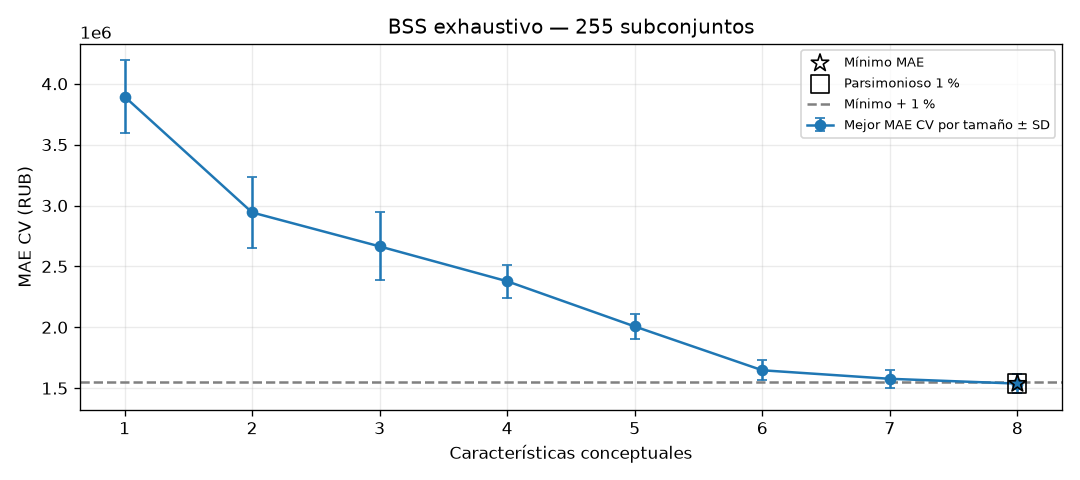

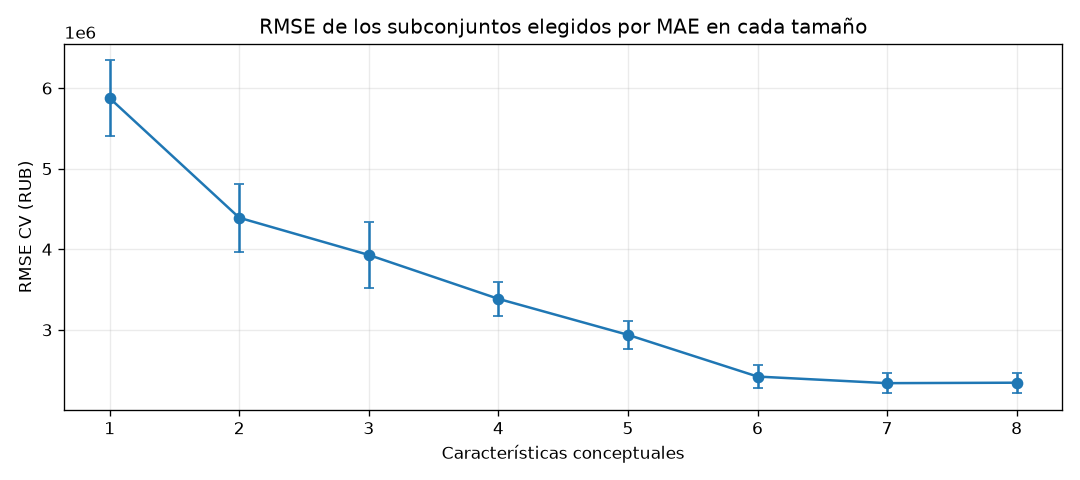

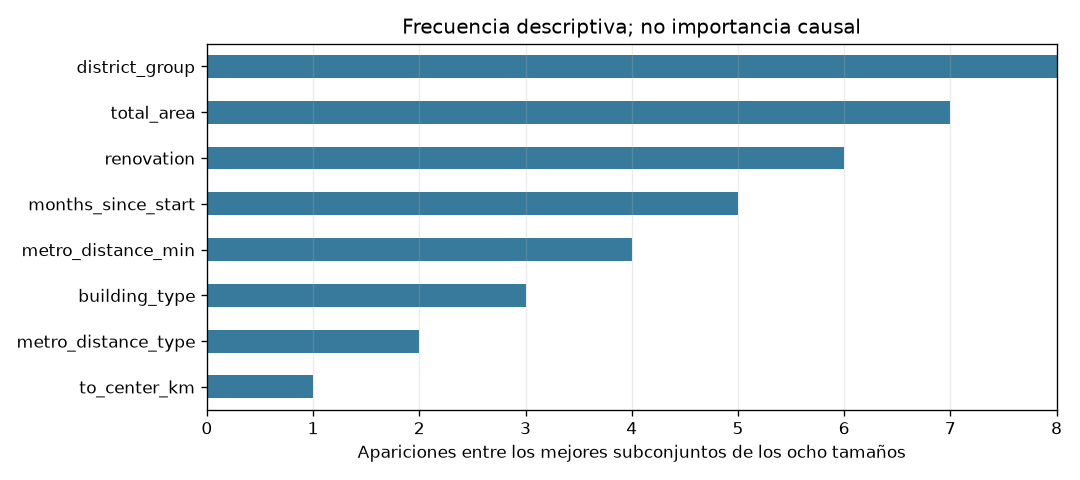

In [36]:
tabla_mejores_bss8 = pd.DataFrame([{'Características':int(row['n_caracteristicas']),
    'Mejor combinación':', '.join(row['caracteristicas']),
    'MAE CV media ± SD RUB':f"{row['mae_media']:,.2f} ± {row['mae_sd']:,.2f}",
    'RMSE CV media ± SD RUB':f"{row['rmse_media']:,.2f} ± {row['rmse_sd']:,.2f}",
    'ΔMAE vs mínimo %':100*(row['mae_media']/minimo_bss8['mae_media']-1),
    'Parámetros OLS con intercepto':resultados_train_bss8[int(row['id'])]['rango'],
    'AIC Train log(RUB)':resultados_train_bss8[int(row['id'])]['metricas']['train']['aic_log'],
    'BIC Train log(RUB)':resultados_train_bss8[int(row['id'])]['metricas']['train']['bic_log']}
    for row in mejores_tamano_bss8.to_dict('records')])
display(Markdown('### Mejores combinaciones por tamaño\n\n'+tabla_markdown(tabla_mejores_bss8,decimales=3)))
display(Markdown('**Diferencias emparejadas: parsimonioso − mínimo MAE**\n\n'+tabla_markdown(estabilidad_bss8,decimales=3)))
figuras_bss8 = {}
fig,ax = plt.subplots(figsize=(9,4))
ax.errorbar(mejores_tamano_bss8['n_caracteristicas'],mejores_tamano_bss8['mae_media'],yerr=mejores_tamano_bss8['mae_sd'],fmt='o-',capsize=3,label='Mejor MAE CV por tamaño ± SD')
for row,label,marker in [(minimo_bss8,'Mínimo MAE','*'),(parsimonioso_bss8,'Parsimonioso 1 %','s')]:
    ax.scatter(row['n_caracteristicas'],row['mae_media'],s=120,marker=marker,facecolors='none',edgecolors='black',label=label,zorder=4)
ax.axhline(limite_bss8,ls='--',color='gray',label='Mínimo + 1 %')
ax.set(xlabel='Características conceptuales',ylabel='MAE CV (RUB)',title='BSS exhaustivo — 255 subconjuntos')
ax.set_xticks(range(1,9));ax.grid(alpha=.25);ax.legend(fontsize=8);fig.tight_layout()
figuras_bss8['mae_cv'] = fig;display(fig);plt.close(fig)
fig,ax = plt.subplots(figsize=(9,4))
ax.errorbar(mejores_tamano_bss8['n_caracteristicas'],mejores_tamano_bss8['rmse_media'],yerr=mejores_tamano_bss8['rmse_sd'],fmt='o-',capsize=3)
ax.set(xlabel='Características conceptuales',ylabel='RMSE CV (RUB)',title='RMSE de los subconjuntos elegidos por MAE en cada tamaño')
ax.set_xticks(range(1,9));ax.grid(alpha=.25);fig.tight_layout()
figuras_bss8['rmse_cv'] = fig;display(fig);plt.close(fig)
fig,ax = plt.subplots(figsize=(9,4))
frecuencia_bss8.sort_values().plot.barh(ax=ax,color='#387a9b')
ax.set(xlabel='Apariciones entre los mejores subconjuntos de los ocho tamaños',ylabel='',title='Frecuencia descriptiva; no importancia causal')
ax.set_xlim(0,8);ax.grid(axis='x',alpha=.25);fig.tight_layout()
figuras_bss8['frecuencia'] = fig;display(fig);plt.close(fig)


In [37]:
baseline_bss8 = cliente_mlflow.get_run(RUNS_REFERENCIA['Baseline log'])
particiones_baseline_bss8 = leer_json_remoto(cliente_mlflow,baseline_bss8.info.run_id,'preparacion/particiones.json',cache_transformaciones)
particiones_guardadas = pd.DataFrame(particiones_baseline_bss8).set_index('dataset_split')
assert baseline_bss8.data.tags['dataset_sha256']==huella_datos
for split in ['train','validation']:
    assert int(particiones_guardadas.loc[split,'observaciones'])==len(conjuntos[split])
    assert particiones_guardadas.loc[split,'desde']==str(conjuntos[split]['date_posted_dt'].min().date())
    assert particiones_guardadas.loc[split,'hasta']==str(conjuntos[split]['date_posted_dt'].max().date())
assert baseline_bss8.data.params['particion']=='dataset_split_persistido'
assert baseline_bss8.data.params['transformacion_objetivo']=='log'
assert baseline_bss8.data.params['escala_metricas']=='RUB'
assert float(baseline_bss8.data.params['duan_factor_train'])>0
comparabilidad_baseline_bss8 = {'run_id':baseline_bss8.info.run_id,'dataset_sha256':huella_datos,
    'particiones_persistidas_mismo_csv':True,'filas_y_periodos_train_validation_verificados':True,
    'metricas_predictivas':'RUB con Duan de Train','aic_bic_baseline':'Likelihood lognormal en RUB con Jacobiano, no comparable directamente con log(RUB)',
    'cv_baseline':'No se agregan métricas de otros Runs sin validación de compatibilidad.'}
columnas_candidatos_bss8 = {}
for nombre,sub_id in [('Modelo 8 características',255),('BSS mínimo MAE',id_minimo_bss8),('BSS parsimonioso',id_parsimonioso_bss8)]:
    r = resultados_validacion_bss8[sub_id]
    cv = resumen_bss8.loc[resumen_bss8['id'].eq(sub_id)].iloc[0]
    tr,va = r['metricas']['train'],r['metricas']['validation']
    columnas_candidatos_bss8[nombre] = {'Características':len(r['caracteristicas']),'Columnas OLS':r['n_columnas'],
        'MAE CV media ± SD RUB':f"{cv['mae_media']:,.2f} ± {cv['mae_sd']:,.2f}",
        'RMSE CV media ± SD RUB':f"{cv['rmse_media']:,.2f} ± {cv['rmse_sd']:,.2f}",
        'ΔMAE CV vs ocho %':100*(cv['mae_media']/resumen_bss8.loc[resumen_bss8['id'].eq(255),'mae_media'].item()-1),
        'MAE Validation RUB':va['mae_rub'],'RMSE Validation RUB':va['rmse_rub'],'R² Validation':va['r2'],
        'MAPE Validation %':va['mape_pct'],'RSS Validation RUB²':va['rss_rub2'],
        'AIC Train log(RUB)':tr['aic_log'],'BIC Train log(RUB)':tr['bic_log'],
        'R² ajustado Train log(RUB)':tr['r2_ajustado_log'],'RSS Train log(RUB)²':tr['rss_log'],
        'R² Train RUB':tr['r2'],'R² ajustado Train RUB descriptivo':tr['r2_ajustado'],
        'RSS Train RUB²':tr['rss_rub2'],'MAE Train RUB':tr['mae_rub'],'RMSE Train RUB':tr['rmse_rub'],'MAPE Train %':tr['mape_pct']}
m = baseline_bss8.data.metrics
columnas_candidatos_bss8['Baseline original (log)'] = {'Características':int(baseline_bss8.data.params['n_caracteristicas_originales']),
    'Columnas OLS':int(baseline_bss8.data.params['n_columnas_predictoras']),
    'MAE CV media ± SD RUB':'No registrado en este Run','RMSE CV media ± SD RUB':'No registrado en este Run',
    'ΔMAE CV vs ocho %':None,**{label:m.get(clave) for label,clave in {
        'MAE Validation RUB':'validation_mae_rub','RMSE Validation RUB':'validation_rmse_rub','R² Validation':'validation_r2',
        'MAPE Validation %':'validation_mape_pct','RSS Validation RUB²':'validation_rss_rub2',
        'AIC Train log(RUB)':'train_aic_log','BIC Train log(RUB)':'train_bic_log','R² ajustado Train log(RUB)':'train_r2_ajustado_log',
        'RSS Train log(RUB)²':'train_rss_log','R² Train RUB':'train_r2','R² ajustado Train RUB descriptivo':'train_r2_ajustado',
        'RSS Train RUB²':'train_rss_rub2','MAE Train RUB':'train_mae_rub','RMSE Train RUB':'train_rmse_rub','MAPE Train %':'train_mape_pct'}.items()}}
tabla_candidatos_bss8 = pd.DataFrame(columnas_candidatos_bss8).rename_axis('Métrica').reset_index()
display(Markdown('### Candidatos y comprobación externa\n\n'+tabla_markdown(tabla_candidatos_bss8,decimales=3)))
display(Markdown('El baseline conserva AIC/BIC en likelihood lognormal de RUB con Jacobiano; sus valores no se mezclan con AIC/BIC en log(RUB). '
    'Los campos log o de CV no registrados se dejan sin completar. La selección y la tolerancia del 1 % quedaron fijadas antes de consultar Validation.'))


### Candidatos y comprobación externa

| Métrica | Modelo 8 características | BSS mínimo MAE | BSS parsimonioso | Baseline original (log) |
|---|---|---|---|---|
| Características | 8 | 8 | 8 | 32 |
| Columnas OLS | 20 | 20 | 20 | 185 |
| MAE CV media ± SD RUB | 1,537,389.66 ± 78,457.50 | 1,537,389.66 ± 78,457.50 | 1,537,389.66 ± 78,457.50 | No registrado en este Run |
| RMSE CV media ± SD RUB | 2,344,193.64 ± 123,682.67 | 2,344,193.64 ± 123,682.67 | 2,344,193.64 ± 123,682.67 | No registrado en este Run |
| ΔMAE CV vs ocho % | 0.000 | 0.000 | 0.000 | — |
| MAE Validation RUB | 1,979,743.611 | 1,979,743.611 | 1,979,743.611 | 1,985,623.415 |
| RMSE Validation RUB | 2,898,546.752 | 2,898,546.752 | 2,898,546.752 | 2,924,096.551 |
| R² Validation | 0.910 | 0.910 | 0.910 | 0.909 |
| MAPE Validation % | 14.560 | 14.560 | 14.560 | 14.463 |
| RSS Validation RUB² | 44,175,472,261,595,336.000 | 44,175,472,261,595,336.000 | 44,175,472,261,595,336.000 | 44,957,691,075,862,680.000 |
| AIC Train log(RUB) | -43,842.784 | -43,842.784 | -43,842.784 | — |
| BIC Train log(RUB) | -43,656.688 | -43,656.688 | -43,656.688 | — |
| R² ajustado Train log(RUB) | 0.956 | 0.956 | 0.956 | — |
| RSS Train log(RUB)² | 579.300 | 579.300 | 579.300 | — |
| R² Train RUB | 0.938 | 0.938 | 0.938 | 0.949 |
| R² ajustado Train RUB descriptivo | 0.938 | 0.938 | 0.938 | 0.948 |
| RSS Train RUB² | 143,939,354,593,899,168.000 | 143,939,354,593,899,168.000 | 143,939,354,593,899,168.000 | 119,167,715,735,840,608.000 |
| MAE Train RUB | 1,321,851.169 | 1,321,851.169 | 1,321,851.169 | 1,185,864.217 |
| RMSE Train RUB | 2,032,215.186 | 2,032,215.186 | 2,032,215.186 | 1,849,095.000 |
| MAPE Train % | 10.430 | 10.430 | 10.430 | 9.235 |

El baseline conserva AIC/BIC en likelihood lognormal de RUB con Jacobiano; sus valores no se mezclan con AIC/BIC en log(RUB). Los campos log o de CV no registrados se dejan sin completar. La selección y la tolerancia del 1 % quedaron fijadas antes de consultar Validation.

## Conclusiones — Best Subset Selection exhaustivo


In [38]:
frecuentes_bss8 = frecuencia_bss8.loc[frecuencia_bss8.eq(frecuencia_bss8.max())].index.tolist()
deltas = estabilidad_bss8['delta_mae_rub']
medias_sin_periodo_bss8 = [float(deltas.drop(index=i).mean()) for i in deltas.index]
conclusion_bss8 = (
    f"Se evaluaron **255 subconjuntos y 1.275 pares subconjunto/fold**; {int(cv_completo_bss8['reutilizado_lofo'].sum())} resultados compatibles se recuperaron de LOFO. "
    f"El mínimo MAE CV fue **{minimo_bss8['mae_media']:,.2f} ± {minimo_bss8['mae_sd']:,.2f} RUB**, "
    f"con {int(minimo_bss8['n_caracteristicas'])} características: "+', '.join('`'+c+'`' for c in por_id_bss8[id_minimo_bss8])+'.\n\n'
    f"El modelo parsimonioso tiene **{int(parsimonioso_bss8['n_caracteristicas'])} características**, "
    f"MAE CV {parsimonioso_bss8['mae_media']:,.2f} RUB y está dentro del límite de {limite_bss8:,.2f} RUB (mínimo + 1 %). "
    f"Se pueden retirar {8-int(parsimonioso_bss8['n_caracteristicas'])} características dentro de esta regla. "
    +('Los dos candidatos coinciden; se registra una sola configuración principal.' if id_minimo_bss8==id_parsimonioso_bss8 else
        'Se mantienen ambas configuraciones para comparar precisión y simplicidad.')+'\n\n'
    f"ΔMAE emparejado, parsimonioso − mínimo: {delta_pareado_bss8['mae_media']:,.2f} ± {delta_pareado_bss8['mae_sd']:,.2f} RUB; "
    f"deterioro en {delta_pareado_bss8['folds_empeora']}/5 folds. "
    f"Al excluir cada período, la diferencia media varía entre {min(medias_sin_periodo_bss8):,.2f} y {max(medias_sin_periodo_bss8):,.2f} RUB. "
    f"La diferencia absoluta media entre sus predicciones de Validation es {resumen_pred_bss8['diferencia_absoluta_media_validation_rub']:,.2f} RUB "
    f"(máxima: {resumen_pred_bss8['diferencia_absoluta_maxima_validation_rub']:,.2f} RUB).\n\n"
    'Mayor frecuencia entre los mejores subconjuntos por tamaño: '+', '.join('`'+c+'`' for c in frecuentes_bss8)+
    f" ({int(frecuencia_bss8.max())}/8 tamaños); es una descripción, no importancia causal. "
    +('Conviene conservar las ocho características bajo la tolerancia del 1 %.' if int(parsimonioso_bss8['n_caracteristicas'])==8 else
        'El subconjunto parsimonioso permite simplificar dentro de la tolerancia de CV; no se modifica definitivamente el DataFrame.')+'\n\n'
    'La búsqueda utiliza CV para seleccionar entre 255 alternativas: el MAE mínimo observado puede ser optimista. '
    'La tolerancia del 1 % no demuestra equivalencia estadística. Validation es una comprobación independiente de los candidatos congelados, '
    'sin reajustar combinaciones ni tolerancia. Los resultados son predictivos, no causales. Test permanece reservado.')
display(Markdown(conclusion_bss8))


Se evaluaron **255 subconjuntos y 1.275 pares subconjunto/fold**; 45 resultados compatibles se recuperaron de LOFO. El mínimo MAE CV fue **1,537,389.66 ± 78,457.50 RUB**, con 8 características: `total_area`, `metro_distance_min`, `to_center_km`, `metro_distance_type`, `months_since_start`, `district_group`, `building_type`, `renovation`.

El modelo parsimonioso tiene **8 características**, MAE CV 1,537,389.66 RUB y está dentro del límite de 1,552,763.55 RUB (mínimo + 1 %). Se pueden retirar 0 características dentro de esta regla. Los dos candidatos coinciden; se registra una sola configuración principal.

ΔMAE emparejado, parsimonioso − mínimo: 0.00 ± 0.00 RUB; deterioro en 0/5 folds. Al excluir cada período, la diferencia media varía entre 0.00 y 0.00 RUB. La diferencia absoluta media entre sus predicciones de Validation es 0.00 RUB (máxima: 0.00 RUB).

Mayor frecuencia entre los mejores subconjuntos por tamaño: `district_group` (8/8 tamaños); es una descripción, no importancia causal. Conviene conservar las ocho características bajo la tolerancia del 1 %.

La búsqueda utiliza CV para seleccionar entre 255 alternativas: el MAE mínimo observado puede ser optimista. La tolerancia del 1 % no demuestra equivalencia estadística. Validation es una comprobación independiente de los candidatos congelados, sin reajustar combinaciones ni tolerancia. Los resultados son predictivos, no causales. Test permanece reservado.

## Registro — BSS exhaustivo de ocho características


In [39]:
from mlflow.entities import RunTag,Param,Metric
import time
contexto_bss8 = {'dataset_sha256':huella_datos,'configuracion_dataframe':configuracion_seleccionada,
    'features':list(FEATURES_BSS8),'criterio':'MAE CV temporal RUB','tolerancia_parsimonia':TOLERANCIA_BSS8,
    'mapa_train':preparacion_ols['trazabilidad'],'folds':trazas_bss8,'run_kmeans8':RUN_KMEANS8,
    'referencia_lofo':RUNS_LOFO_BSS8['Referencia'],'runs_feature_selection':REFERENCIAS_FS_LOFO,
    'preprocesamiento':config_preprocesamiento,'combinaciones':255,'observaciones_fold':1275,
    'cache_lofo_verificado':True,'test_utilizado':False}
padre_bss8 = cliente_mlflow.create_run(experimento_existente.experiment_id,tags={
    'mlflow.runName':'BSS_8Features_Exhaustive_CV','mlflow.note.content':conclusion_bss8,
    'dataset_sha256':huella_datos,'test_evaluado':'false','experimento_tipo':'exhaustivo_8features_MAE_CV'})
id_run_principal_bss8 = padre_bss8.info.run_id
ids_candidatos_bss8 = {}
try:
    with TemporaryDirectory(prefix='bss8_resultados_') as temporal:
        carpeta = Path(temporal)
        (carpeta/'contexto.json').write_text(json.dumps(contexto_bss8,ensure_ascii=False,indent=2),encoding='utf8')
        (carpeta/'combinaciones_255.json').write_text(resumen_bss8.to_json(orient='records'),encoding='utf8')
        (carpeta/'metricas_1275_folds.json').write_text(cv_completo_bss8.to_json(orient='records'),encoding='utf8')
        (carpeta/'mejores_por_tamano.json').write_text(mejores_tamano_bss8.to_json(orient='records'),encoding='utf8')
        (carpeta/'estabilidad_candidatos.json').write_text(estabilidad_bss8.to_json(orient='records'),encoding='utf8')
        (carpeta/'comparabilidad_baseline.json').write_text(json.dumps(comparabilidad_baseline_bss8,ensure_ascii=False,indent=2),encoding='utf8')
        (carpeta/'frecuencias.json').write_text(frecuencia_bss8.to_json(),encoding='utf8')
        (carpeta/'seleccion_candidatos.json').write_text(json.dumps({'minimo_mae':id_minimo_bss8,'parsimonioso':id_parsimonioso_bss8,
            'tolerancia':TOLERANCIA_BSS8,'limite_mae':limite_bss8,'features_por_id':por_id_bss8,
            'delta_emparejado':delta_pareado_bss8,'diferencia_predicciones':resumen_pred_bss8},ensure_ascii=False,indent=2),encoding='utf8')
        (carpeta/'resultados.md').write_text(tabla_markdown(tabla_mejores_bss8,decimales=6)+'\n\n'
            +tabla_markdown(tabla_candidatos_bss8,decimales=6)+'\n\n'+conclusion_bss8,encoding='utf8')
        for nombre,fig in figuras_bss8.items():fig.savefig(carpeta/f'{nombre}.png',dpi=150)
        cliente_mlflow.log_artifacts(id_run_principal_bss8,str(carpeta),artifact_path='resultados')
        ahora = int(time.time()*1000)
        cliente_mlflow.log_batch(id_run_principal_bss8,
            params=[Param(k,str(v)) for k,v in {'n_candidatas':8,'n_combinaciones':255,'n_folds':5,'criterio_principal':'mae_cv_rub',
                'tolerancia_parsimonia':TOLERANCIA_BSS8,'n_resultados_reutilizados_lofo':int(cv_completo_bss8['reutilizado_lofo'].sum()),
                'minimo_caracteristicas':1,'maximo_caracteristicas':8,'run_lofo':RUNS_LOFO_BSS8['Referencia'],
                'run_kmeans8':RUN_KMEANS8}.items()],
            metrics=[Metric(k,float(v),ahora,0) for k,v in {'mae_cv_minimo':minimo_bss8['mae_media'],
                'mae_cv_parsimonioso':parsimonioso_bss8['mae_media'],'limite_mae_1pct':limite_bss8,
                'n_features_minimo':minimo_bss8['n_caracteristicas'],'n_features_parsimonioso':parsimonioso_bss8['n_caracteristicas']}.items()])
        for nombre,sub_id in [('BSS_8Features_MinMAE',id_minimo_bss8),('BSS_8Features_Parsimonious',id_parsimonioso_bss8)]:
            if sub_id in ids_candidatos_bss8:continue
            r = resultados_validacion_bss8[sub_id]
            cv = cv_completo_bss8.loc[cv_completo_bss8['id'].eq(sub_id)]
            resumen = resumen_bss8.loc[resumen_bss8['id'].eq(sub_id)].iloc[0]
            registro = {**r,'metricas':{s:dict(v) for s,v in r['metricas'].items()}}
            registro['metricas']['cv'] = {k:float(resumen[v]) for k,v in {'mae_mean':'mae_media','mae_std':'mae_sd',
                'rmse_mean':'rmse_media','rmse_std':'rmse_sd','r2_mean':'r2_media','mape_mean':'mape_media'}.items()}
            reutilizable = {'id_subconjunto':sub_id,'caracteristicas':r['caracteristicas'],
                'bloques':{c:columnas_por_caracteristica[c] for c in r['caracteristicas']},
                'columnas_modelo':r['ejemplo_diseno'].columns.tolist(),'run_principal':id_run_principal_bss8,
                'run_modelo_reutilizado':r.get('run_modelo_reutilizado'),
                'roles':['minimo_mae','parsimonioso'] if id_minimo_bss8==id_parsimonioso_bss8 else [nombre]}
            archivo = carpeta/f'seleccion_{sub_id}.json'
            archivo.write_text(json.dumps(reutilizable,ensure_ascii=False,indent=2),encoding='utf8')
            run_id = registrar_experimento(nombre,registro,cliente=cliente_mlflow,contexto=contexto_bss8,
                parametros={'id_subconjunto':sub_id,'run_principal':id_run_principal_bss8,'criterio_principal':'MAE_CV',
                    'tolerancia_parsimonia':TOLERANCIA_BSS8,'run_lofo':RUNS_LOFO_BSS8['Referencia'],
                    'run_kmeans8':RUN_KMEANS8,'n_combinaciones':255,'n_folds':5,
                    'roles':','.join(reutilizable['roles'])},nota=conclusion_bss8,cv=cv,artefactos=[archivo])
            ids_candidatos_bss8[sub_id] = run_id
            cliente_mlflow.log_batch(run_id,tags=[RunTag('mlflow.parentRunId',id_run_principal_bss8),RunTag('bss8_roles',','.join(reutilizable['roles']))])
            print(f'Registrado {nombre}: {run_id}',flush=True)
        cliente_mlflow.log_dict(id_run_principal_bss8,{str(k):v for k,v in ids_candidatos_bss8.items()},'candidatos/runs.json')
        cliente_mlflow.set_terminated(id_run_principal_bss8,status='FINISHED')
except BaseException:
    cliente_mlflow.set_terminated(id_run_principal_bss8,status='FAILED')
    raise
assert cliente_mlflow.get_run(id_run_principal_bss8).info.status=='FINISHED'
for rid in ids_candidatos_bss8.values():
    run = cliente_mlflow.get_run(rid)
    assert run.info.status=='FINISHED' and run.info.experiment_id==experimento_existente.experiment_id
assert huella_tabla(df_trabajo)==huella_pre_bss8 and huella_tabla(datos_base)==huella_base_memoria
assert hashlib.sha256(archivo_datos.read_bytes()).hexdigest()==huella_datos and X_test_ols is None
display(Markdown(f'[BSS8 — búsqueda exhaustiva]({TRACKING_URI}/#/experiments/{experimento_existente.experiment_id}/runs/{id_run_principal_bss8})'))


🏃 View run BSS_8Features_MinMAE at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/c950ec19fa134e2ca2a4facc0e3a80fb
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1
Registrado BSS_8Features_MinMAE: c950ec19fa134e2ca2a4facc0e3a80fb
🏃 View run BSS_8Features_Exhaustive_CV at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/bb33ac910a4f4871843ec1e2f1bfcf7b
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1


[BSS8 — búsqueda exhaustiva](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/bb33ac910a4f4871843ec1e2f1bfcf7b)